#**PROYEK (UTS) - MACHINE LEARNING**
## **Judul Proyek:** Deteksi Anomali pada Data Sensor dan Kondisi Mesin Industri Menggunakan Dataset MetroPT-3

- **Mata kuliah:** Machine Learning
- **Dosen pengampu:** Dr. Al Hamidy Hazidar, S.Kom., M.I.T.
- **Project ID:** B10
- **Topik:** Data Sensor dan Kondisi Mesin Industri
- **Fokus:** Deteksi Anomali menggunakan classical machine learning
- **Anggota Kelompok 5:**

  1. `231111899` - **Havidz Andrian**
  2. `231112145` - **Fikri Anwar**
  3. `231112463` - **Purba Tua Siregar**
- **Sumber Dataset:** [MetroPT-3, UCI ID 791](https://archive.ics.uci.edu/dataset/791/metropt+3+dataset), DOI [10.24432/C5VW3R](https://doi.org/10.24432/C5VW3R), lisensi CC BY 4.0

**Rumusan masalah:** Bagaimana mendeteksi penyimpangan multivariat pada tekanan, suhu oli, arus motor, dan sinyal status APU dibandingkan pola operasi periode referensi, serta bagaimana perbedaan hasil baseline K-Means, PCA + K-Means, dan Isolation Forest pada pembagian waktu yang sama?

**Alasan dan kesesuaian data:** APU menyediakan udara bertekanan untuk sistem pneumatik kereta, sehingga penyimpangan kondisi kompresor relevan untuk pemantauan pemeliharaan; sumber UCI menyediakan sensor fisik yang terkait, urutan waktu, dan laporan interval air leak untuk pemeriksaan awal. CSV tidak menyediakan target kerusakan setiap baris, sehingga klasifikasi supervised tidak dipaksakan. Tidak digunakan neural network, deep learning, SMOTE, atau target buatan dari cluster.

**Tujuan dan keluaran yang diperiksa:** (1) mengaudit kualitas serta karakteristik data, (2) membentuk fitur jendela, (3) menghasilkan skor penyimpangan dan alarm persisten, (4) membandingkan baseline dan kandidat dengan protokol yang sama, (5) mengukur kesesuaian terhadap laporan gangguan, dan (6) mengekspor bukti serta rencana pengembangan UAS. Ketercapaian berarti alur dan bukti tersedia, bukan menuntut nilai metrik tertentu.

**Unit observasi:** baris mentah adalah pembacaan 15 sensor pada satu timestamp; unit pemodelan adalah jendela lima menit tidak bertumpang tindih `[start, end)`, dengan keputusan pada `window_end`. Skor lebih tinggi berarti lebih menyimpang, bukan probabilitas kerusakan. Proyek mendeteksi kondisi yang telah teramati, tidak mengestimasi RUL atau mengklaim prediksi sebelum kegagalan.

**Status label:** empat interval laporan perusahaan menjadi pembanding lemah (`y_report`) untuk evaluasi saja. Pelatihan hanya menerima fitur, tanpa target laporan. Label 0 berarti *di luar laporan*, bukan kondisi sehat yang telah diverifikasi. Februari juga hanya referensi yang diasumsikan, bukan data normal bersertifikat. Pemilihan kandidat menggunakan AP validasi sehingga tahap pemilihan memanfaatkan pembanding lemah, walaupun fit model tetap tanpa supervisi.

**PETA SECTION PROYEK UTS**

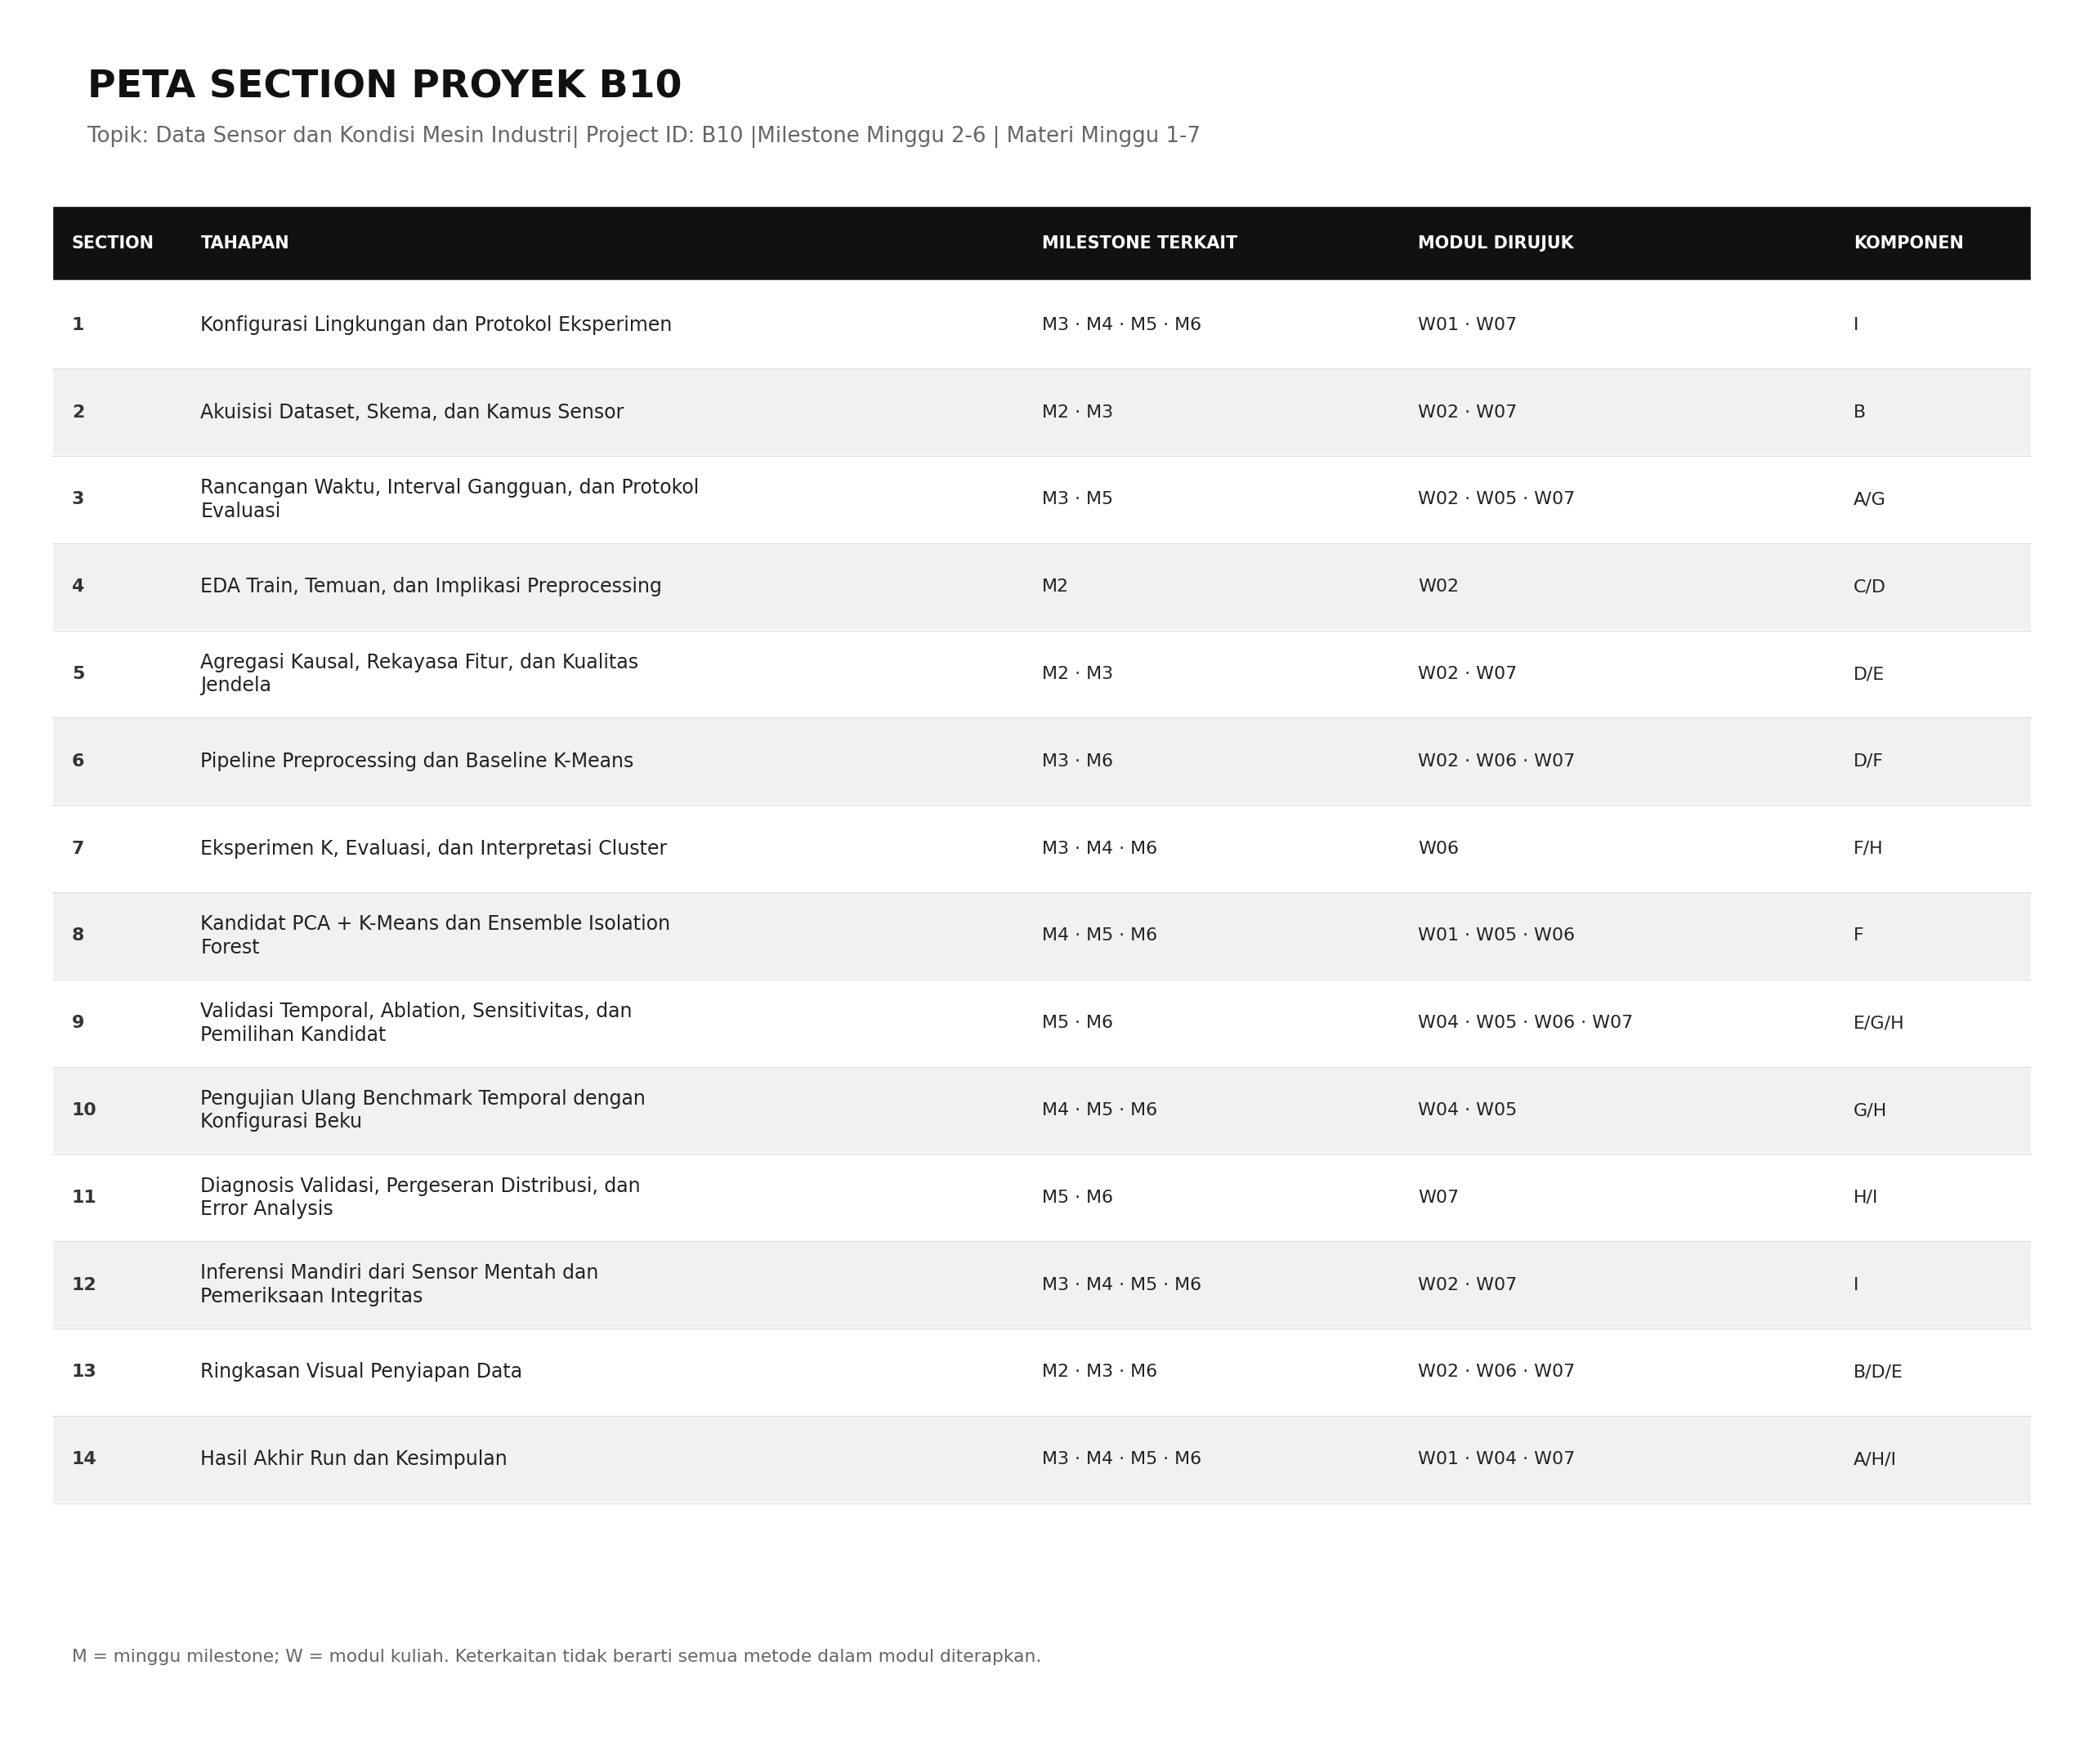

Section,Tahapan,Milestone terkait,Modul dirujuk,Komponen
1,Konfigurasi Lingkungan dan Protokol Eksperimen,M3 · M4 · M5 · M6,W01 · W07,I
2,"Akuisisi Dataset, Skema, dan Kamus Sensor",M2 · M3,W02 · W07,B
3,"Rancangan Waktu, Interval Gangguan, dan Protokol Evaluasi",M3 · M5,W02 · W05 · W07,A/G
4,"EDA Train, Temuan, dan Implikasi Preprocessing",M2,W02,C/D
5,"Agregasi Kausal, Rekayasa Fitur, dan Kualitas Jendela",M2 · M3,W02 · W07,D/E
6,Pipeline Preprocessing dan Baseline K-Means,M3 · M6,W02 · W06 · W07,D/F
7,"Eksperimen K, Evaluasi, dan Interpretasi Cluster",M3 · M4 · M6,W06,F/H
8,Kandidat PCA + K-Means dan Ensemble Isolation Forest,M4 · M5 · M6,W01 · W05 · W06,F
9,"Validasi Temporal, Ablation, Sensitivitas, dan Pemilihan Kandidat",M5 · M6,W04 · W05 · W06 · W07,E/G/H
10,Pengujian Ulang Benchmark Temporal dengan Konfigurasi Beku,M4 · M5 · M6,W04 · W05,G/H


In [6]:
import re
import html
import io
import textwrap

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display, HTML, Image

# ============================================================
# DATA PETA SECTION
# ============================================================

B10_VIZ_MARKDOWN = r"""
### Peta Section, Isi dan Keluaran, Keterkaitan Milestone Minggu 2-6, serta Penerapan Materi Minggu 1-7

| Section | Tahapan | Isi dan Keluaran | Dasar yang Dipenuhi | Keterkaitan Milestone Minggu 2-6 | Materi Kuliah Minggu 1-7 yang Diterapkan |
| :---: | :--- | :--- | :--- | :--- | :--- |
| 1 | Konfigurasi Lingkungan dan Protokol Eksperimen | Impor pustaka, konfigurasi parameter, random seed, versi lingkungan, identitas run, dan aturan pemilihan kandidat. | I: dokumentasi eksperimen. | Mendukung Minggu 3-6: menyiapkan lingkungan pemodelan dan evaluasi. Memenuhi bagian dokumentasi Minggu 6 melalui pencatatan parameter dan random seed. | **W01 hal. 32:** penggunaan Python, Jupyter/Colab, dan scikit-learn. **W07 hal. 45-46 dan 48:** penetapan seed, pencatatan versi lingkungan, identitas eksperimen, serta konfigurasi yang dapat dijalankan kembali. |
| 2 | Akuisisi Dataset, Skema, dan Kamus Sensor | Akuisisi CSV/ZIP lokal atau unduhan resmi, SHA-256 sumber, struktur data, tipe variabel, kamus sensor, dan audit kualitas data mentah. | B: dataset dan data understanding. | Memenuhi bagian data understanding Minggu 2: sumber, jumlah baris dan kolom, tipe data, contoh observasi, deskripsi variabel, dan kualitas data. Mendukung pemeriksaan ulang dataset pada Minggu 3. | **W02 hal. 7-10 dan 17-20:** pemeriksaan struktur, tipe variabel, contoh data, dan missing values. **W07 hal. 45:** data versioning, diterapkan melalui identitas berkas dan SHA-256. Pembacaan ZIP, unduhan UCI, dan kamus sensor merupakan implementasi sesuai sumber dataset. |
| 3 | Rancangan Waktu, Interval Gangguan, dan Protokol Evaluasi | Pembagian temporal train-kalibrasi-validasi-uji, empat interval laporan gangguan, definisi label pembanding, dan protokol evaluasi. | A/G: perumusan masalah dan desain evaluasi. | Memenuhi bagian pemisahan data dan pencegahan leakage pada Minggu 3. Memenuhi audit strategi validasi Minggu 5 melalui penjelasan fungsi setiap bagian data dan penggunaannya dalam pemilihan kandidat. | **W02 hal. 41 dan 45-47:** pembagian data dan pencegahan leakage. **W05 slide 13-14:** fungsi train-validation-test dan pemisahan proses belajar dari evaluasi. **W07 hal. 32-35:** temporal leakage, waktu ketersediaan fitur, dan validasi yang sesuai untuk time series. Kalibrasi terpisah dan embargo merupakan penyesuaian protokol proyek. |
| 4 | EDA Train, Temuan, dan Implikasi Preprocessing | Statistik sensor train, histogram, boxplot, scatter plot, correlation heatmap, distribusi digital, serta tabel temuan, bukti, interpretasi, dan implikasi preprocessing. | C/D: EDA, temuan awal, dan dasar preprocessing. | Memenuhi EDA Minggu 2: menyajikan statistik dan visualisasi relevan serta minimal tiga temuan yang disertai bukti, interpretasi, dan implikasi preprocessing. | **W02 hal. 7-16:** alur EDA, statistik deskriptif, visualisasi, korelasi, dan hubungan temuan dengan preprocessing. **W02 hal. 21-24:** pemeriksaan nilai ekstrem menggunakan IQR dan pemilihan penanganannya sesuai konteks; nilai ekstrem dipertahankan karena dapat mengandung sinyal anomali. |
| 5 | Agregasi Kausal, Rekayasa Fitur, dan Kualitas Jendela | Agregasi jendela lima menit, pemeriksaan kelengkapan dan jeda, alasan eksklusi, pembentukan 25 fitur termasuk tiga fitur rekayasa, serta pemisahan matriks fitur. | D/E: preprocessing dan initial feature engineering. | Memenuhi initial feature engineering dan initial data pipeline Minggu 2 melalui pembentukan minimal dua fitur baru. Memenuhi preprocessing Minggu 3 melalui pengolahan jendela dan penyusunan fitur tanpa informasi masa depan. | **W02 hal. 36-38:** pengembangan fitur berdasarkan hubungan variabel dan pengetahuan domain. **W07 hal. 33 dan 35:** audit waktu ketersediaan fitur dan pencegahan temporal leakage. Mean/std, duty digital, selisih tekanan, proporsi beban motor, rentang suhu, serta aturan kualitas jendela merupakan adaptasi untuk data sensor MetroPT-3. |
| 6 | Pipeline Preprocessing dan Baseline K-Means | Pipeline train-only yang memuat imputasi, filter fitur konstan, scaling, baseline K-Means, kalibrasi ambang, serta contoh skor dan alarm persisten. | D/F: preprocessing, baseline, dan model awal. | Memenuhi baseline unsupervised Minggu 3: algoritma, preprocessing, training, dan contoh keluaran. Mendukung Minggu 6 melalui scaling dan baseline clustering yang terdokumentasi. | **W02 hal. 19-20, 31-35, dan 47-49:** SimpleImputer median, StandardScaler, dan Pipeline yang dipelajari hanya pada train. **W06 hal. 8-11:** K-Means, jarak ke centroid, sensitivitas skala, k-means++, dan n_init. **W07 hal. 8:** seleksi fitur metode filter menggunakan VarianceThreshold. Kalibrasi P99 dan persistensi alarm adalah keputusan proyek. |
| 7 | Eksperimen K, Evaluasi, dan Interpretasi Cluster | Eksperimen K=2-6, elbow, silhouette, Davies-Bouldin, Calinski-Harabasz, ukuran cluster, profil sensor, dan interpretasi pola operasi. | F/H: eksperimen model dan analisis hasil awal. | Memenuhi evaluasi unsupervised Minggu 3 melalui jumlah, ukuran, dan karakteristik cluster. Memenuhi pengembangan baseline Minggu 4 dan eksperimen clustering Minggu 6 melalui pengujian K, evaluasi, dan profil cluster. | **W06 hal. 11-14 dan 32:** inisialisasi K-Means, pemilihan K, elbow, silhouette, Davies-Bouldin, Calinski-Harabasz, serta profil cluster dalam satuan asli. Silhouette dibandingkan pada ruang fitur yang sama; nomor atau ukuran cluster tidak dijadikan label kerusakan. |
| 8 | Kandidat PCA + K-Means dan Ensemble Isolation Forest | Pipeline kandidat PCA + K-Means dan Isolation Forest, konfigurasi model, jumlah komponen PCA, explained variance ratio, dan varians kumulatif. | F: baseline dan initial candidate models. | Memenuhi kandidat tambahan Minggu 4, eksperimen ensemble yang relevan pada Minggu 5, serta penerapan PCA dan pemeriksaan varians pada Minggu 6. | **W01 hal. 18:** pengenalan Isolation Forest sebagai kandidat deteksi anomali. **W05 slide 3 dan 5:** konsep ensemble sebagai gabungan model dasar. **W06 hal. 22-25, 28, dan 31:** PCA, scaling sebelum PCA, Pipeline train-only, varians kumulatif, PCA + K-Means, dan pemilihan jumlah komponen. Detail pohon isolasi merupakan pengayaan implementasi, bukan implementasi Random Forest pada modul. |
| 9 | Validasi Temporal, Ablation, Sensitivitas, dan Pemilihan Kandidat | Lima fold temporal, skor tiap fold, rata-rata dan simpangan baku, perbandingan kandidat, ablation fitur, sensitivitas ambang dan persistensi, serta pembekuan pilihan berdasarkan validasi. | E/G/H: evaluasi fitur, desain evaluasi, dan analisis eksperimen. | Memenuhi validasi dan kestabilan Minggu 5 melalui lima fold, variasi skor, dan perbandingan baseline-ensemble. Memenuhi evaluasi tanpa/dengan PCA Minggu 6. Ablation dan sensitivitas menjadi eksperimen tambahan. | **W05 slide 13-16:** pemisahan peran data, validasi silang, rata-rata, dan simpangan baku. **W07 hal. 20 dan 35:** perbandingan pada split/fold yang sama dan penggunaan TimeSeriesSplit untuk data berurutan. **W06 hal. 27-28:** pengujian manfaat PCA melalui tugas hilir. **W04 hal. 64 dan 72:** trade-off threshold dan pemilihan metrik. Ablation adalah perbandingan set fitur, bukan penerapan RFE. |
| 10 | Pengujian Ulang Benchmark Temporal dengan Konfigurasi Beku | Tabel metrik proxy benchmark, confusion matrix, cakupan gangguan, deteksi interval, keterlambatan deteksi, dan timeline sensor, skor, serta alarm. | G/H: desain evaluasi dan analisis hasil awal. | Mendukung evaluasi dan perbandingan hasil Minggu 4-6. Mendukung audit validasi Minggu 5 dengan mempertahankan konfigurasi hasil pemilihan validasi dan menjelaskan status benchmark yang telah diperiksa sebelumnya. | **W04 hal. 52-60 dan 65-72:** confusion matrix, TP/TN/FP/FN, accuracy, precision, recall, F1, ROC-AUC, serta alasan pemilihan metrik. **W05 slide 13-14 dan 18:** pemisahan evaluasi dan kewaspadaan terhadap accuracy pada pembanding yang timpang. Metrik diterapkan sebagai proxy terhadap laporan gangguan; evaluasi interval dan keterlambatan merupakan pengayaan proyek. |
| 11 | Diagnosis Validasi, Pergeseran Distribusi, dan Error Analysis | Error slicing berdasarkan kondisi beban, contoh kesalahan, episode alarm, deviasi fitur, diagnosis pergeseran distribusi, dan keterbatasan model. | H/I: analisis hasil dan dasar rencana pengembangan. | Memenuhi diagnosis awal dan keputusan perbaikan Minggu 5 melalui pemeriksaan kesalahan dan karakteristik data. Mendukung Minggu 6 melalui pembahasan keterbatasan hasil dan metode. | **W07 hal. 37-39 dan 41-42:** pemeriksaan sampel yang salah, confusion matrix sebagai awal analisis, error slicing berdasarkan subgrup, dan perbaikan berbasis pola kesalahan. Pengelompokan kondisi beban adalah adaptasi domain; deviasi fitur dan pergeseran mean merupakan diagnosis deskriptif, bukan feature importance kausal. |
| 12 | Inferensi Mandiri dari Sensor Mentah dan Pemeriksaan Integritas | Inferensi sensor mentah menjadi fitur, skor, dan alarm tanpa refit; penyimpanan state antarbatch; serialisasi model; serta pemeriksaan konsistensi dan kausalitas fitur. | I: dokumentasi dan reproduksibilitas. | Mendukung dokumentasi eksperimen Minggu 3-6 melalui contoh penggunaan model dan pemeriksaan konsistensi pipeline. Inferensi mandiri dan pengujian antarbatch merupakan pengayaan teknis. | **W02 hal. 48-49:** konsistensi transformasi pada data baru dan penyimpanan Pipeline untuk digunakan kembali. **W07 hal. 44-48:** pengujian reproduksibilitas dan konsistensi hasil. Serialisasi menggunakan joblib, inferensi raw-to-feature, state antarbatch, dan pemeriksaan batas alarm adalah pengembangan teknis untuk membuktikan konsistensi implementasi. |
| 13 | Ringkasan Visual Penyiapan Data | Ringkasan perubahan unit observasi, jumlah jendela setiap split, visualisasi sebelum-sesudah standardisasi, serta perubahan dimensi fitur setelah filter dan PCA. | B/D/E: pemahaman data, preprocessing, dan transformasi fitur. | Mendukung persiapan data Minggu 2 dan preprocessing Minggu 3. Memenuhi bagian perbandingan dimensi Minggu 6 melalui visualisasi fitur awal, fitur setelah filter, dan komponen PCA yang dipertahankan. | **W02 hal. 31-35:** alasan scaling dan visualisasi sebelum-sesudah standardisasi. **W06 hal. 21 dan 24-25:** perbedaan feature selection dan feature extraction, kompresi dimensi, serta varians yang dipertahankan. **W07 hal. 8:** pengurangan fitur melalui filter konstan. |
| 14 | Hasil Akhir Run dan Kesimpulan  | Ringkasan hasil aktual, perbandingan kontrol dan kandidat, bukti deteksi interval, ketercapaian tujuan, dan keterbatasan| A/H/I: keterkaitan tujuan, analisis hasil, dan rencana pengembangan. | Memenuhi temuan awal Minggu 3-4, keputusan perbaikan Minggu 5, serta ringkasan temuan Minggu 6 melalui pembahasan beberapa metrik, keterbatasan, dan rencana lanjutan berdasarkan bukti. | **W01 hal. 23, 25-26, dan 36:** menghubungkan masalah, tujuan, evaluasi, dan pengembangan proyek. **W04 hal. 70-72:** mempertimbangkan biaya kesalahan dan beberapa metrik. **W07 hal. 20, 41-42, dan 47:** perbandingan model yang adil, tindak lanjut error analysis, serta dokumentasi batas penggunaan. Kontrol tanpa alarm merupakan adaptasi pembanding sederhana, bukan pemanggilan DummyClassifier. |

**Keterangan Komponen Laporan:** A = Problem formulation; B = Dataset dan data understanding; C = EDA dan initial findings; D = Preprocessing; E = Initial feature engineering; F = Baseline dan initial candidate models; G = Evaluation design; H = Initial results and analysis; I = Documentation and next plan.

**Keterangan Rujukan Materi:** W01 = Pengantar Machine Learning dan Data Science Pipeline; W02 = Data Understanding, Pre-processing, and Feature Engineering; W03 = Supervised Learning Regresi; W04 = Supervised Learning Klasifikasi; W05 = Ensemble Learning, Validation Strategy, dan Imbalanced Data; W06 = Unsupervised Learning dan Dimensionality Reduction; W07 = Feature Selection, Model Diagnosis, dan Error Analysis.

**Penerapan Materi Pada Proyek UTS:**
- **W01:** diterapkan pada pemilihan pendekatan unsupervised, problem framing, alur proyek, penggunaan tools, dan dokumentasi.
- **W02:** diterapkan pada data understanding, EDA, imputasi median, pemeriksaan IQR, StandardScaler, feature engineering, pemisahan data, dan Pipeline. Encoding kategorikal, MinMaxScaler, serta transformasi log tidak diterapkan.
- **W03:** algoritma regresi linear/multiple/polynomial, Ridge, Lasso, gradient descent, serta metrik regresi MAE/MSE/RMSE/R² tidak diterapkan karena proyek tidak memprediksi target numerik berlabel. Skor jarak kuadrat K-Means tidak diposisikan sebagai evaluasi regresi.
- **W04:** konsep confusion matrix, precision, recall, F1, ROC-AUC, serta trade-off threshold diadaptasi untuk evaluasi proxy. Logistic Regression, KNN, DecisionTreeClassifier, dan RandomForestClassifier tidak dilatih dalam notebook.
- **W05:** konsep ensemble, pemisahan train-validation-test, pencegahan leakage, variasi skor validasi, dan keterbatasan accuracy diterapkan sesuai konteks. Validasi menggunakan TimeSeriesSplit, bukan KFold acak atau StratifiedKFold. SMOTE, undersampling, class weighting, boosting, dan stacking tidak diterapkan.
- **W06:** K-Means, k-means++, eksperimen K, elbow, silhouette, Davies-Bouldin, Calinski-Harabasz, profil cluster, dan PCA diterapkan. Hierarchical clustering, DBSCAN, t-SNE, UMAP, ARI, serta NMI tidak digunakan.
- **W07:** VarianceThreshold, perbandingan model pada data yang sama, audit leakage, error slicing, pencatatan eksperimen, model card, dan reproduksibilitas diterapkan. RFE, seleksi embedded, permutation importance, serta learning curve tidak diterapkan; profil deviasi fitur tidak diklaim sebagai feature importance.
"""

# ============================================================
# FUNGSI PEMBACA DATA
# ============================================================

def b10_viz_parse(source):
    lines = source.splitlines()
    rows, end = [], None
    headers = None

    for index, line in enumerate(lines):
        if not line.strip().startswith("|"):
            continue

        fields = [
            value.strip()
            for value in line.strip().strip("|").split("|")
        ]

        if fields[0] == "Section":
            headers = fields

        if fields[0].isdigit():
            if len(fields) != 6:
                raise ValueError(
                    "Setiap baris harus mempunyai enam kolom."
                )

            rows.append(fields)
            end = index

    if [int(row[0]) for row in rows] != list(range(1, 15)):
        raise ValueError(
            "Peta wajib memuat Section 1 sampai 14 secara berurutan."
        )

    notes = "\n".join(lines[end + 1:]).strip()
    return headers, rows, notes


def b10_viz_weeks(text):
    weeks = set()

    for match in re.finditer(
        r"Minggu\s+(\d)(?:\s*-\s*(\d))?",
        text
    ):
        lo = int(match.group(1))
        hi = int(match.group(2) or lo)
        weeks.update(range(lo, hi + 1))

    return sorted(weeks)


def b10_viz_modules(text):
    return sorted(set(re.findall(r"\bW0[1-7]\b", text)))


def b10_viz_report(text):
    match = re.match(r"([A-I](?:/[A-I])*):", text)
    return match.group(1) if match else "Dokumentasi"


def b10_viz_rich(text):
    safe = html.escape(text)

    safe = re.sub(
        r"\*\*(.+?)\*\*",
        r"<strong>\1</strong>",
        safe
    )

    return re.sub(
        r"`([^`]+)`",
        r"<code>\1</code>",
        safe
    )


B10_VIZ_HEADERS, B10_VIZ_ROWS, B10_VIZ_NOTES = (
    b10_viz_parse(B10_VIZ_MARKDOWN)
)

B10_VIZ_SUMMARY = [
    [
        row[0],
        row[1],
        " · ".join(
            "M" + str(week)
            for week in b10_viz_weeks(row[4])
        ),
        " · ".join(b10_viz_modules(row[5])),
        b10_viz_report(row[3])
    ]
    for row in B10_VIZ_ROWS
]

# ============================================================
# TABEL HTML DAN RINCIAN PER SECTION
# ============================================================

def b10_viz_make_html():
    summary_rows = []
    details = []

    labels = [
        "Isi dan keluaran",
        "Dasar yang dipenuhi",
        "Milestone Minggu 2-6",
        "Materi kuliah Minggu 1-7"
    ]

    for row, short in zip(B10_VIZ_ROWS, B10_VIZ_SUMMARY):
        summary_rows.append(
            "<tr>"
            "<td class='number'>" + short[0] + "</td>"
            "<td><a href='#b10-detail-" + short[0] + "'>"
            + html.escape(short[1])
            + "</a></td>"
            "<td>" + html.escape(short[2]) + "</td>"
            "<td>" + html.escape(short[3]) + "</td>"
            "<td>" + html.escape(short[4]) + "</td>"
            "</tr>"
        )

        fields = "".join(
            "<div class='field'>"
            "<div class='field-label'>" + label + "</div>"
            "<div>" + b10_viz_rich(value) + "</div>"
            "</div>"
            for label, value in zip(labels, row[2:])
        )

        open_state = " open" if row[0] == "1" else ""

        details.append(
            "<details id='b10-detail-"
            + row[0] + "'"
            + open_state
            + ">"
            "<summary>"
            "<span class='pill'>Section "
            + row[0]
            + "</span> "
            + html.escape(row[1])
            + "</summary>"
            "<div class='detail-body'>"
            + fields
            + "</div>"
            "</details>"
        )

    notes = []

    for line in B10_VIZ_NOTES.splitlines():
        if line.strip():
            notes.append(
                "<p>"
                + b10_viz_rich(line.removeprefix("- "))
                + "</p>"
            )

    style = """
    #b10-section-map {
        font-family: Arial, sans-serif;
        color: #222222;
        background: #FFFFFF;
        padding: 22px 18px;
        line-height: 1.6;
        font-size: 14px;
        max-width: 1400px;
        margin: auto;
    }

    #b10-section-map * {
        box-sizing: border-box;
    }

    #b10-section-map h2 {
        font-size: 24px;
        line-height: 1.3;
        margin: 0 0 8px;
        color: #111111;
    }

    #b10-section-map h3 {
        color: #000000 !important;
        font-size: 18px;
        margin: 28px 0 10px;
    }

    #b10-section-map .intro {
        color: #666666;
        margin: 0 0 18px;
    }

    #b10-section-map .scroll {
        overflow-x: auto;
    }

    #b10-section-map table {
        border-collapse: collapse;
        width: 100%;
        min-width: 760px;
        font-size: 13px;
    }

    #b10-section-map th {
        background: #111111;
        color: #FFFFFF;
        padding: 12px 10px;
        text-align: left;
    }

    #b10-section-map td {
        padding: 11px 10px;
        border-bottom: 1px solid #DDDDDD;
        vertical-align: top;
    }

    #b10-section-map tr:nth-child(even) td {
        background: #F5F5F5;
    }

    #b10-section-map .number {
        font-weight: bold;
        text-align: center;
        color: #333333;
    }

    #b10-section-map a {
        color: #333333;
        text-decoration: underline;
    }

    #b10-section-map details {
        margin: 10px 0;
        border: 1px solid #DDDDDD;
        border-radius: 8px;
        overflow: hidden;
    }

    #b10-section-map summary {
        background: #EEEEEE;
        padding: 12px 14px;
        font-weight: bold;
        cursor: pointer;
    }

    #b10-section-map .pill {
        display: inline-block;
        background: #111111;
        color: #FFFFFF;
        padding: 2px 8px;
        border-radius: 4px;
        margin-right: 9px;
        font-size: 12px;
    }

    #b10-section-map .detail-body {
        padding: 4px 16px 12px;
    }

    #b10-section-map .field {
        display: grid;
        grid-template-columns: 190px minmax(0, 1fr);
        gap: 16px;
        padding: 12px 0;
        border-bottom: 1px solid #EEEEEE;
    }

    #b10-section-map .field:last-child {
        border-bottom: 0;
    }

    #b10-section-map .field-label {
        font-weight: bold;
        color: #333333;
    }

    #b10-section-map .notes {
        font-size: 13px;
        border-top: 2px solid #DDDDDD;
        margin-top: 24px;
    }

    #b10-section-map code {
        background: #EEEEEE;
        padding: 1px 4px;
        overflow-wrap: anywhere;
    }

    @media (max-width: 640px) {
        #b10-section-map {
            padding: 14px 8px;
        }

        #b10-section-map h2 {
            font-size: 20px;
        }

        #b10-section-map .field {
            grid-template-columns: 1fr;
            gap: 3px;
        }
    }
    """

    body = (
        "<section id='b10-section-map'>"
        "<h2>Peta Section Proyek B10</h2>"
        "<p class='intro'>"
        "Milestone Minggu 2-6 · "
        "Materi kuliah Minggu 1-7 · "
        "Section 1-14<br>"
        "M = minggu milestone; W = modul kuliah. "
        "</p>"
        "<div class='scroll'>"
        "<table>"
        "<thead>"
        "<tr>"
        "<th>Section</th>"
        "<th>Tahapan</th>"
        "<th>Milestone terkait</th>"
        "<th>Modul dirujuk</th>"
        "<th>Komponen</th>"
        "</tr>"
        "</thead>"
        "<tbody>"
        + "".join(summary_rows)
        + "</tbody>"
        "</table>"
        "</div>"
        "<h3>Rincian penerapan setiap section</h3>"
        + "".join(details)
        + "<div class='notes'>"
        "<h3>Keterangan dan batas penerapan</h3>"
        + "".join(notes)
        + "</div>"
        "</section>"
    )

    return style, body

# ============================================================
# DESAIN WARNA
# ============================================================

def b10_viz_overview():
    colors = {
        "black": "#111111",
        "gray": "#333333",
        "pale": "#F1F1F1",
        "ink": "#222222"
    }

    fig, ax = plt.subplots(figsize=(15, 12.7))
    fig.patch.set_facecolor("white")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    ax.text(
        0.018, 0.975,
        "PETA SECTION PROYEK B10",
        fontsize=20,
        weight="bold",
        color=colors["black"],
        va="top"
    )

    ax.text(
        0.018, 0.942,
        "Topik: Data Sensor dan Kondisi Mesin Industri| "
        "Project ID: B10 |"
        "Milestone Minggu 2-6 | Materi Minggu 1-7",
        fontsize=11,
        color="#666666",
        va="top"
    )

    columns = [
        "SECTION",
        "TAHAPAN",
        "MILESTONE TERKAIT",
        "MODUL DIRUJUK",
        "KOMPONEN"
    ]

    widths = [0.065, 0.425, 0.19, 0.22, 0.10]
    lefts = [0]

    for width in widths[:-1]:
        lefts.append(lefts[-1] + width)

    top = 0.895
    header_h = 0.044
    row_h = 0.0510

    ax.add_patch(
        Rectangle(
            (0, top - header_h),
            1,
            header_h,
            facecolor=colors["black"]
        )
    )

    for x, title in zip(lefts, columns):
        ax.text(
            x + 0.010,
            top - 0.022,
            title,
            fontsize=8.8,
            color="white",
            va="center",
            weight="bold"
        )

    for index, row in enumerate(B10_VIZ_SUMMARY):
        y = top - header_h - index * row_h

        ax.add_patch(
            Rectangle(
                (0, y - row_h),
                1,
                row_h,
                facecolor=(
                    "white"
                    if index % 2 == 0
                    else colors["pale"]
                )
            )
        )

        ax.plot(
            [0, 1],
            [y - row_h, y - row_h],
            color="#DDDDDD",
            lw=0.5
        )

        values = [
            row[0],
            textwrap.fill(row[1], width=48),
            textwrap.fill(row[2], width=19),
            textwrap.fill(row[3], width=24),
            textwrap.fill(row[4], width=13)
        ]

        for col, (x, value) in enumerate(zip(lefts, values)):
            ax.text(
                x + 0.010,
                y - row_h / 2,
                value,
                fontsize=9.4 if col != 1 else 10,
                color=(
                    colors["gray"]
                    if col == 0
                    else colors["ink"]
                ),
                va="center",
                linespacing=1.25,
                weight="bold" if col == 0 else "normal"
            )

    ax.text(
        0.01, 0.052,
        "M = minggu milestone; W = modul kuliah. "
        "Keterkaitan tidak berarti semua metode "
        "dalam modul diterapkan.",
        fontsize=9.2,
        color="#666666",
        va="top"
    )

    fig.subplots_adjust(
        left=0.025,
        right=0.975,
        top=0.985,
        bottom=0.015
    )

    # Gambar diproses di memori untuk ditampilkan di output.
    buffer = io.BytesIO()

    fig.savefig(
        buffer,
        format="png",
        dpi=170,
        facecolor="white"
    )

    payload = buffer.getvalue()

    if not payload.startswith(bytes.fromhex("89504e470d0a1a0a")):
        raise RuntimeError("Gambar ringkasan tidak valid.")

    plt.close(fig)
    buffer.close()

    return payload

# ============================================================
# TAMPILKAN VISUAL DI COLAB
# ============================================================

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "text.parse_math": False
}):
    B10_VIZ_GAMBAR = b10_viz_overview()

B10_VIZ_CSS, B10_VIZ_BODY = b10_viz_make_html()

display(
    Image(
        data=B10_VIZ_GAMBAR,
        width=1100
    )
)

display(
    HTML(
        "<style>"
        + B10_VIZ_CSS
        + "</style>"
        + B10_VIZ_BODY
    )
)

**SECTION 1: Settings Environment**

Seluruh parameter utama dicatat sebelum fit dan sebelum membandingkan kandidat. P99 adalah asumsi referensi, bukan jaminan false positive rate operasional.

In [7]:
import os
import sys
import gc
import json
import time
import hashlib
import zipfile
import shutil
import platform
import warnings
import importlib.util
import inspect
import io
import urllib.request
from pathlib import Path
from contextlib import contextmanager
from datetime import datetime, timezone
import importlib.metadata

import numpy as np
import pandas as pd
import scipy
import sklearn
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from IPython import get_ipython
from threadpoolctl import threadpool_limits
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, calinski_harabasz_score,
    average_precision_score, roc_auc_score, precision_recall_fscore_support,
    accuracy_score, confusion_matrix, precision_recall_curve,
)

SEED = 42
CPU_THREADS = 2
WORK_DIR = Path.cwd()
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUTPUT_DIR = WORK_DIR / "hasil_b10" / ("run_" + RUN_ID)
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
FIGURE_DIR = OUTPUT_DIR / "grafik"
FIGURE_DIR.mkdir()
NOTEBOOK_VERSION = "2.0"
IPY_SHELL = get_ipython()
START_HISTORY_INDEX = len(IPY_SHELL.history_manager.input_hist_raw)-1 if IPY_SHELL is not None else None
REPOSITORY_URL = ""  # Isi URL repo kelompok jika sudah dibuat; tidak mengirim/push apa pun.
EXPERIMENT_LOG = []
EXPORTED_FILES = []
TEST_ALREADY_INSPECTED_IN_PREVIOUS_NOTEBOOK = True

REFERENCE_START = pd.Timestamp("2020-02-01")
FIT_END = pd.Timestamp("2020-02-21")
VALIDATION_START = pd.Timestamp("2020-03-01")
TEST_START = pd.Timestamp("2020-06-01")
WINDOW = "5min"
WINDOW_DELTA = pd.Timedelta(WINDOW)
MIN_OBS_PER_WINDOW = 20
MAX_WITHIN_WINDOW_GAP_SECONDS = 60
MAX_SENSOR_MISSING_FRACTION = 0.10
MOTOR_LOAD_AMPERE = 6.0
SPLIT_GAP_WINDOWS = 1
ALERT_QUANTILE = 0.99
PERSISTENCE_WINDOWS = 3
BASE_K = 3
K_GRID = [2, 3, 4, 5, 6]
KMEANS_N_INIT = 10
IFOREST_TREES = 200
IFOREST_MAX_SAMPLES = 256
PCA_VARIANCE = 0.95
N_TEMPORAL_FOLDS = 5
SENSITIVITY_QUANTILES = [0.975, 0.99, 0.995]
SENSITIVITY_PERSISTENCE = [1, 3, 6]
MODEL_NAMES = ["KMeans", "PCA_KMeans", "IsolationForest"]

ANALOG = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs",
          "Oil_temperature", "Motor_current"]
DIGITAL = ["COMP", "DV_eletric", "Towers", "MPG", "LPS",
           "Pressure_switch", "Oil_level", "Caudal_impulses"]
SENSORS = ANALOG + DIGITAL
UCI_PAGE = "https://archive.ics.uci.edu/dataset/791/metropt+3+dataset"
UCI_ZIP = "https://archive.ics.uci.edu/static/public/791/metropt%2B3%2Bdataset.zip"

np.random.seed(SEED)
# PYTHONHASHSEED harus ditetapkan sebelum proses Python dimulai; seed model/sampling eksplisit.
PROCESS_HASH_SEED = os.environ.get("PYTHONHASHSEED", "tidak ditetapkan saat startup")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)
sns.set_theme(style="whitegrid", palette=["#16425b", "#2a9d8f", "#d76b47"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
COLORS = {"KMeans": "#16425b", "PCA_KMeans": "#2a9d8f", "IsolationForest": "#d76b47"}
VERSIONS = {
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__, "joblib": joblib.__version__,
    "matplotlib": importlib.metadata.version("matplotlib"),
    "seaborn": sns.__version__,
}
FITTED = {}
PREDICTIONS = {}
TEST_CACHE = None
display(pd.DataFrame(VERSIONS.items(), columns=["Pustaka", "Versi"]))
print(f"Project B10 | seed={SEED} | jendela={WINDOW} | CPU threads={CPU_THREADS}")
print(f"Ambang P{100 * ALERT_QUANTILE:.0f} dari kalibrasi; alarm setelah {PERSISTENCE_WINDOWS} jendela berurutan.")


def save_figure(name):
    fig = plt.gcf()
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    payload = buffer.getvalue()
    if len(payload) < 500 or not payload.startswith(bytes.fromhex("89504e470d0a1a0a")):
        raise RuntimeError("Render grafik PNG tidak valid: " + name)
    target = FIGURE_DIR / (name + ".png")
    temporary = target.with_suffix(".png.tmp")
    temporary.write_bytes(payload)
    temporary.replace(target)
    if target.read_bytes() != payload:
        raise IOError("Berkas grafik tidak sama dengan render: " + name)
    plt.show()
    plt.close(fig)

display(Markdown(
    f"**Run:** `{RUN_ID}`; Python hash seed startup: `{PROCESS_HASH_SEED}`. "
    "Pemilihan utama: AP proxy validasi, tie-break event recall, F1, nama model. "
    "Kualitas pemeringkatan dan kualitas alarm dinilai terpisah. "
    "Accuracy hanya diagnostik karena pembanding sangat tidak seimbang dan tidak lengkap."
))

,Pustaka,Versi
0,python,3.13.18
1,numpy,2.1.3
2,pandas,2.2.3
3,scipy,1.16.3
4,scikit-learn,1.6.1
5,joblib,1.6.0
6,matplotlib,3.10.0
7,seaborn,0.13.2


Project B10 | seed=42 | jendela=5min | CPU threads=2
Ambang P99 dari kalibrasi; alarm setelah 3 jendela berurutan.


**Run:** `20261029T192818_729703Z`; Python hash seed startup: `tidak ditetapkan saat startup`. Pemilihan utama: AP proxy validasi, tie-break event recall, F1, nama model. Kualitas pemeringkatan dan kualitas alarm dinilai terpisah. Accuracy hanya diagnostik karena pembanding sangat tidak seimbang dan tidak lengkap.

**SECTION 2: Akuisisi dataset, skema, dan kamus sensor**

Angka ukuran dan resolusi berasal dari CSV yang dibaca; metadata sumber yang berbeda disimpan sebagai perbedaan dokumentasi.

In [8]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

DATA_PATH = "" # Ditambahkan untuk mencegah NameError

def resolve_source():
    if DATA_PATH:
        chosen = Path(DATA_PATH).expanduser()
        if not chosen.is_file():
            raise FileNotFoundError(f"DATA_PATH tidak ditemukan: {chosen}")
        return chosen
    candidates = []
    for parent in [WORK_DIR, WORK_DIR / "upload", Path("/content"), WORK_DIR / "data"]:
        if not parent.is_dir():
            continue
        for path in parent.iterdir():
            name = path.name.lower()
            if path.is_file() and ((name.startswith("metropt3(aircompressor)") and name.endswith(".csv"))
                                   or (name.startswith("metropt+3+dataset") and name.endswith(".zip"))):
                candidates.append(path.resolve())
    candidates = sorted(set(candidates))
    csvs = [p for p in candidates if p.suffix.lower() == ".csv"]
    preferred = csvs if csvs else candidates
    if len(preferred) == 1:
        return preferred[0]
    if len(preferred) > 1:
        raise ValueError("Lebih dari satu sumber ditemukan; isi DATA_PATH secara eksplisit: "
                         + ", ".join(str(p) for p in preferred))
    target = WORK_DIR / "metropt+3+dataset.zip"
    partial = target.with_suffix(".zip.part")
    print("Berkas lokal tidak ditemukan. Mengunduh ZIP resmi UCI (~208 MiB)...")
    try:
        request = urllib.request.Request(UCI_ZIP, headers={"User-Agent": "MetroPT3-B10-UTS/1.0"})
        with urllib.request.urlopen(request, timeout=180) as response, partial.open("wb") as dest:
            shutil.copyfileobj(response, dest, length=1024 * 1024)
        if not zipfile.is_zipfile(partial):
            raise ValueError("Respons unduhan bukan arsip ZIP yang valid.")
        partial.replace(target)
        return target
    except Exception as exc:
        partial.unlink(missing_ok=True)
        raise RuntimeError("Unduhan UCI gagal. Unggah ZIP/CSV melalui panel Files, isi DATA_PATH, lalu jalankan ulang Section 2.") from exc

SOURCE_PATH = resolve_source()
@contextmanager
def open_source_csv(path):
    if Path(path).suffix.lower() == ".zip":
        with zipfile.ZipFile(path) as archive:
            members = [n for n in archive.namelist()
                       if Path(n).name.lower() == "metropt3(aircompressor).csv"]
            if not members:
                members = [n for n in archive.namelist() if n.lower().endswith(".csv")]
            if len(members) != 1:
                raise ValueError(f"Harus ada satu CSV MetroPT-3; ditemukan: {members}")
            with archive.open(members[0]) as stream:
                yield stream
    elif Path(path).suffix.lower() == ".csv":
        with Path(path).open("rb") as stream:
            yield stream
    else:
        raise ValueError("Gunakan sumber .zip atau .csv.")

with open_source_csv(SOURCE_PATH) as stream:
    original_columns = pd.read_csv(stream, nrows=0).columns.tolist()
missing_columns = sorted(set(["timestamp"] + SENSORS) - set(original_columns))
if missing_columns:
    raise ValueError(f"Skema berbeda dari MetroPT-3: kolom wajib hilang {missing_columns}")
with open_source_csv(SOURCE_PATH) as stream:
    raw = pd.read_csv(stream, usecols=["timestamp"] + SENSORS,
                      dtype={c: np.float64 for c in SENSORS})
n_original = len(raw)
parsed_time = pd.to_datetime(raw.pop("timestamp"), format="%Y-%m-%d %H:%M:%S", errors="coerce")
bad_timestamps = int(parsed_time.isna().sum())
raw.index = pd.DatetimeIndex(parsed_time, name="timestamp")
original_time_ordered = bool(raw.index[raw.index.notna()].is_monotonic_increasing)
original_missing = raw.isna().sum().astype(int).to_dict()
repeated_sensor_states = int(raw.duplicated(subset=SENSORS).sum())
raw = raw.loc[raw.index.notna()].sort_index(kind="mergesort")
duplicate_timestamps = int(raw.index.duplicated(keep="last").sum())
raw = raw.loc[~raw.index.duplicated(keep="last")]
nonfinite_values = int(np.isinf(raw.to_numpy()).sum())
raw = raw.replace([np.inf, -np.inf], np.nan)
REFERENCE_CADENCE_SECONDS = float(raw.loc[(raw.index >= REFERENCE_START) & (raw.index < FIT_END)].index.to_series().diff().dt.total_seconds().median())
invalid_digital = {}
for column in DIGITAL:
    invalid = raw[column].notna() & ~raw[column].isin([0, 1])
    invalid_digital[column] = int(invalid.sum())
    raw.loc[invalid, column] = np.nan
delta_seconds = raw.index.to_series().diff().dt.total_seconds()
OBSERVED_CADENCE_SECONDS = float(delta_seconds.median())
AUDIT = {
    "source_file": SOURCE_PATH.name, "source_sha256": sha256_file(SOURCE_PATH),
    "source_bytes": SOURCE_PATH.stat().st_size, "original_rows": n_original,
    "original_columns": original_columns, "sensor_count": len(SENSORS),
    "rows_after_timestamp_audit": len(raw), "invalid_timestamps_removed": bad_timestamps,
    "duplicate_timestamps_removed": duplicate_timestamps,
    "infinite_values_to_nan": nonfinite_values, "invalid_digital_to_nan": invalid_digital,
    "missing_sensor_values": raw.isna().sum().astype(int).to_dict(),
    "start": str(raw.index.min()), "end": str(raw.index.max()),
    "median_interval_seconds": OBSERVED_CADENCE_SECONDS,
    "train_cadence_seconds": REFERENCE_CADENCE_SECONDS,
    "original_time_ordered": original_time_ordered,
    "original_missing_by_sensor": original_missing,
    "repeated_sensor_vectors_not_removed": repeated_sensor_states,
    "maximum_gap_seconds": float(delta_seconds.max()),
    "uci_url": UCI_PAGE, "license": "CC BY 4.0",
}
assert raw.index.is_unique and raw.index.is_monotonic_increasing
assert raw.index.min() <= REFERENCE_START and raw.index.max() > TEST_START
display(pd.DataFrame({
    "Atribut": ["Baris CSV", "Kolom CSV termasuk waktu/ID", "Sensor", "Periode",
                "Median interval", "Missing sensor", "Timestamp duplikat"],
    "Hasil": [f"{n_original:,}", len(original_columns), len(SENSORS),
              f"{raw.index.min()} - {raw.index.max()}",
              f"{OBSERVED_CADENCE_SECONDS:g} detik",
              int(raw.isna().sum().sum()), duplicate_timestamps],
}))
display(raw.head(3))
display(delta_seconds.value_counts().head(5).rename_axis("Interval (detik)").to_frame("Jumlah"))

schema_table = pd.DataFrame({"kolom": raw.columns, "dtype": raw.dtypes.astype(str).values,
                             "jenis": ["analog" if c in ANALOG else "digital" for c in raw.columns],
                             "missing_setelah_audit": raw.isna().sum().values,
                             "n_unique": [raw[c].nunique(dropna=True) for c in raw.columns]})
display(schema_table)
source_discrepancies = pd.DataFrame([
    ("Jumlah observasi", "15.169.480 pada PDF deskripsi; 1.516.948 pada laman UCI", f"{len(raw):,} baris setelah audit", "Gunakan ukuran CSV aktual; tidak mengklaim membaca 15 juta baris"),
    ("Resolusi", "PDF/logging asal 1 Hz; UCI atribut menyebut 0,1 Hz", f"{OBSERVED_CADENCE_SECONDS:g} detik; train {REFERENCE_CADENCE_SECONDS:g} detik", "Kelengkapan jendela memakai cadence train; tidak menganggap log asli 1 Hz"),
    ("Rentang waktu", "Februari-Agustus 2020 pada narasi sumber", f"{raw.index.min()} sampai {raw.index.max()}", "Laporkan rentang yang benar-benar terbaca, termasuk ujung September"),
    ("ID laporan", "Nomor #1 ditulis dua kali; catatan maintenance F02 tidak konsisten", "F01-F04 adalah ID internal", "Pertahankan waktu kejadian, jangan menebak koreksi tanggal maintenance"),
], columns=["Aspek", "Metadata sumber", "Bukti CSV/keputusan", "Implikasi"])
display(source_discrepancies)
display(Markdown(
    f"**Hasil audit:** {n_original:,} baris mentah, {len(original_columns)} kolom CSV, "
    f" {len(SENSORS)} sensor; {bad_timestamps} timestamp invalid, {duplicate_timestamps} duplikat timestamp. "
    f"Terdapat {repeated_sensor_states:,} vektor sensor berulang; vektor ini **tidak dihapus**, "
    "karena kondisi operasi yang tetap pada timestamp berbeda adalah observasi yang sah. "
    "ID baris sumber dikecualikan dari model. Audit kualitas global tidak digunakan untuk mempelajari "
    "scaler, imputer, PCA, atau ambang."
))

,Atribut,Hasil
0,Baris CSV,"1,516,948"
1,Kolom CSV termasuk waktu/ID,17
2,Sensor,15
3,Periode,2020-02-01 00:00:00 - 2020-09-01 03:59:50
4,Median interval,10 detik
5,Missing sensor,0
6,Timestamp duplikat,0


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
timestamp,,,,,,,,,,,,,,,
2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


,Jumlah
Interval (detik),
10.0,1337521
9.0,128277
12.0,38321
13.0,7988
11.0,4471


,kolom,dtype,jenis,missing_setelah_audit,n_unique
0,TP2,float64,analog,0,5257
1,TP3,float64,analog,0,3683
2,H1,float64,analog,0,2665
3,DV_pressure,float64,analog,0,2257
4,Reservoirs,float64,analog,0,3682
5,Oil_temperature,float64,analog,0,2462
6,Motor_current,float64,analog,0,1809
7,COMP,float64,digital,0,2
8,DV_eletric,float64,digital,0,2
9,Towers,float64,digital,0,2


,Aspek,Metadata sumber,Bukti CSV/keputusan,Implikasi
0,Jumlah observasi,15.169.480 pada PDF deskripsi; 1.516.948 pada ...,"1,516,948 baris setelah audit",Gunakan ukuran CSV aktual; tidak mengklaim mem...
1,Resolusi,"PDF/logging asal 1 Hz; UCI atribut menyebut 0,...",10 detik; train 10 detik,Kelengkapan jendela memakai cadence train; tid...
2,Rentang waktu,Februari-Agustus 2020 pada narasi sumber,2020-02-01 00:00:00 sampai 2020-09-01 03:59:50,"Laporkan rentang yang benar-benar terbaca, ter..."
3,ID laporan,Nomor #1 ditulis dua kali; catatan maintenance...,F01-F04 adalah ID internal,"Pertahankan waktu kejadian, jangan menebak kor..."


**Hasil audit:** 1,516,948 baris mentah, 17 kolom CSV,  15 sensor; 0 timestamp invalid, 0 duplikat timestamp. Terdapat 57,475 vektor sensor berulang; vektor ini **tidak dihapus**, karena kondisi operasi yang tetap pada timestamp berbeda adalah observasi yang sah. ID baris sumber dikecualikan dari model. Audit kualitas global tidak digunakan untuk mempelajari scaler, imputer, PCA, atau ambang.

In [9]:
sensor_dictionary = pd.DataFrame([
    ("TP2", "Analog", "bar", "Tekanan kompresor"),
    ("TP3", "Analog", "bar", "Tekanan panel pneumatik"),
    ("H1", "Analog", "bar", "Sinyal tekanan pada komponen separator"),
    ("DV_pressure", "Analog", "bar", "Tekanan terkait pembuangan pada pengering udara"),
    ("Reservoirs", "Analog", "bar", "Tekanan reservoir; dibandingkan dengan TP3"),
    ("Oil_temperature", "Analog", "°C", "Suhu oli kompresor"),
    ("Motor_current", "Analog", "A", "Arus motor; dokumentasi menyebut sekitar 0/4/7 A pada mode berbeda"),
    ("COMP", "Digital", "0/1", "Sinyal katup intake"),
    ("DV_eletric", "Digital", "0/1", "Sinyal katup outlet; ejaan asli CSV"),
    ("Towers", "Digital", "0/1", "Status tower pengering"),
    ("MPG", "Digital", "0/1", "Sinyal pengaktifan kompresor"),
    ("LPS", "Digital", "0/1", "Sinyal tekanan rendah"),
    ("Pressure_switch", "Digital", "0/1", "Sinyal pressure switch"),
    ("Oil_level", "Digital", "0/1", "Sinyal level oli"),
    ("Caudal_impulses", "Digital", "0/1", "Sinyal impuls aliran udara"),
], columns=["Variabel", "Jenis", "Satuan", "Makna"])
display(sensor_dictionary)
print("ID baris, timestamp, dan metadata laporan tidak dimasukkan sebagai fitur model.")
print("Timestamp mengikuti sumber apa adanya; zona waktu tidak diasumsikan atau dikonversi.")

,Variabel,Jenis,Satuan,Makna
0,TP2,Analog,bar,Tekanan kompresor
1,TP3,Analog,bar,Tekanan panel pneumatik
2,H1,Analog,bar,Sinyal tekanan pada komponen separator
3,DV_pressure,Analog,bar,Tekanan terkait pembuangan pada pengering udara
4,Reservoirs,Analog,bar,Tekanan reservoir; dibandingkan dengan TP3
5,Oil_temperature,Analog,°C,Suhu oli kompresor
6,Motor_current,Analog,A,Arus motor; dokumentasi menyebut sekitar 0/4/7...
7,COMP,Digital,0/1,Sinyal katup intake
8,DV_eletric,Digital,0/1,Sinyal katup outlet; ejaan asli CSV
9,Towers,Digital,0/1,Status tower pengering


ID baris, timestamp, dan metadata laporan tidak dimasukkan sebagai fitur model.
Timestamp mengikuti sumber apa adanya; zona waktu tidak diasumsikan atau dikonversi.


**SECTION 3: Rancangan waktu, interval gangguan, dan protokol evaluasi**

Fit Februari awal, kalibrasi Februari akhir, validasi Maret-Mei, benchmark Juni-akhir. Embargo satu jendela dipakai secara konservatif; tidak menghilangkan seluruh autokorelasi.

,event_id,nomor_pada_sumber,start,end,jenis
0,F01,#1,2020-04-18 00:00:00,2020-04-18 23:59:00,Air leak
1,F02,#1,2020-05-29 23:30:00,2020-05-30 06:00:00,Air leak
2,F03,#3,2020-06-05 10:00:00,2020-06-07 14:30:00,Air leak
3,F04,#4,2020-07-15 14:30:00,2020-07-15 19:00:00,Air leak


**Ketentuan label:** batas interval mengikuti waktu pada sumber dan bersifat inklusif pada timestamp sampel. Satu jendela diberi label laporan 1 bila mengandung sedikitnya satu sampel dalam interval tersebut. ID F01-F04 adalah ID internal: nomor #1 yang terulang pada sumber tetap dicatat. Catatan maintenance yang bertanggal tidak konsisten tidak dipakai untuk mengubah interval. Label 0 berarti di luar laporan, bukan bukti sehat.

,Bagian,Awal jendela,Batas akhir,Peran
0,Train,2020-02-01 00:00:00,2020-02-21 00:00:00,"Fit imputer, seleksi konstan, scaler, dan model"
1,Calibration,2020-02-21 00:05:00,2020-03-01 00:00:00,Ambang P99; tidak melatih ulang model
2,Validation,2020-03-01 00:05:00,2020-06-01 00:00:00,Perbandingan kandidat dan analisis kesalahan
3,Test,2020-06-01 00:05:00,2020-09-01 04:00:00,"Pengujian ulang benchmark, bukan hold-out baru"


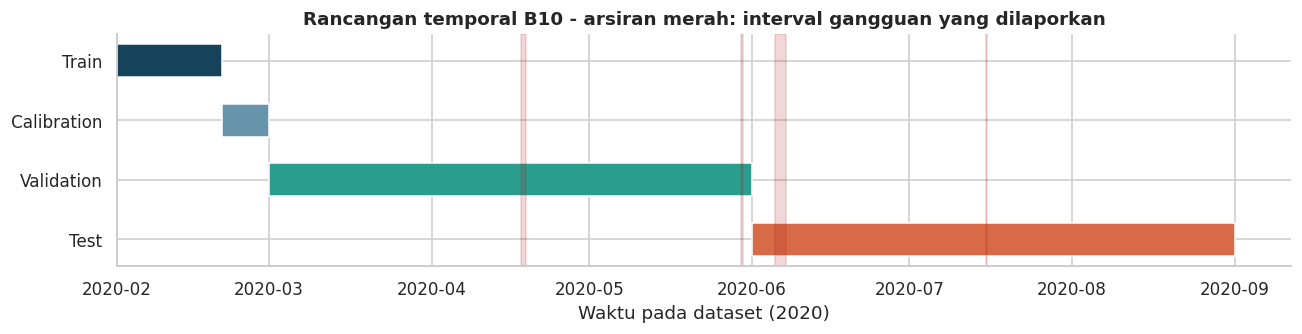

Embargo satu jendela pada setiap pergantian bagian; tidak memakai random split.
Semua label laporan dipisahkan dari matriks fitur yang diberikan ke fit().


,Tahap,Data,Peran
0,Fit,Train Februari awal,"Imputer, filter konstan, scaler, PCA bila ada,..."
1,Kalibrasi,Februari akhir,Kuantil skor; tanpa label gangguan dan tanpa r...
2,Pemilihan,Validasi Maret-Mei,AP proxy utama; event recall dan F1 sebagai ti...
3,Sensitivitas,Validasi saja,"Eksperimen diagnostik, tidak mengganti konfigu..."
4,Benchmark,Juni-akhir; telah terlihat pada versi lama,Semua kandidat beku dievaluasi; bukan sumber t...


In [10]:
FAILURES = pd.DataFrame([
    ("F01", "#1", "2020-04-18 00:00", "2020-04-18 23:59", "Air leak"),
    ("F02", "#1", "2020-05-29 23:30", "2020-05-30 06:00", "Air leak"),
    ("F03", "#3", "2020-06-05 10:00", "2020-06-07 14:30", "Air leak"),
    ("F04", "#4", "2020-07-15 14:30", "2020-07-15 19:00", "Air leak"),
], columns=["event_id", "nomor_pada_sumber", "start", "end", "jenis"])
FAILURES[["start", "end"]] = FAILURES[["start", "end"]].apply(pd.to_datetime)
raw_event_id = pd.Series(np.zeros(len(raw), dtype=np.uint8), index=raw.index, name="event_number")
for number, event in enumerate(FAILURES.itertuples(), start=1):
    raw_event_id.loc[(raw.index >= event.start) & (raw.index <= event.end)] = number
display(FAILURES)
display(Markdown(
    "**Ketentuan label:** batas interval mengikuti waktu pada sumber dan bersifat inklusif pada timestamp sampel. "
    "Satu jendela diberi label laporan 1 bila mengandung sedikitnya satu sampel dalam interval tersebut. "
    "ID F01-F04 adalah ID internal: nomor #1 yang terulang pada sumber tetap dicatat. "
    "Catatan maintenance yang bertanggal tidak konsisten tidak dipakai untuk mengubah interval. "
    "Label 0 berarti di luar laporan, bukan bukti sehat."
))

split_plan = pd.DataFrame([
    ("Train", REFERENCE_START, FIT_END, "Fit imputer, seleksi konstan, scaler, dan model"),
    ("Calibration", FIT_END + WINDOW_DELTA, VALIDATION_START, "Ambang P99; tidak melatih ulang model"),
    ("Validation", VALIDATION_START + WINDOW_DELTA, TEST_START, "Perbandingan kandidat dan analisis kesalahan"),
    ("Test", TEST_START + WINDOW_DELTA, raw.index.max().ceil(WINDOW), "Pengujian ulang benchmark, bukan hold-out baru"),
], columns=["Bagian", "Awal jendela", "Batas akhir", "Peran"])
display(split_plan)
fig, ax = plt.subplots(figsize=(12, 3.2))
for i, row in split_plan.iterrows():
    ax.barh(i, row["Batas akhir"] - row["Awal jendela"], left=row["Awal jendela"],
            height=0.55, color=["#16425b", "#6895ac", "#2a9d8f", "#d76b47"][i])
for event in FAILURES.itertuples():
    ax.axvspan(event.start, event.end, color="#b22222", alpha=0.18)
ax.set_yticks(range(4), split_plan["Bagian"])
ax.invert_yaxis()
ax.set_title("Rancangan temporal B10 - arsiran merah: interval gangguan yang dilaporkan")
ax.set_xlabel("Waktu pada dataset (2020)")
plt.tight_layout()
save_figure("03_pembagian_waktu")
print("Embargo satu jendela pada setiap pergantian bagian; tidak memakai random split.")
print("Semua label laporan dipisahkan dari matriks fitur yang diberikan ke fit().")

evaluation_protocol = pd.DataFrame([
    ("Fit", "Train Februari awal", "Imputer, filter konstan, scaler, PCA bila ada, dan estimator"),
    ("Kalibrasi", "Februari akhir", "Kuantil skor; tanpa label gangguan dan tanpa refit model"),
    ("Pemilihan", "Validasi Maret-Mei", "AP proxy utama; event recall dan F1 sebagai tie-break yang ditetapkan"),
    ("Sensitivitas", "Validasi saja", "Eksperimen diagnostik, tidak mengganti konfigurasi utama dalam run ini"),
    ("Benchmark", "Juni-akhir; telah terlihat pada versi lama", "Semua kandidat beku dievaluasi; bukan sumber tuning atau klaim hold-out baru"),
], columns=["Tahap", "Data", "Peran"])
display(evaluation_protocol)

**Dua definisi waktu yang dibedakan:** `y_report=1` jika jendela mengandung setidaknya satu sampel dalam interval laporan yang inklusif terhadap timestamp sumber; metrik per jendela memakai label ini. Deteksi kejadian memerlukan alarm dari jendela bersampel laporan yang **keputusannya sudah tersedia sebelum/tepat akhir laporan**. Jendela yang baru selesai setelah akhir laporan dapat positif pada metrik jendela, tetapi tidak dihitung sebagai deteksi tepat waktu. Tidak dilakukan point adjustment.

**Metrik:** AP proxy menilai peringkat skor pada pembanding yang jarang, precision/recall/F1 proxy menilai alarm persisten, ROC-AUC/accuracy adalah pendamping; recall kejadian dan keterlambatan dilaporkan bersama episode alarm di luar laporan per 24 jam jendela terpantau. Episode di luar laporan tidak langsung dinyatakan false alarm aktual karena label tidak lengkap. Silhouette/DB/CH hanya menilai struktur cluster, bukan akurasi deteksi kerusakan.

**Cakupan waktu laporan:** denominator adalah seluruh jendela dengan durasi tumpang tindih positif terhadap interval laporan (`window_start < report_end` dan `window_end > report_start`), sedangkan numerator adalah jendela tersebut yang lolos kualitas. Sampel yang kebetulan tepat pada batas akhir masih mengikuti label sumber inklusif, tetapi satu titik di batas tidak menambah durasi cakupan; jendela label positif yang baru selesai sesudah laporan dicatat terpisah.

**SECTION 4: EDA train, temuan, dan implikasi preprocessing**

Grafik distribusi hanya memakai data training. Nilai ekstrem dipertahankan agar tidak menghapus sinyal anomali.

,count,mean,std,min,25%,50%,75%,max,IQR
TP2,151297.0,0.5359,2.1938,-0.030,-0.012,-0.0120,-0.010,10.5440,0.002
TP3,151297.0,8.9636,0.5554,7.324,8.484,8.9400,9.420,10.1640,0.936
H1,151297.0,8.4010,2.1981,-0.030,8.386,8.8580,9.358,10.1580,0.972
DV_pressure,151297.0,-0.0155,0.1010,-0.028,-0.020,-0.0180,-0.016,6.5300,0.004
Reservoirs,151297.0,8.9659,0.5548,7.326,8.488,8.9420,9.422,10.1680,0.934
Oil_temperature,151297.0,56.7739,3.4786,31.975,54.825,57.0500,58.975,69.1500,4.150
Motor_current,151297.0,1.2412,1.9578,0.020,0.035,0.0375,3.705,8.2925,3.670


,nilai_0,nilai_1
COMP,9154,142143
DV_eletric,142141,9156
Towers,4567,146730
MPG,9154,142143
LPS,151296,1
Pressure_switch,115,151182
Oil_level,0,151297
Caudal_impulses,0,151297


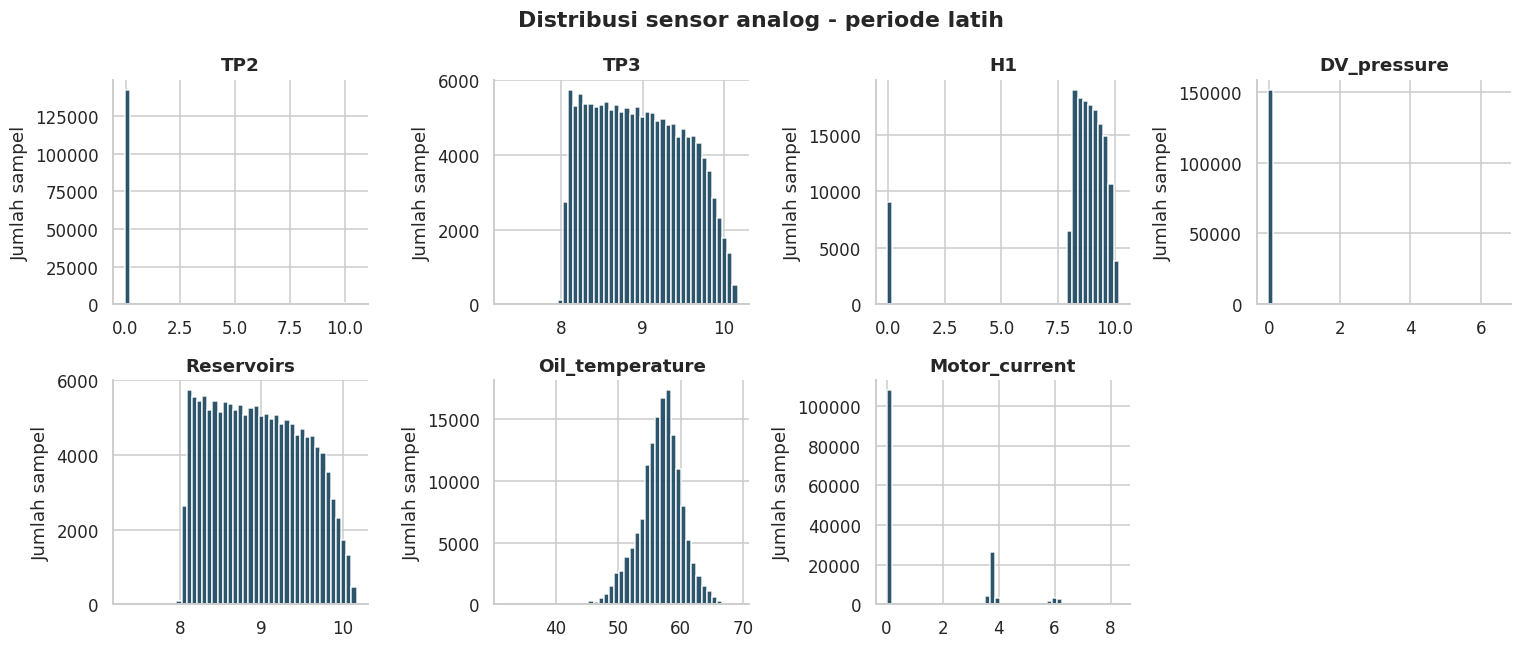

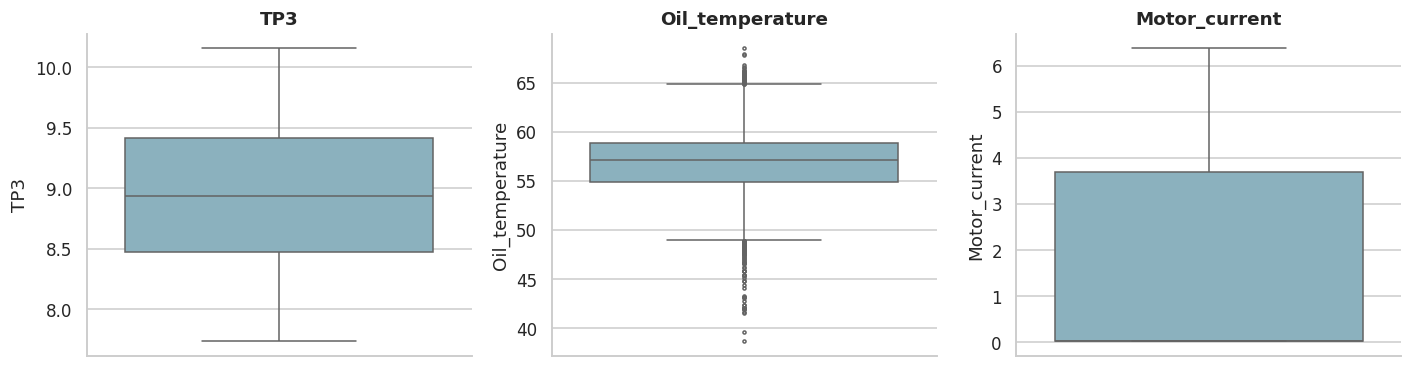

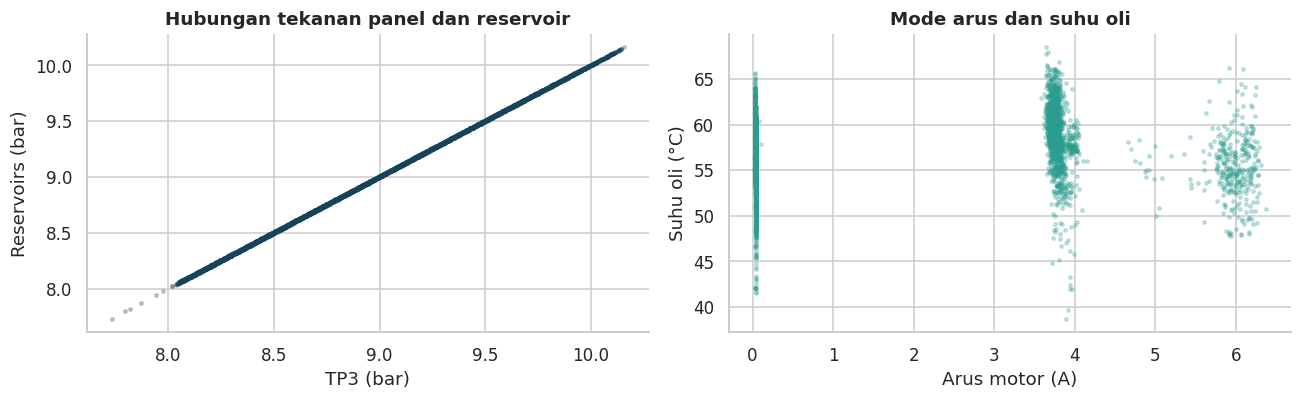

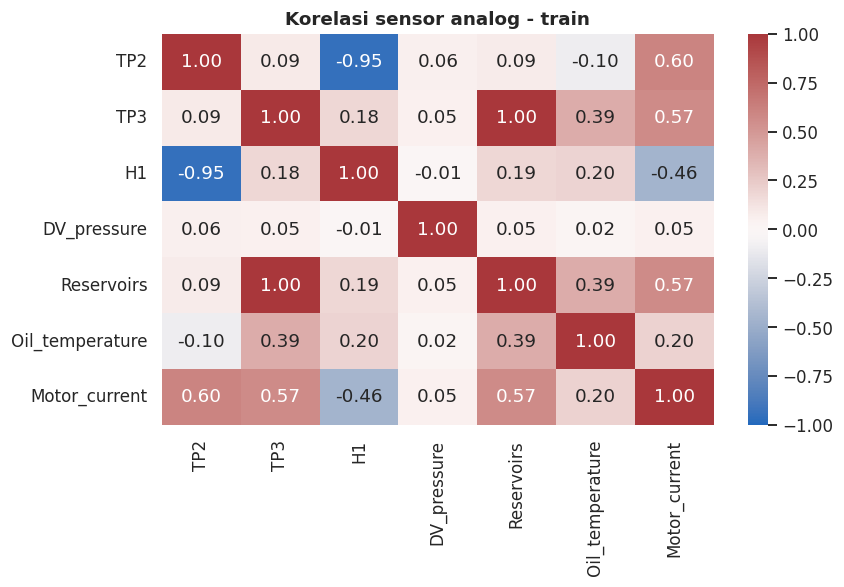

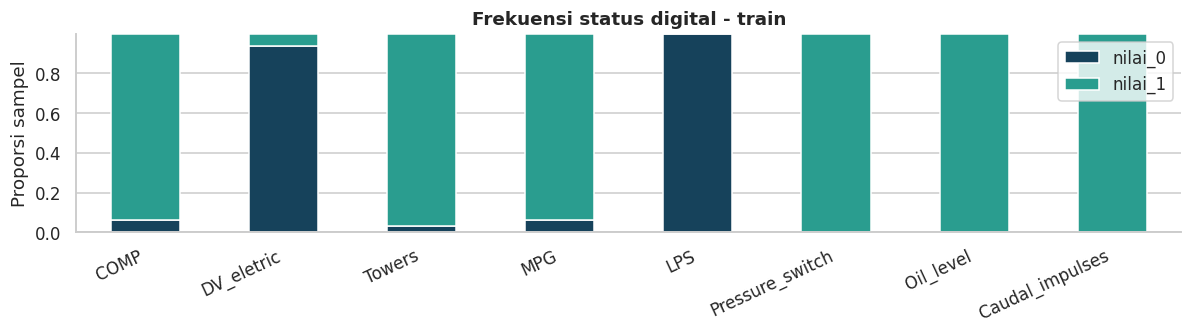

**Interpretasi grafik:** histogram dan boxplot memuat 151,297 sampel train; rata-rata suhu oli 56.77 °C. Scatter dan heatmap menunjukkan korelasi TP3-Reservoirs 0.999991, sehingga selisih tekanan dan PCA relevan untuk diuji. Multimodalitas arus dapat berkaitan dengan mode operasi, bukan otomatis gangguan. Bar digital memperlihatkan sinyal yang konstan atau jarang aktif; perubahan status yang belum muncul di train perlu dicatat sebagai keterbatasan.

In [11]:
raw_train = raw.loc[(raw.index >= REFERENCE_START) & (raw.index < FIT_END)]
train_summary = raw_train[ANALOG].describe().T
train_summary["IQR"] = train_summary["75%"] - train_summary["25%"]
display(train_summary.round(4))
digital_frequency = pd.DataFrame({
    c: raw_train[c].value_counts(dropna=False).reindex([0.0, 1.0], fill_value=0)
    for c in DIGITAL
}).T.rename(columns={0.0: "nilai_0", 1.0: "nilai_1"})
display(digital_frequency)

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for axis, column in zip(axes.flat, ANALOG):
    axis.hist(raw_train[column].dropna(), bins=45, color="#16425b", alpha=0.9)
    axis.set_title(column)
    axis.set_ylabel("Jumlah sampel")
axes.flat[-1].axis("off")
fig.suptitle("Distribusi sensor analog - periode latih", fontweight="bold")
plt.tight_layout()
save_figure("04_eda_01")

sample = raw_train.sample(n=min(6000, len(raw_train)), random_state=SEED)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for axis, column in zip(axes, ["TP3", "Oil_temperature", "Motor_current"]):
    sns.boxplot(y=sample[column], ax=axis, color="#83b5c6", fliersize=2)
    axis.set_title(column)
plt.tight_layout()
save_figure("04_eda_02")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].scatter(sample["TP3"], sample["Reservoirs"], s=5, alpha=0.25, color="#16425b")
axes[0].set(xlabel="TP3 (bar)", ylabel="Reservoirs (bar)", title="Hubungan tekanan panel dan reservoir")
axes[1].scatter(sample["Motor_current"], sample["Oil_temperature"], s=5, alpha=0.25, color="#2a9d8f")
axes[1].set(xlabel="Arus motor (A)", ylabel="Suhu oli (°C)", title="Mode arus dan suhu oli")
plt.tight_layout()
save_figure("04_eda_03")

train_corr = raw_train[ANALOG].corr()
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(train_corr, vmin=-1, vmax=1, center=0, cmap="vlag", annot=True, fmt=".2f", ax=ax)
ax.set_title("Korelasi sensor analog - train")
plt.tight_layout()
save_figure("04_eda_04")
digital_frequency.div(digital_frequency.sum(axis=1), axis=0).plot(
    kind="bar", stacked=True, figsize=(11, 3.2), color=["#16425b", "#2a9d8f"])
plt.ylabel("Proporsi sampel")
plt.title("Frekuensi status digital - train")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
save_figure("04_eda_05")

display(Markdown(
    f"**Interpretasi grafik:** histogram dan boxplot memuat {len(raw_train):,} sampel train; "
    f"rata-rata suhu oli {raw_train.Oil_temperature.mean():.2f} °C. Scatter dan heatmap "
    f"menunjukkan korelasi TP3-Reservoirs {train_corr.loc['TP3','Reservoirs']:.6f}, "
    "sehingga selisih tekanan dan PCA relevan untuk diuji. Multimodalitas arus dapat berkaitan "
    "dengan mode operasi, bukan otomatis gangguan. Bar digital memperlihatkan sinyal yang konstan "
    "atau jarang aktif; perubahan status yang belum muncul di train perlu dicatat sebagai keterbatasan."
))

In [12]:
q1 = raw_train[ANALOG].quantile(0.25)
q3 = raw_train[ANALOG].quantile(0.75)
iqr = q3 - q1
iqr_flags = raw_train[ANALOG].lt(q1 - 1.5 * iqr) | raw_train[ANALOG].gt(q3 + 1.5 * iqr)
iqr_table = pd.DataFrame({
    "IQR": iqr, "indikasi_IQR": iqr_flags.sum(),
    "proporsi_indikasi": iqr_flags.mean(),
})
display(iqr_table.round(4))
corr_tp3 = float(train_corr.loc["TP3", "Reservoirs"])
findings = pd.DataFrame([
    ("Missing/duplikasi", f"Missing sensor={int(raw.isna().sum().sum())}; timestamp ganda={duplicate_timestamps}",
     "Imputer median tetap berada di pipeline; tidak menambal jeda pencatatan lintas waktu."),
    ("Skala dan tipe sensor", "7 analog dengan satuan berbeda; 8 sinyal biner",
     "Statistik analog dan duty digital; StandardScaler dipelajari pada train."),
    ("Korelasi tekanan", f"Korelasi TP3-Reservoirs pada train={corr_tp3:.6f}",
     "Bentuk fitur selisih tekanan; uji PCA sebagai pembanding terkontrol."),
    ("Nilai ekstrem", f"IQR menandai {int(iqr_flags.sum().sum()):,} nilai analog pada train",
     "Tidak menghapus/capping otomatis: nilai ekstrem dapat menjadi sinyal anomali atau mode operasi normal."),
    ("Jeda waktu", f"Median interval={OBSERVED_CADENCE_SECONDS:g} detik; jeda maksimum file={delta_seconds.max():,.0f} detik",
     "Agregasi lima menit, audit kelengkapan, dan reset persistensi saat terdapat jeda."),
], columns=["Temuan", "Bukti", "Implikasi / rencana"])
display(findings)


findings["Interpretasi"] = [
    "Tidak ada nilai kosong tidak berarti tidak ada waktu perekaman yang hilang.",
    "Satuan fisik berbeda dapat mendominasi jarak bila tidak diskalakan.",
    "Dua tekanan merekam informasi yang sangat serupa pada periode referensi.",
    "Batas IQR mengasumsikan sebaran sederhana; mode operasi dapat ikut ditandai.",
    "Data adalah time series tidak sepenuhnya teratur; keputusan harus menjaga urutan waktu.",
]
display(findings[["Temuan", "Bukti", "Interpretasi", "Implikasi / rencana"]])
preprocessing_plan = pd.DataFrame([
    ("Timestamp rusak/duplikat", "Hapus timestamp invalid, sort, keep-last untuk timestamp identik; hitung audit", "Menghindari urutan waktu ambigu"),
    ("Vektor sensor sama pada waktu berbeda", "Pertahankan", "Operasi diam/stabil tetap observasi yang valid"),
    ("Digital di luar 0/1 dan infinity", "Ubah NaN, laporkan jumlah; jangan ubah polaritas sensor", "Kualitas sensor tidak disamakan dengan kondisi mesin"),
    ("Jeda dan jendela parsial", "Keluarkan jendela gagal aturan kualitas, laporkan cakupan", "Tidak menginterpolasi gangguan perekaman"),
    ("NaN tersisa dalam fitur", "SimpleImputer median, fit train/fold-train saja", "Tanpa statistik masa depan"),
    ("Konstan/skala/korelasi", "VarianceThreshold -> StandardScaler -> PCA untuk kandidat terkait", "Semua dipelajari di dalam Pipeline"),
    ("Outlier analog", "Pertahankan dan audit, tanpa capping/IQR removal otomatis", "Anomali dapat berada pada ekor distribusi"),
], columns=["Masalah", "Penanganan", "Alasan"])
display(preprocessing_plan)

,IQR,indikasi_IQR,proporsi_indikasi
TP2,0.002,18337,0.1212
TP3,0.936,0,0.0000
H1,0.972,9179,0.0607
DV_pressure,0.004,664,0.0044
Reservoirs,0.934,0,0.0000
Oil_temperature,4.150,3444,0.0228
Motor_current,3.670,0,0.0000


,Temuan,Bukti,Implikasi / rencana
0,Missing/duplikasi,Missing sensor=0; timestamp ganda=0,Imputer median tetap berada di pipeline; tidak...
1,Skala dan tipe sensor,7 analog dengan satuan berbeda; 8 sinyal biner,Statistik analog dan duty digital; StandardSca...
2,Korelasi tekanan,Korelasi TP3-Reservoirs pada train=0.999991,Bentuk fitur selisih tekanan; uji PCA sebagai ...
3,Nilai ekstrem,"IQR menandai 31,624 nilai analog pada train",Tidak menghapus/capping otomatis: nilai ekstre...
4,Jeda waktu,Median interval=10 detik; jeda maksimum file=1...,"Agregasi lima menit, audit kelengkapan, dan re..."


,Temuan,Bukti,Interpretasi,Implikasi / rencana
0,Missing/duplikasi,Missing sensor=0; timestamp ganda=0,Tidak ada nilai kosong tidak berarti tidak ada...,Imputer median tetap berada di pipeline; tidak...
1,Skala dan tipe sensor,7 analog dengan satuan berbeda; 8 sinyal biner,Satuan fisik berbeda dapat mendominasi jarak b...,Statistik analog dan duty digital; StandardSca...
2,Korelasi tekanan,Korelasi TP3-Reservoirs pada train=0.999991,Dua tekanan merekam informasi yang sangat seru...,Bentuk fitur selisih tekanan; uji PCA sebagai ...
3,Nilai ekstrem,"IQR menandai 31,624 nilai analog pada train",Batas IQR mengasumsikan sebaran sederhana; mod...,Tidak menghapus/capping otomatis: nilai ekstre...
4,Jeda waktu,Median interval=10 detik; jeda maksimum file=1...,Data adalah time series tidak sepenuhnya terat...,"Agregasi lima menit, audit kelengkapan, dan re..."


,Masalah,Penanganan,Alasan
0,Timestamp rusak/duplikat,"Hapus timestamp invalid, sort, keep-last untuk...",Menghindari urutan waktu ambigu
1,Vektor sensor sama pada waktu berbeda,Pertahankan,Operasi diam/stabil tetap observasi yang valid
2,Digital di luar 0/1 dan infinity,"Ubah NaN, laporkan jumlah; jangan ubah polarit...",Kualitas sensor tidak disamakan dengan kondisi...
3,Jeda dan jendela parsial,"Keluarkan jendela gagal aturan kualitas, lapor...",Tidak menginterpolasi gangguan perekaman
4,NaN tersisa dalam fitur,"SimpleImputer median, fit train/fold-train saja",Tanpa statistik masa depan
5,Konstan/skala/korelasi,VarianceThreshold -> StandardScaler -> PCA unt...,Semua dipelajari di dalam Pipeline
6,Outlier analog,"Pertahankan dan audit, tanpa capping/IQR remov...",Anomali dapat berada pada ekor distribusi


**SECTION 5: Agregasi kausal, rekayasa fitur, dan kualitas jendela**

Mean/std tujuh analog, duty delapan digital, serta tiga fitur rekayasa. Audit memeriksa setiap jendela, termasuk tepi dan missing per sensor.


In [13]:
"""Fitur dan inferensi B10; tidak melatih model dan tidak membaca label laporan."""
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from threadpoolctl import threadpool_limits


def build_completed_windows(sensor_frame, config, observed_until):
    """Agregasi [start,end); observed_until adalah batas waktu data telah tersedia."""
    analog, digital = config["analog"], config["digital"]
    required = analog + digital
    missing = sorted(set(required) - set(sensor_frame.columns))
    if missing:
        raise ValueError(f"Sensor wajib belum lengkap: {missing}")
    if not isinstance(sensor_frame.index, pd.DatetimeIndex):
        raise TypeError("Index sensor harus DatetimeIndex.")
    if sensor_frame.empty or not sensor_frame.index.is_unique or not sensor_frame.index.is_monotonic_increasing:
        raise ValueError("Sensor harus berisi timestamp unik, terurut, dan tidak kosong.")
    if sensor_frame.index.tz is not None:
        raise ValueError("Sumber tidak menyatakan zona waktu; gunakan waktu naive yang sama dengan sumber.")
    observed_until = pd.Timestamp(observed_until)
    if sensor_frame.index.max() >= observed_until:
        raise ValueError("Semua sampel harus lebih awal daripada observed_until.")
    source = sensor_frame[required].astype(float).replace([np.inf, -np.inf], np.nan).copy()
    for name in digital:
        source.loc[~source[name].isin([0., 1.]) & source[name].notna(), name] = np.nan
    delta = pd.Timedelta(config["window"])
    args = dict(rule=config["window"], label="right", closed="left", origin="start_day")
    a = source[analog].resample(**args).agg(["mean", "std"])
    a.columns = [f"{name}__{stat}" for name, stat in a.columns]
    d = source[digital].resample(**args).mean()
    d.columns = [f"{name}__duty" for name in digital]
    features = pd.concat([a, d], axis=1)
    features["pressure_gap_mean"] = (source.TP3 - source.Reservoirs).resample(**args).mean()
    load = pd.Series(np.where(source.Motor_current.notna(),
                              (source.Motor_current >= config["motor_load_ampere"]).astype(float), np.nan),
                     index=source.index)
    features["motor_load_fraction"] = load.resample(**args).mean()
    oil = source.Oil_temperature.resample(**args)
    features["oil_temperature_range"] = oil.max() - oil.min()
    features = features.replace([np.inf, -np.inf], np.nan)
    features.index.name = "window_end"
    meta = pd.DataFrame(index=features.index)
    meta["window_start"] = meta.index - delta
    meta["n_observations"] = source.TP2.resample(**args).size().astype(int)
    meta["coverage_ratio"] = (meta.n_observations * config["cadence_seconds"] / delta.total_seconds()).clip(upper=1.)
    times = source.index.to_series()
    bin_start = source.index.floor(config["window"])
    same_bin = pd.Series(bin_start == pd.Series(bin_start).shift().to_numpy(), index=source.index)
    internal_gap = times.diff().dt.total_seconds().where(same_bin)
    meta["max_internal_gap_seconds"] = internal_gap.resample(**args).max().fillna(0.)
    first = times.resample(**args).min()
    last = times.resample(**args).max()
    meta["first_sample"] = first
    meta["last_sample"] = last
    meta["left_gap_seconds"] = (first - meta.window_start).dt.total_seconds()
    meta["right_gap_seconds"] = (pd.Series(meta.index, index=meta.index) - last).dt.total_seconds()
    counts = source[required].resample(**args).count()
    fractions = 1. - counts.div(meta.n_observations.replace(0, np.nan), axis=0)
    meta["max_sensor_missing_fraction"] = fractions.max(axis=1)
    meta["completed"] = meta.index <= observed_until
    checks = {
        "insufficient_samples": meta.n_observations < config["min_observations"],
        "large_internal_gap": meta.max_internal_gap_seconds > config["max_gap_seconds"],
        "large_left_gap": meta.left_gap_seconds.gt(config["max_gap_seconds"]) | first.isna(),
        "large_right_gap": meta.right_gap_seconds.gt(config["max_gap_seconds"]) | last.isna(),
        "excess_sensor_missing": meta.max_sensor_missing_fraction.gt(config["max_sensor_missing_fraction"]) | fractions.isna().all(axis=1),
        "unfinished_window": ~meta.completed,
    }
    for reason, invalid in checks.items():
        meta[reason] = invalid
    meta["usable"] = ~meta[list(checks)].any(axis=1) & features.notna().any(axis=1)
    return features, meta


def anomaly_scores(pipeline, frame, cpu_threads=2):
    if frame.empty:
        return pd.Series(dtype=float, index=frame.index, name="score")
    with threadpool_limits(limits=cpu_threads):
        if isinstance(pipeline.named_steps["model"], KMeans):
            values = np.square(pipeline.transform(frame).min(axis=1))
        else:
            values = -pipeline.score_samples(frame)
    if not np.isfinite(values).all():
        raise ValueError("Skor anomali harus finite.")
    return pd.Series(values, index=frame.index, name="score")


def persistent_alarm(exceed, required=3, window="5min", state=None, return_state=False):
    """Alarm mulai pada jendela ke-required; reset saat flag 0 atau waktu terputus."""
    if required < 1:
        raise ValueError("required harus >=1.")
    if not isinstance(exceed.index, pd.DatetimeIndex) or not exceed.index.is_unique or not exceed.index.is_monotonic_increasing:
        raise ValueError("Timestamp alarm harus DatetimeIndex yang unik dan terurut.")
    if exceed.isna().any() or not exceed.isin([0, 1, False, True]).all():
        raise ValueError("Pelampauan harus biner dan tidak boleh kosong/NaN.")
    step = pd.Timedelta(window)
    old = {} if state is None else dict(state)
    previous = pd.Timestamp(old["last_timestamp"]) if old.get("last_timestamp") is not None else None
    run = int(old.get("run_length", 0))
    result = np.zeros(len(exceed), dtype=np.uint8)
    for i, (timestamp, flag) in enumerate(exceed.items()):
        if previous is not None and timestamp <= previous:
            raise ValueError("Batch baru harus lebih akhir daripada state terakhir.")
        if previous is not None and timestamp - previous != step:
            run = 0
        run = run + 1 if bool(flag) else 0
        result[i] = int(run >= required)
        previous = timestamp
    alarm = pd.Series(result, index=exceed.index, name="alarm")
    updated = {"last_timestamp": str(previous) if previous is not None else None, "run_length": run}
    return (alarm, updated) if return_state else alarm


def predict_bundle(bundle, frame, state=None, return_state=False):
    columns = bundle["feature_columns"]
    missing = sorted(set(columns) - set(frame.columns))
    if missing:
        raise ValueError(f"Fitur inferensi belum lengkap: {missing}")
    result = anomaly_scores(bundle["pipeline"], frame[columns], bundle.get("cpu_threads", 2)).to_frame()
    result["exceed"] = (result.score > bundle["threshold"]).astype("uint8")
    result["alarm"], updated = persistent_alarm(
        result.exceed, required=bundle.get("persistence_windows", 3),
        window=bundle.get("window", "5min"), state=state, return_state=True)
    return (result, updated) if return_state else result


def infer_raw_completed(sensor_frame, artifact, observed_until, state=None):
    features, quality = build_completed_windows(sensor_frame, artifact["feature_config"], observed_until)
    usable = features.loc[quality.usable]
    prediction, updated = predict_bundle(artifact, usable, state=state, return_state=True)
    return prediction, quality, updated

RUNTIME_FUNCTIONS = [build_completed_windows, anomaly_scores, persistent_alarm, predict_bundle, infer_raw_completed]
RUNTIME_SOURCE = ("import numpy as np\nimport pandas as pd\nfrom sklearn.cluster import KMeans\n"
                  "from threadpoolctl import threadpool_limits\n\n"
                  + "\n\n".join(inspect.getsource(fn) for fn in RUNTIME_FUNCTIONS))
FEATURE_CONFIG = {
    "analog": ANALOG, "digital": DIGITAL, "window": WINDOW,
    "cadence_seconds": REFERENCE_CADENCE_SECONDS,
    "min_observations": MIN_OBS_PER_WINDOW,
    "max_gap_seconds": MAX_WITHIN_WINDOW_GAP_SECONDS,
    "max_sensor_missing_fraction": MAX_SENSOR_MISSING_FRACTION,
    "motor_load_ampere": MOTOR_LOAD_AMPERE,
}
OBSERVED_UNTIL = raw.index.max() + pd.Timedelta(seconds=REFERENCE_CADENCE_SECONDS)
features, meta = build_completed_windows(raw, FEATURE_CONFIG, OBSERVED_UNTIL)
resample_args = dict(rule=WINDOW, label="right", closed="left", origin="start_day")
meta["event_number"] = raw_event_id.resample(**resample_args).max().fillna(0).astype("uint8")
meta["y_report"] = meta.event_number.gt(0).astype("uint8")
meta["split"] = "excluded_embargo"
gap = SPLIT_GAP_WINDOWS * WINDOW_DELTA
split_masks = {
    "train": meta.window_start.ge(REFERENCE_START) & (meta.index <= FIT_END),
    "calibration": meta.window_start.ge(FIT_END + gap) & (meta.index <= VALIDATION_START),
    "validation": meta.window_start.ge(VALIDATION_START + gap) & (meta.index <= TEST_START),
    "test": meta.window_start.ge(TEST_START + gap),
}
for name, mask in split_masks.items():
    meta.loc[mask, "split"] = name
X = {name: features.loc[mask & meta.usable].copy() for name, mask in split_masks.items()}
X_train, X_cal, X_val, X_test = [X[n] for n in ["train", "calibration", "validation", "test"]]
FEATURE_COLUMNS = list(features.columns)
ENGINEERED_COLUMNS = ["pressure_gap_mean", "motor_load_fraction", "oil_temperature_range"]
BASIC_COLUMNS = [c for c in FEATURE_COLUMNS if c not in ENGINEERED_COLUMNS]
assert len(FEATURE_COLUMNS) == 25 and len(BASIC_COLUMNS) == 22
assert min(map(len, X.values())) > 100
assert X_train.index.max() < X_cal.index.min() < X_val.index.min() < X_test.index.min()
assert all(not a.index.isin(b.index).any() for i,a in enumerate(X.values()) for b in list(X.values())[i+1:])
assert not set(FEATURE_COLUMNS) & {"timestamp", "y_report", "event_number", "index", "Unnamed: 0"}
assert meta.index.to_series().diff().dropna().eq(WINDOW_DELTA).all()
assert meta.loc[X_train.index.union(X_cal.index), "y_report"].sum() == 0
window_summary = meta.groupby("split", observed=True).agg(
    total_windows=("usable","size"), usable_windows=("usable","sum"),
    reported_windows_total=("y_report","sum"))
window_summary["dropped_quality"] = window_summary.total_windows - window_summary.usable_windows
window_summary["reported_windows_usable"] = meta.loc[meta.usable].groupby("split").y_report.sum().reindex(window_summary.index, fill_value=0)
window_summary["monitored_days_equivalent"] = window_summary.usable_windows * WINDOW_DELTA.total_seconds() / 86400
display(window_summary)
quality_columns = ["insufficient_samples", "large_internal_gap", "large_left_gap", "large_right_gap", "excess_sensor_missing", "unfinished_window"]
quality_reasons = meta.groupby("split")[quality_columns].sum().reset_index()
display(quality_reasons)
feature_definitions = pd.DataFrame([
    ("14 analog", "mean dan sample std (ddof=1)", "Level dan variasi; satuan mengikuti sensor"),
    ("8 duty digital", "mean setiap 0/1", "Proporsi aktif; bukan volume aliran untuk Caudal_impulses"),
    ("pressure_gap_mean", "mean(TP3 - Reservoirs)", "Perbedaan tekanan panel dan reservoir, bar"),
    ("motor_load_fraction", "mean(Motor_current >= 6 A)", "Heuristik di antara mode sekitar 4 A dan 7 A dari deskripsi"),
    ("oil_temperature_range", "max - min suhu oli", "Variasi suhu di dalam jendela, °C"),
], columns=["Fitur", "Definisi", "Alasan / dampak yang diharapkan"])
display(feature_definitions)
display(X_train.head(3))
display(Markdown(
    f"**Hasil:** {len(FEATURE_COLUMNS)} fitur, "
    + ", ".join(f"{name}={len(frame):,}" for name,frame in X.items())
    + ". Alasan eksklusi bisa tumpang tindih, sehingga jumlah tiap alasan tidak dijumlahkan sebagai "
    "jumlah unik data dibuang. Metadata label tidak digunakan dalam fungsi pembentukan fitur. "
    "Batas 20 sampel/5 menit dan jeda <=60 detik adalah aturan kualitas yang tetap, bukan hasil tuning performa."
))

,total_windows,usable_windows,reported_windows_total,dropped_quality,reported_windows_usable,monitored_days_equivalent
split,,,,,,
calibration,2591,2093,0,498,0,7.267361
excluded_embargo,3,1,0,2,0,0.003472
test,26543,21915,629,4628,625,76.093750
train,5760,4982,0,778,0,17.298611
validation,26495,21286,366,5209,364,73.909722


,split,insufficient_samples,large_internal_gap,large_left_gap,large_right_gap,excess_sensor_missing,unfinished_window
0,calibration,494,0,492,492,486,0
1,excluded_embargo,2,0,2,2,2,0
2,test,4582,12,4511,4514,4409,0
3,train,770,0,756,753,731,0
4,validation,5149,9,5090,5092,4982,0


,Fitur,Definisi,Alasan / dampak yang diharapkan
0,14 analog,mean dan sample std (ddof=1),Level dan variasi; satuan mengikuti sensor
1,8 duty digital,mean setiap 0/1,Proporsi aktif; bukan volume aliran untuk Caud...
2,pressure_gap_mean,mean(TP3 - Reservoirs),"Perbedaan tekanan panel dan reservoir, bar"
3,motor_load_fraction,mean(Motor_current >= 6 A),Heuristik di antara mode sekitar 4 A dan 7 A d...
4,oil_temperature_range,max - min suhu oli,"Variasi suhu di dalam jendela, °C"


,TP2__mean,TP2__std,TP3__mean,TP3__std,H1__mean,H1__std,DV_pressure__mean,DV_pressure__std,Reservoirs__mean,Reservoirs__std,Oil_temperature__mean,Oil_temperature__std,Motor_current__mean,Motor_current__std,COMP__duty,DV_eletric__duty,Towers__duty,MPG__duty,LPS__duty,Pressure_switch__duty,Oil_level__duty,Caudal_impulses__duty,pressure_gap_mean,motor_load_fraction,oil_temperature_range
window_end,,,,,,,,,,,,,,,,,,,,,,,,,
2020-02-01 00:05:00,-0.012645,0.000950,9.203742,0.093492,9.187548,0.093172,-0.022839,0.001003,9.203935,0.093568,53.325806,0.162722,0.040081,0.000786,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,-0.000194,0.0,0.575
2020-02-01 00:10:00,-0.013400,0.000932,8.898667,0.085163,8.883933,0.085253,-0.022733,0.000980,8.899867,0.085295,52.742500,0.244522,0.039917,0.000800,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,-0.001200,0.0,0.800
2020-02-01 00:15:00,-0.013800,0.000610,8.616667,0.080064,8.602800,0.080316,-0.023267,0.000980,8.617333,0.080386,51.862500,0.275098,0.039583,0.000948,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0,-0.000667,0.0,0.950


**Hasil:** 25 fitur, train=4,982, calibration=2,093, validation=21,286, test=21,915. Alasan eksklusi bisa tumpang tindih, sehingga jumlah tiap alasan tidak dijumlahkan sebagai jumlah unik data dibuang. Metadata label tidak digunakan dalam fungsi pembentukan fitur. Batas 20 sampel/5 menit dan jeda <=60 detik adalah aturan kualitas yang tetap, bukan hasil tuning performa.

**SECTION 6: Pipeline preprocessing dan baseline K-Means**

Imputer median, filter konstan, StandardScaler dan estimator dipasang di dalam Pipeline; fit hanya pada train. Baseline K=3 tetap untuk perbandingan terkontrol.

**Aturan skor dan alarm:**

- K-Means: skor \(s(x)=\min_k \|z(x)-\mu_k\|^2\). Makin besar skor, makin menyimpang dari cluster referensi.
- Ambang \(\tau\) adalah kuantil 0,99 skor **data kalibrasi Februari**, bukan persentase gangguan yang dipaksakan pada validasi/uji. Ini asumsi anggaran sekitar 1% pelampauan pada referensi.
- Alarm aktif setelah **tiga jendela berturut-turut** melampaui ambang. Status direset ketika ada jendela hilang atau pada awal bagian data.
- Fitur yang konstan pada train dibuang di dalam pipeline. Daftarnya dilaporkan; sensor tersebut tetap ada pada audit sumber. Sinyal yang belum bervariasi di referensi merupakan keterbatasan pembelajaran pola, bukan bukti tidak berguna secara fisik.

,Parameter,Nilai
0,n_clusters,3
1,init,k-means++
2,n_init,10
3,max_iter,300
4,Ambang,45.631065
5,Fitur tersisa,22
6,Waktu fit (s),0.124


Fitur konstan yang dibuang berdasarkan train: ['Caudal_impulses__duty', 'LPS__duty', 'Oil_level__duty']


,score,exceed,alarm
window_end,,,
2020-02-21 00:10:00,3.152869,0,0
2020-02-21 00:15:00,2.250899,0,0
2020-02-21 00:20:00,2.662928,0,0
2020-02-21 00:25:00,4.800659,0,0
2020-02-21 00:30:00,7.053292,0,0


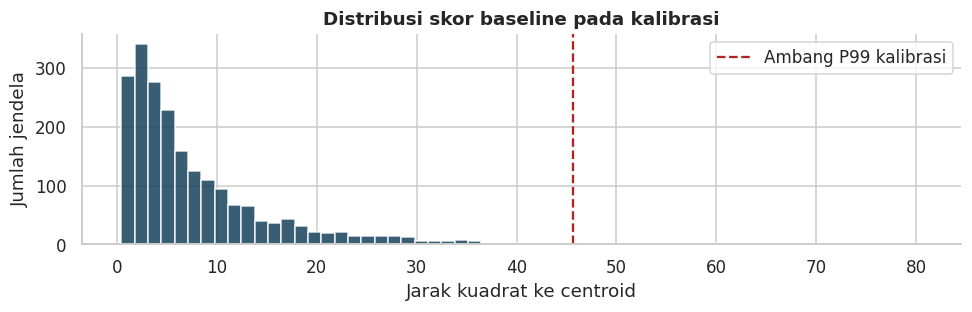

,feature,train_unique,validation_unique,validation_changed_from_train
0,Caudal_impulses__duty,1,14,True
1,LPS__duty,1,35,True
2,Oil_level__duty,1,21,True


**Hasil baseline:** 22/25 fitur dipertahankan; ambang 45.631065; pelampauan kalibrasi 0.96%, alarm 0.00%. Sinyal konstan saat train tidak dapat dipelajari variasinya; jika berubah di validasi, perubahan tersebut dilaporkan sebagai blind spot, bukan disembunyikan atau dianggap tidak penting.

In [14]:
def make_model(name, seed=SEED):
    steps = [
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("constant_filter", VarianceThreshold(threshold=0.0)),
        ("scaler", StandardScaler()),
    ]
    if name == "PCA_KMeans":
        steps.append(("pca", PCA(n_components=PCA_VARIANCE, svd_solver="full")))
    if name in ["KMeans", "PCA_KMeans"]:
        estimator = KMeans(
            n_clusters=BASE_K, init="k-means++", n_init=KMEANS_N_INIT,
            max_iter=300, random_state=seed)
    elif name == "IsolationForest":
        estimator = IsolationForest(
            n_estimators=IFOREST_TREES, max_samples=IFOREST_MAX_SAMPLES,
            contamination="auto", bootstrap=False, random_state=seed,
            n_jobs=CPU_THREADS)
    else:
        raise ValueError(f"Nama model tidak dikenali: {name}")
    return Pipeline(steps + [("model", estimator)])

def fit_and_calibrate(name, train_frame, calibration_frame):
    pipeline = make_model(name)
    started = time.perf_counter()
    with threadpool_limits(limits=CPU_THREADS):
        pipeline.fit(train_frame)
    fit_seconds = time.perf_counter() - started
    calibration_scores = anomaly_scores(pipeline, calibration_frame)
    threshold = float(np.quantile(calibration_scores, ALERT_QUANTILE, method="higher"))
    EXPERIMENT_LOG.append({"experiment_id": f"E{len(EXPERIMENT_LOG)+1:03d}",
        "model": name, "seed": SEED, "train_n": len(train_frame), "cal_n": len(calibration_frame),
        "n_input_features": train_frame.shape[1], "fit_seconds": fit_seconds,
        "train_start": str(train_frame.index.min()), "train_end": str(train_frame.index.max()),
        "cal_start": str(calibration_frame.index.min()), "cal_end": str(calibration_frame.index.max()),
        "train_index_sha256": hashlib.sha256(train_frame.index.asi8.tobytes()).hexdigest(),
        "parameters": pipeline.get_params(deep=True), "threshold": threshold})
    return {
        "name": name, "pipeline": pipeline, "threshold": threshold,
        "fit_seconds": fit_seconds, "calibration_scores": calibration_scores,
        "train_rows": len(train_frame), "calibration_rows": len(calibration_frame),
        "feature_columns": list(train_frame.columns), "window": WINDOW,
        "persistence_windows": PERSISTENCE_WINDOWS, "cpu_threads": CPU_THREADS,
    }

def transformed_features(pipeline, frame, include_pca=True):
    transformed = frame
    for step_name, transformer in pipeline.steps[:-1]:
        if step_name == "pca" and not include_pca:
            break
        transformed = transformer.transform(transformed)
    return np.asarray(transformed)

FITTED["KMeans"] = fit_and_calibrate("KMeans", X_train, X_cal)
baseline = FITTED["KMeans"]
selector = baseline["pipeline"].named_steps["constant_filter"]
kept_features = np.asarray(FEATURE_COLUMNS)[selector.get_support()].tolist()
dropped_features = sorted(set(FEATURE_COLUMNS) - set(kept_features))
display(pd.DataFrame({
    "Parameter": ["n_clusters", "init", "n_init", "max_iter", "Ambang", "Fitur tersisa", "Waktu fit (s)"],
    "Nilai": [BASE_K, "k-means++", KMEANS_N_INIT, 300,
              baseline["threshold"], len(kept_features), round(baseline["fit_seconds"], 3)],
}))
print("Fitur konstan yang dibuang berdasarkan train:", dropped_features or "tidak ada")
cal_prediction = predict_bundle(baseline, X_cal)
display(cal_prediction.head(5))
fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(cal_prediction["score"], bins=60, color=COLORS["KMeans"], alpha=0.85)
ax.axvline(baseline["threshold"], color="#b22222", linestyle="--", label="Ambang P99 kalibrasi")
ax.set(title="Distribusi skor baseline pada kalibrasi", xlabel="Jarak kuadrat ke centroid", ylabel="Jumlah jendela")
ax.legend()
plt.tight_layout()
save_figure("06_skor_kalibrasi")

constant_feature_audit = pd.DataFrame({
    "feature": dropped_features,
    "train_unique": [X_train[c].nunique() for c in dropped_features],
    "validation_unique": [X_val[c].nunique() for c in dropped_features],
    "validation_changed_from_train": [bool(X_val[c].ne(X_train[c].iloc[0]).any()) for c in dropped_features],
})
display(constant_feature_audit)
display(Markdown(
    f"**Hasil baseline:** {len(kept_features)}/{len(FEATURE_COLUMNS)} fitur dipertahankan; "
    f"ambang {baseline['threshold']:.6f}; pelampauan kalibrasi {cal_prediction.exceed.mean():.2%}, "
    f"alarm {cal_prediction.alarm.mean():.2%}. "
    "Sinyal konstan saat train tidak dapat dipelajari variasinya; jika berubah di validasi, "
    "perubahan tersebut dilaporkan sebagai blind spot, bukan disembunyikan atau dianggap tidak penting."
))

**SECTION 7: Eksperimen K, evaluasi dan interpretasi cluster**

K=2-6 dibandingkan pada ruang fitur train yang sama. K=3 tetap sebagai baseline; nilai silhouette terbaik bukan otomatis detektor gangguan terbaik.

,K,inertia_per_window,silhouette,davies_bouldin,calinski_harabasz
0,2,10.2967,0.6226,0.7643,5660.3353
1,3,8.1656,0.6217,0.7142,4217.8048
2,4,6.4026,0.3574,0.9638,4042.3054
3,5,5.6190,0.3560,1.1093,3627.3344
4,6,4.9912,0.3479,1.0078,3391.3768


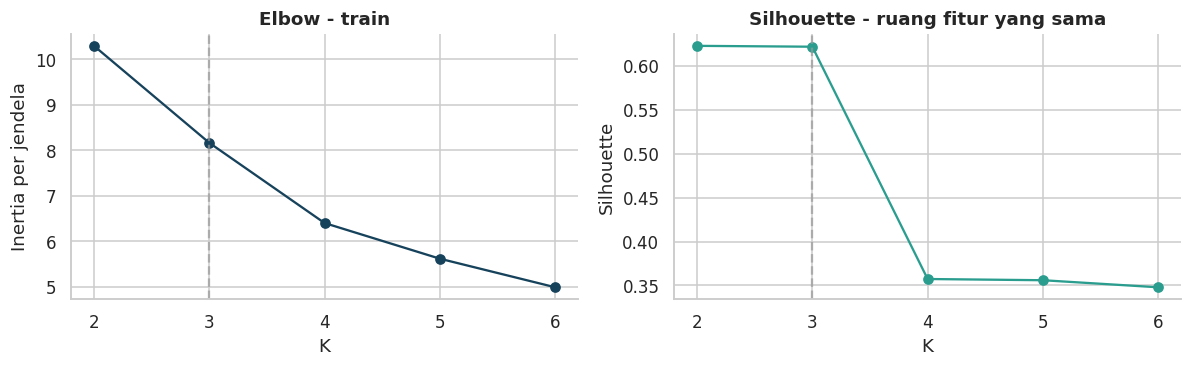

,n_windows,proporsi,TP3__mean,Motor_current__mean,Oil_temperature__mean,pressure_gap_mean,motor_load_fraction
cluster,,,,,,,
0,4108,0.8246,8.9300,0.7731,56.7366,-0.0025,0.0012
1,795,0.1596,9.1025,3.3919,56.8950,-0.0010,0.1685
2,79,0.0159,9.2894,3.7446,58.0592,-0.0010,0.1484


,n_windows,proporsi,TP3__mean,Motor_current__mean,Oil_temperature__mean,pressure_gap_mean,motor_load_fraction,interpretasi_relatif
cluster,,,,,,,,
0,4108,0.824568,8.930034,0.773147,56.736573,-0.002481,0.001246,Arus mean 0.77 A; proporsi berbeban 0.1%; beba...
1,795,0.159574,9.102508,3.391865,56.895041,-0.000951,0.168512,Arus mean 3.39 A; proporsi berbeban 16.9%; beb...
2,79,0.015857,9.289447,3.744601,58.059219,-0.000999,0.148373,Arus mean 3.74 A; proporsi berbeban 14.8%; beb...


**Hasil:** silhouette train terbaik pada K=2; baseline K=3 mempunyai cluster 0=4,108 jendela, cluster 1=795 jendela, cluster 2=79 jendela. Nama cluster bersifat arbitrer; interpretasi relatif didasarkan pada rerata sensor dan proporsi beban, tidak menyamakan cluster kecil dengan kerusakan. K tidak diubah berdasarkan benchmark uji.

In [15]:
Z_train = transformed_features(baseline["pipeline"], X_train)
rng = np.random.default_rng(SEED)
silhouette_indices = np.sort(rng.choice(len(Z_train), size=min(1500, len(Z_train)), replace=False))
k_rows = []
for k in K_GRID:
    if k == BASE_K:
        estimator = baseline["pipeline"].named_steps["model"]
    else:
        estimator = KMeans(n_clusters=k, init="k-means++", n_init=KMEANS_N_INIT,
                           max_iter=300, random_state=SEED)
        with threadpool_limits(limits=CPU_THREADS):
            estimator.fit(Z_train)
    labels = estimator.predict(Z_train)
    sampled_labels = labels[silhouette_indices]
    with threadpool_limits(limits=CPU_THREADS):
        sil = (silhouette_score(Z_train[silhouette_indices], sampled_labels)
               if 1 < len(np.unique(sampled_labels)) < len(sampled_labels) else np.nan)
        db = davies_bouldin_score(Z_train, labels)
        ch = calinski_harabasz_score(Z_train, labels)
    k_rows.append({"K": k, "inertia_per_window": estimator.inertia_ / len(Z_train),
                   "silhouette": sil, "davies_bouldin": db, "calinski_harabasz": ch})
k_scan = pd.DataFrame(k_rows)
display(k_scan.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(k_scan["K"], k_scan["inertia_per_window"], "o-", color="#16425b")
axes[0].set(title="Elbow - train", xlabel="K", ylabel="Inertia per jendela")
axes[1].plot(k_scan["K"], k_scan["silhouette"], "o-", color="#2a9d8f")
axes[1].set(title="Silhouette - ruang fitur yang sama", xlabel="K", ylabel="Silhouette")
for ax in axes:
    ax.axvline(BASE_K, color="#999999", linestyle="--", alpha=0.7)
    ax.set_xticks(K_GRID)
plt.tight_layout()
save_figure("07_elbow_silhouette")

train_cluster = pd.Series(baseline["pipeline"].predict(X_train),
                          index=X_train.index, name="cluster")
profile_columns = ["TP3__mean", "Motor_current__mean", "Oil_temperature__mean",
                   "pressure_gap_mean", "motor_load_fraction"]
profile = X_train[profile_columns].groupby(train_cluster).mean()
cluster_sizes = train_cluster.value_counts().sort_index().rename("n_windows")
profile.insert(0, "n_windows", cluster_sizes)
profile.insert(1, "proporsi", cluster_sizes / len(X_train))
display(profile.round(4))
best_sil_k = int(k_scan.sort_values("silhouette", ascending=False).iloc[0]["K"])

cluster_interpretation = profile.copy()
cluster_interpretation["interpretasi_relatif"] = [
    f"Arus mean {row['Motor_current__mean']:.2f} A; proporsi berbeban {row['motor_load_fraction']:.1%}; "
    + ("beban relatif dominan" if row['motor_load_fraction'] >= .5 else "beban relatif jarang/campuran")
    for _,row in profile.iterrows()]
display(cluster_interpretation)
display(Markdown(
    f"**Hasil:** silhouette train terbaik pada K={best_sil_k}; baseline K={BASE_K} mempunyai "
    + ", ".join(f"cluster {int(k)}={int(n):,} jendela" for k,n in cluster_sizes.items())
    + ". Nama cluster bersifat arbitrer; interpretasi relatif didasarkan pada rerata sensor dan "
    "proporsi beban, tidak menyamakan cluster kecil dengan kerusakan. K tidak diubah berdasarkan benchmark uji."
))

**SECTION 8: Kandidat PCA + K-Means dan ensemble Isolation Forest**

PCA menguji kompresi korelasi dan Isolation Forest menguji pendekatan non-linear berbasis ensemble pohon. Data, kalibrasi, kuantil dan persistensi identik.

,komponen,explained_variance_ratio,kumulatif
0,1,0.58939,0.58939
1,2,0.13656,0.72595
2,3,0.10772,0.83367
3,4,0.05753,0.89119
4,5,0.03193,0.92312
5,6,0.01981,0.94293
6,7,0.01399,0.95692


,model,fit_windows,fitur_awal,setelah_filter,dimensi_model,threshold_P99,fit_seconds
0,KMeans,4982,25,22,22,45.6311,0.1244
1,PCA_KMeans,4982,25,22,7,36.7491,0.1037
2,IsolationForest,4982,25,22,22,0.6592,0.5271


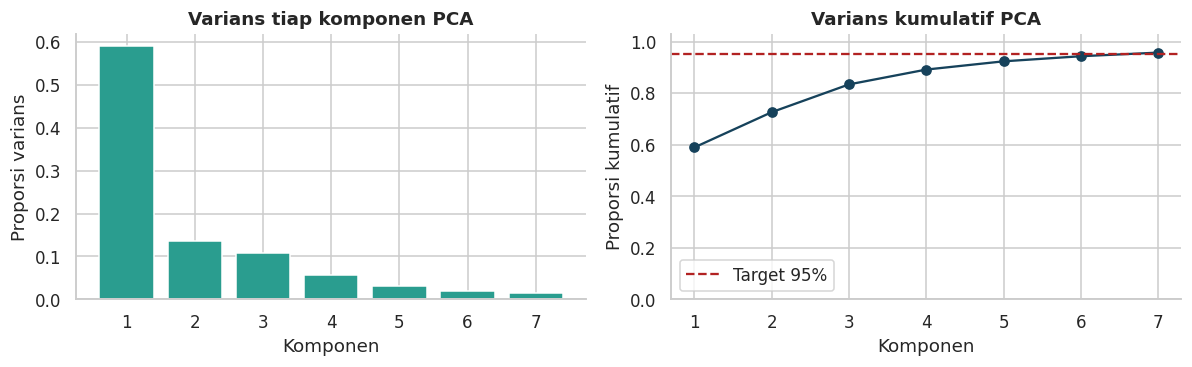

**Hasil:** PCA mempertahankan 7 komponen dari 22 fitur yang lolos filter, varians kumulatif 95.69%. Isolation Forest memakai 200 pohon dan max_samples=256. Varians PCA bukan metrik akurasi; arah varians kecil yang relevan terhadap anomali bisa hilang. contamination='auto' tidak dipakai sebagai ambang alarm; ambang tetap berasal dari skor kalibrasi.

In [16]:
for name in ["PCA_KMeans", "IsolationForest"]:
    FITTED[name] = fit_and_calibrate(name, X_train, X_cal)

pca_pipe = FITTED["PCA_KMeans"]["pipeline"]
pca_model = pca_pipe.named_steps["pca"]
pca_variance = pd.DataFrame({
    "komponen": np.arange(1, pca_model.n_components_ + 1),
    "explained_variance_ratio": pca_model.explained_variance_ratio_,
    "kumulatif": pca_model.explained_variance_ratio_.cumsum(),
})
display(pca_variance.round(5))
model_settings = []
for name in MODEL_NAMES:
    bundle = FITTED[name]
    pipe = bundle["pipeline"]
    n_after_filter = int(pipe.named_steps["constant_filter"].get_support().sum())
    model_settings.append({
        "model": name, "fit_windows": bundle["train_rows"],
        "fitur_awal": len(FEATURE_COLUMNS), "setelah_filter": n_after_filter,
        "dimensi_model": int(pipe.named_steps["pca"].n_components_) if "pca" in pipe.named_steps else n_after_filter,
        "threshold_P99": bundle["threshold"], "fit_seconds": bundle["fit_seconds"],
    })
model_settings = pd.DataFrame(model_settings)
display(model_settings.round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(pca_variance["komponen"], pca_variance["explained_variance_ratio"], color="#2a9d8f")
axes[0].set(title="Varians tiap komponen PCA", xlabel="Komponen", ylabel="Proporsi varians")
axes[1].plot(pca_variance["komponen"], pca_variance["kumulatif"], "o-", color="#16425b")
axes[1].axhline(PCA_VARIANCE, color="#b22222", linestyle="--", label="Target 95%")
axes[1].set(title="Varians kumulatif PCA", xlabel="Komponen", ylabel="Proporsi kumulatif", ylim=(0, 1.03))
axes[1].legend()
plt.tight_layout()
save_figure("08_varians_PCA")

display(Markdown(
    f"**Hasil:** PCA mempertahankan {pca_model.n_components_} komponen dari "
    f"{len(kept_features)} fitur yang lolos filter, varians kumulatif "
    f"{pca_model.explained_variance_ratio_.sum():.2%}. Isolation Forest memakai "
    f"{IFOREST_TREES} pohon dan max_samples={IFOREST_MAX_SAMPLES}. "
    "Varians PCA bukan metrik akurasi; arah varians kecil yang relevan terhadap anomali bisa hilang. "
    "contamination='auto' tidak dipakai sebagai ambang alarm; ambang tetap berasal dari skor kalibrasi."
))

**SECTION 9: Validasi temporal, ablation, sensitivitas, dan pemilihan kandidat**

Lima fold expanding window menguji respons terhadap waktu pada referensi; validasi Maret-Mei membandingkan kemampuan pemeringkatan dan alarm terhadap laporan.

**Batas analisis CV:** referensi Februari tidak memiliki gangguan tercatat, sehingga recall/AP kegagalan tidak dihitung pada fold tersebut. Yang diukur adalah exceed rate, alarm rate, median skor relatif ambang, dan silhouette untuk model cluster bila terdefinisi. Lima fold berasal dari grid kalender lima menit yang sama; setiap fold memisahkan fit/kalibrasi/evaluasi secara kronologis dan memfit ulang seluruh Pipeline. Proporsi alarm nol tidak membuktikan model mampu mendeteksi gangguan.

**Perbandingan validasi:** AP proxy adalah kriteria utama kandidat prioritas untuk kualitas pemeringkatan; F1, recall kejadian dan biaya episode tetap diperlihatkan. Bila F1 terbaik berasal dari model lain, hal tersebut dilaporkan sebagai trade-off. Klaim "lebih baik" tidak dibuat dari satu visualisasi atau satu metrik saja. Ablation fitur dan sensitivitas di bawah adalah diagnosis; tidak masuk ulang ke pemilihan kandidat utama pada run ini.

In [17]:
EVENT_COLUMNS = ["event_id", "report_start", "report_end", "expected_overlap_windows",
    "usable_overlap_windows", "observed_report_windows", "decision_windows_in_report", "post_report_label_windows", "coverage_fraction",
    "status_observation", "detected_during_report", "first_alarm", "delay_from_report_start_min"]

def interval_evaluation(prediction):
    rows = []
    if prediction.empty:
        return pd.DataFrame(columns=EVENT_COLUMNS)
    scope_start = prediction.index.min() - WINDOW_DELTA
    scope_end = prediction.index.max()
    for number, event in enumerate(FAILURES.itertuples(), start=1):
        if event.end < scope_start or event.start >= scope_end:
            continue
        expected = meta.index[(meta.window_start < event.end) & (meta.index > event.start)
                              & (meta.index > scope_start) & (meta.window_start < scope_end)]
        observed = prediction.loc[meta.loc[prediction.index, "event_number"].eq(number)]
        during = observed.loc[(observed.index >= event.start) & (observed.index <= event.end)]
        alarms = during.index[during.alarm.eq(1)]
        first = alarms.min() if len(alarms) else pd.NaT
        usable_overlap = prediction.index.intersection(expected)
        ratio = len(usable_overlap) / len(expected) if len(expected) else np.nan
        status = ("tidak_teramati" if len(observed)==0 else
                  "teramati_penuh" if np.isclose(ratio,1.) else "teramati_sebagian")
        rows.append({"event_id": event.event_id, "report_start": event.start, "report_end": event.end,
            "expected_overlap_windows": len(expected), "usable_overlap_windows": len(usable_overlap),
            "observed_report_windows": len(observed), "decision_windows_in_report": len(during),
            "post_report_label_windows": int((observed.index > event.end).sum()), "coverage_fraction": ratio,
            "status_observation": status, "detected_during_report": bool(len(alarms)),
            "first_alarm": first,
            "delay_from_report_start_min": (first-event.start).total_seconds()/60 if pd.notna(first) else np.nan})
    return pd.DataFrame(rows, columns=EVENT_COLUMNS)

def alarm_segments(prediction):
    rows = []
    timestamps = prediction.index[prediction.alarm.eq(1)]
    if len(timestamps):
        groups = np.cumsum(np.r_[True, np.diff(timestamps.asi8) != WINDOW_DELTA.value])
        for group in np.unique(groups):
            times = timestamps[groups==group]
            first,last = times[0],times[-1]
            matches = [event.event_id for event in FAILURES.itertuples()
                       if first <= event.end and last >= event.start]
            rows.append({"start_alarm": first, "last_alarm": last, "n_windows": len(times),
                "alarm_window_minutes": len(times)*WINDOW_DELTA.total_seconds()/60,
                "decision_span_minutes": (last-first).total_seconds()/60,
                "overlaps_report": bool(matches), "matching_reports": ";".join(matches)})
    return pd.DataFrame(rows, columns=["start_alarm", "last_alarm", "n_windows", "alarm_window_minutes",
                                      "decision_span_minutes", "overlaps_report", "matching_reports"])

def evaluate_predictions(name, prediction):
    y=meta.loc[prediction.index,"y_report"].to_numpy(dtype=int)
    alarm=prediction.alarm.to_numpy(dtype=int)
    score=prediction.score.to_numpy()
    precision,recall,f1,_=precision_recall_fscore_support(y,alarm,average="binary",zero_division=0)
    cm=confusion_matrix(y,alarm,labels=[0,1])
    tn,fp,fn,tp=cm.ravel()
    two_classes=len(np.unique(y))==2
    events=interval_evaluation(prediction)
    observed=events.loc[events.observed_report_windows.gt(0)]
    segments=alarm_segments(prediction)
    outside=y==0
    monitored_days=len(y)*WINDOW_DELTA.total_seconds()/86400
    outside_days=int(outside.sum())*WINDOW_DELTA.total_seconds()/86400
    outside_episodes=int((~segments.overlaps_report.astype(bool)).sum())
    return {"model": name,"n_windows":len(y),"reported_windows":int(y.sum()),
        "report_prevalence":float(y.mean()),
        "AP_proxy":average_precision_score(y,score) if two_classes else np.nan,
        "ROC_AUC_proxy":roc_auc_score(y,score) if two_classes else np.nan,
        "precision_proxy":precision,"recall_proxy":recall,"F1_proxy":f1,
        "accuracy_proxy":accuracy_score(y,alarm),"TN_proxy":int(tn),"FP_proxy":int(fp),
        "FN_proxy":int(fn),"TP_proxy":int(tp),"alarm_rate":float(alarm.mean()),
        "outside_report_alarm_rate":float(alarm[outside].mean()) if outside.any() else np.nan,
        "reported_events_in_scope":len(events),"reported_events_observed":len(observed),
        "unobserved_events":int(events.observed_report_windows.eq(0).sum()),
        "reported_events_detected":int(observed.detected_during_report.sum()),
        "event_recall_report":float(observed.detected_during_report.mean()) if len(observed) else np.nan,
        "median_detection_delay_min":float(observed.delay_from_report_start_min.median()) if observed.delay_from_report_start_min.notna().any() else np.nan,
        "n_alarm_segments":len(segments),"outside_report_episodes":outside_episodes,
        "monitored_days_equivalent":monitored_days,"outside_report_days_equivalent":outside_days,
        "outside_report_episodes_per_monitored_day":outside_episodes/monitored_days if monitored_days else np.nan,
        "outside_report_alarm_hours":int(fp)*WINDOW_DELTA.total_seconds()/3600}

event_coverage_rows=[]
for event in FAILURES.itertuples():
    mask=(raw.index>=event.start)&(raw.index<=event.end)
    expected=meta.index[(meta.window_start<event.end)&(meta.index>event.start)]
    event_coverage_rows.append({"event_id":event.event_id,"raw_rows_in_report":int(mask.sum()),
        "expected_overlap_windows":len(expected),"usable_overlap_windows":int(meta.loc[expected,"usable"].sum()),
        "invalid_overlap_windows":int((~meta.loc[expected,"usable"]).sum()),
        "usable_overlap_fraction":float(meta.loc[expected,"usable"].mean()),
        "split": ";".join(sorted(meta.loc[expected,"split"].unique()))})
event_coverage=pd.DataFrame(event_coverage_rows)
display(event_coverage)

,event_id,raw_rows_in_report,expected_overlap_windows,usable_overlap_windows,invalid_overlap_windows,usable_overlap_fraction,split
0,F01,8657,288,286,2,0.993056,validation
1,F02,2360,78,78,0,1.000000,validation
2,F03,17315,630,571,59,0.906349,test
3,F04,1622,54,53,1,0.981481,test


Fold 1/5: train=656, kalibrasi=192, evaluasi=734
Fold 2/5: train=1,311, kalibrasi=272, evaluasi=865
Fold 3/5: train=1,962, kalibrasi=485, evaluasi=772
Fold 4/5: train=2,595, kalibrasi=624, evaluasi=906
Fold 5/5: train=3,219, kalibrasi=906, evaluasi=855


,fold,model,n_train,n_calibration,n_validation,exceed_rate,alarm_rate,fit_seconds
0,1,KMeans,656,192,734,0.0327,0.0,0.0314
1,1,PCA_KMeans,656,192,734,0.0381,0.0,0.0486
2,1,IsolationForest,656,192,734,0.0286,0.0,0.4864
3,2,KMeans,1311,272,865,0.0208,0.0,0.0391
4,2,PCA_KMeans,1311,272,865,0.0231,0.0,0.0904
5,2,IsolationForest,1311,272,865,0.0173,0.0,0.6523
6,3,KMeans,1962,485,772,0.0117,0.0,0.0717
7,3,PCA_KMeans,1962,485,772,0.0117,0.0,0.2826
8,3,IsolationForest,1962,485,772,0.0039,0.0,0.7151
9,4,KMeans,2595,624,906,0.0055,0.0,0.0825


,mean_exceed_rate,std_exceed_rate,mean_alarm_rate,std_alarm_rate,mean_fit_seconds,mean_relative_score,std_relative_score,mean_silhouette,std_silhouette
model,,,,,,,,,
IsolationForest,0.0136,0.0099,0.0,0.0,0.6289,0.6122,0.0258,NaN,NaN
KMeans,0.0153,0.0115,0.0,0.0,0.0673,0.1143,0.0151,0.5795,0.1275
PCA_KMeans,0.0171,0.0137,0.0,0.0,0.1363,0.1112,0.0199,0.5958,0.1300


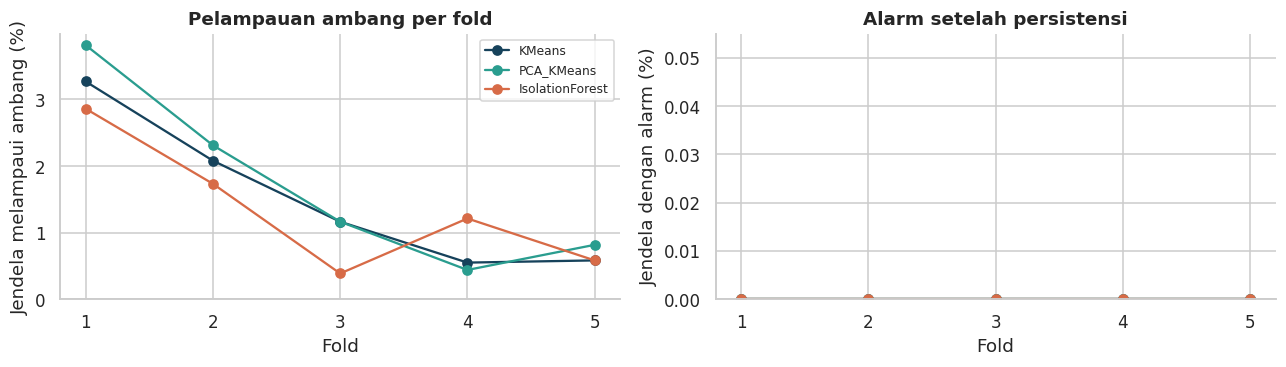

**Kestabilan referensi:** 15 catatan model-fold. Rentang exceed rate 0.39%-3.81%; rentang alarm rate 0.00%-0.00%. Rerata dan simpangan baku ditampilkan pada tabel, namun lima fold saling berbagi data latih dan tidak merupakan lima sampel independen. Silhouette antarrepresentasi dipakai diagnostik masing-masing model, bukan bukti PCA lebih baik pada deteksi. Tidak ada recall kegagalan dari fold tanpa laporan.

In [18]:
reference_grid = features.loc[
    (meta["window_start"] >= REFERENCE_START) & (features.index <= FIT_END)]
tscv = TimeSeriesSplit(n_splits=N_TEMPORAL_FOLDS, gap=SPLIT_GAP_WINDOWS)
cv_rows = []
for fold, (past_idx, future_idx) in enumerate(tscv.split(reference_grid), start=1):
    cut = int(0.80 * len(past_idx))
    fit_idx = past_idx[:cut - SPLIT_GAP_WINDOWS]
    calibration_idx = past_idx[cut:]
    frames = []
    for indices in [fit_idx, calibration_idx, future_idx]:
        part = reference_grid.iloc[indices]
        frames.append(part.loc[meta.loc[part.index, "usable"]])
    fold_train, fold_cal, fold_valid = frames
    assert min(map(len, frames)) >= 30
    assert fold_train.index.max() < fold_cal.index.min() < fold_valid.index.min()
    for name in MODEL_NAMES:
        bundle = fit_and_calibrate(name, fold_train, fold_cal)
        prediction = predict_bundle(bundle, fold_valid)
        Z_fold=transformed_features(bundle["pipeline"],fold_valid)
        fold_sil=np.nan
        if name in ["KMeans","PCA_KMeans"]:
            fold_labels=bundle["pipeline"].predict(fold_valid)
            idx=np.random.default_rng(SEED).choice(len(Z_fold),size=min(800,len(Z_fold)),replace=False)
            labels_sample=fold_labels[idx]
            if 1 < len(np.unique(labels_sample)) < len(idx):
                fold_sil=float(silhouette_score(Z_fold[idx],labels_sample))
        cv_rows.append({
            "fold": fold, "model": name,
            "fit_start": fold_train.index.min(), "calibration_start": fold_cal.index.min(),
            "median_relative_score": float(prediction.score.median()/max(bundle["threshold"],np.finfo(float).eps)),
            "silhouette_validation": fold_sil, "n_train": len(fold_train),
            "n_calibration": len(fold_cal), "n_validation": len(fold_valid),
            "train_end": fold_train.index.max(), "calibration_end": fold_cal.index.max(),
            "validation_start": fold_valid.index.min(), "validation_end": fold_valid.index.max(),
            "exceed_rate": prediction["exceed"].mean(),
            "alarm_rate": prediction["alarm"].mean(),
            "fit_seconds": bundle["fit_seconds"],
            "threshold": bundle["threshold"],
        })
    print(f"Fold {fold}/{N_TEMPORAL_FOLDS}: train={len(fold_train):,}, kalibrasi={len(fold_cal):,}, evaluasi={len(fold_valid):,}")
cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby("model").agg(
    mean_exceed_rate=("exceed_rate", "mean"), std_exceed_rate=("exceed_rate", "std"),
    mean_alarm_rate=("alarm_rate", "mean"), std_alarm_rate=("alarm_rate", "std"),
    mean_fit_seconds=("fit_seconds", "mean"),
    mean_relative_score=("median_relative_score","mean"), std_relative_score=("median_relative_score","std"),
    mean_silhouette=("silhouette_validation","mean"),std_silhouette=("silhouette_validation","std"))
display(cv_results[["fold", "model", "n_train", "n_calibration", "n_validation",
                    "exceed_rate", "alarm_rate", "fit_seconds"]].round(4))
display(cv_summary.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for name in MODEL_NAMES:
    part = cv_results.loc[cv_results["model"] == name]
    axes[0].plot(part["fold"], 100 * part["exceed_rate"], "o-", label=name, color=COLORS[name])
    axes[1].plot(part["fold"], 100 * part["alarm_rate"], "o-", label=name, color=COLORS[name])
axes[0].set(title="Pelampauan ambang per fold", xlabel="Fold", ylabel="Jendela melampaui ambang (%)")
axes[1].set(title="Alarm setelah persistensi", xlabel="Fold", ylabel="Jendela dengan alarm (%)")
for ax in axes:
    ax.set_xticks(range(1, N_TEMPORAL_FOLDS + 1))
    ax.set_ylim(bottom=0)
axes[0].legend(fontsize=8)
plt.tight_layout()
save_figure("09_validasi_lima_fold")

display(Markdown(
    f"**Kestabilan referensi:** {len(cv_results)} catatan model-fold. Rentang exceed rate "
    f"{cv_results.exceed_rate.min():.2%}-{cv_results.exceed_rate.max():.2%}; "
    f"rentang alarm rate {cv_results.alarm_rate.min():.2%}-{cv_results.alarm_rate.max():.2%}. "
    "Rerata dan simpangan baku ditampilkan pada tabel, namun lima fold saling berbagi data latih "
    "dan tidak merupakan lima sampel independen. Silhouette antarrepresentasi dipakai diagnostik "
    "masing-masing model, bukan bukti PCA lebih baik pada deteksi. Tidak ada recall kegagalan dari fold tanpa laporan."
))

**9B. Perbandingan kandidat pada validasi dan pembekuan pilihan**

Pemeringkatan telah ditentukan sebelum hasil validasi diperoleh, di mana Average Precision (AP) memiliki karakteristik yang berbeda dari F1-score berbasis ambang batas.

,model,n_windows,reported_windows,report_prevalence,AP_proxy,ROC_AUC_proxy,precision_proxy,recall_proxy,F1_proxy,accuracy_proxy,TN_proxy,FP_proxy,FN_proxy,TP_proxy,alarm_rate,...,reported_events_observed,unobserved_events,reported_events_detected,event_recall_report,median_detection_delay_min,n_alarm_segments,outside_report_episodes,monitored_days_equivalent,outside_report_days_equivalent,outside_report_episodes_per_monitored_day,outside_report_alarm_hours,role,validation_method,threshold_source,persistence_windows
0,KMeans,21286,364,0.0171,0.2974,0.9818,0.1499,0.9918,0.2604,0.9036,18874,2048,3,361,0.1132,...,2,0,2,1.0,5.0,53,50,73.9097,72.6458,0.6765,170.6667,baseline,Temporal hold-out Maret-Mei; fit/kalibrasi Feb...,P99 kalibrasi Februari akhir,3
1,PCA_KMeans,21286,364,0.0171,0.2907,0.9811,0.1491,0.9945,0.2593,0.9028,18856,2066,2,362,0.1141,...,2,0,2,1.0,5.0,58,55,73.9097,72.6458,0.7442,172.1667,kandidat representasi,Temporal hold-out Maret-Mei; fit/kalibrasi Feb...,P99 kalibrasi Februari akhir,3
2,IsolationForest,21286,364,0.0171,0.1105,0.9373,0.2481,0.9835,0.3962,0.9487,19837,1085,6,358,0.0678,...,2,0,2,1.0,22.5,34,32,73.9097,72.6458,0.4330,90.4167,kandidat ensemble,Temporal hold-out Maret-Mei; fit/kalibrasi Feb...,P99 kalibrasi Februari akhir,3


,model,n_windows,reported_windows,report_prevalence,AP_proxy,ROC_AUC_proxy,precision_proxy,recall_proxy,F1_proxy,accuracy_proxy,TN_proxy,FP_proxy,FN_proxy,TP_proxy,alarm_rate,outside_report_alarm_rate,reported_events_in_scope,reported_events_observed,unobserved_events,reported_events_detected,event_recall_report,median_detection_delay_min,n_alarm_segments,outside_report_episodes,monitored_days_equivalent,outside_report_days_equivalent,outside_report_episodes_per_monitored_day,outside_report_alarm_hours
0,Kontrol_tanpa_alarm,21286,364,0.0171,0.0171,0.5,0.0,0.0,0.0,0.9829,20922,0,364,0,0.0,0.0,2,2,0,0,0.0,NaN,0,0,73.9097,72.6458,0.0,0.0


,bulan,model,reported_windows,AP_proxy,alarm_rate,F1_proxy
0,2020-03,KMeans,0,NaN,0.0692,0.0000
1,2020-04,KMeans,286,0.9248,0.1348,0.4826
2,2020-05,KMeans,78,0.1007,0.1401,0.1438
3,2020-03,PCA_KMeans,0,NaN,0.0711,0.0000
4,2020-04,PCA_KMeans,286,0.9303,0.1352,0.4814
5,2020-05,PCA_KMeans,78,0.0976,0.1403,0.1454
6,2020-03,IsolationForest,0,NaN,0.0666,0.0000
7,2020-04,IsolationForest,286,0.3124,0.0685,0.7605
8,2020-05,IsolationForest,78,0.0725,0.0684,0.2735


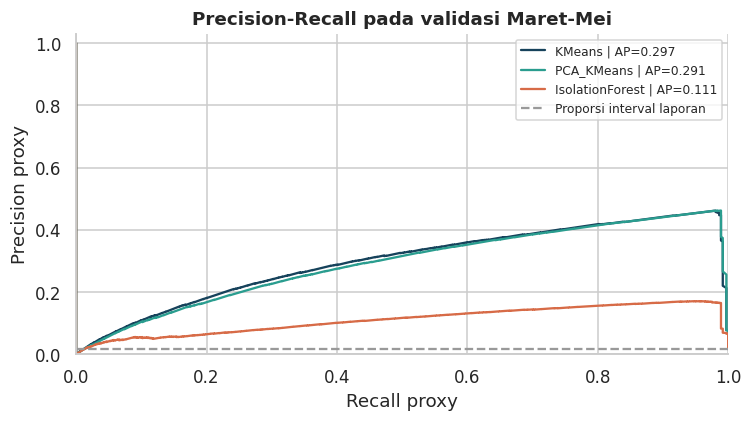

,event_id,report_start,report_end,expected_overlap_windows,usable_overlap_windows,observed_report_windows,decision_windows_in_report,post_report_label_windows,coverage_fraction,status_observation,detected_during_report,first_alarm,delay_from_report_start_min,model
0,F01,2020-04-18 00:00:00,2020-04-18 23:59:00,288,286,286,285,1,0.993056,teramati_sebagian,True,2020-04-18 00:05:00,5.0,KMeans
1,F02,2020-05-29 23:30:00,2020-05-30 06:00:00,78,78,78,78,0,1.000000,teramati_penuh,True,2020-05-29 23:35:00,5.0,KMeans
2,F01,2020-04-18 00:00:00,2020-04-18 23:59:00,288,286,286,285,1,0.993056,teramati_sebagian,True,2020-04-18 00:05:00,5.0,PCA_KMeans
3,F02,2020-05-29 23:30:00,2020-05-30 06:00:00,78,78,78,78,0,1.000000,teramati_penuh,True,2020-05-29 23:35:00,5.0,PCA_KMeans
4,F01,2020-04-18 00:00:00,2020-04-18 23:59:00,288,286,286,285,1,0.993056,teramati_sebagian,True,2020-04-18 00:40:00,40.0,IsolationForest
5,F02,2020-05-29 23:30:00,2020-05-30 06:00:00,78,78,78,78,0,1.000000,teramati_penuh,True,2020-05-29 23:35:00,5.0,IsolationForest


,model,AP_proxy,F1_proxy,event_recall_report,outside_report_episodes_per_monitored_day,fit_seconds
0,KMeans,0.29745,0.26037,1.0,0.67650,0.12437
1,PCA_KMeans,0.29072,0.25931,1.0,0.74415,0.10375
2,IsolationForest,0.11051,0.39624,1.0,0.43296,0.52715


**Pilihan validasi:** KMeans (AP 0.2974; F1 0.2604). F1 tertinggi: IsolationForest. AP adalah metrik pemeringkatan; pilihan prioritas tidak berarti unggul di semua metrik, dan deteksi seluruh interval tidak menyatakan semua jendela tepat. Perbandingan biaya fit dipengaruhi perangkat, sehingga bukan benchmark perangkat keras yang terkontrol.

In [19]:
validation_rows = []
for name in MODEL_NAMES:
    prediction = predict_bundle(FITTED[name], X_val)
    PREDICTIONS[("validation", name)] = prediction
    validation_rows.append(evaluate_predictions(name, prediction))
validation_metrics = pd.DataFrame(validation_rows)
validation_metrics["role"] = validation_metrics.model.map({"KMeans":"baseline","PCA_KMeans":"kandidat representasi","IsolationForest":"kandidat ensemble"})
validation_metrics["validation_method"] = "Temporal hold-out Maret-Mei; fit/kalibrasi Februari"
validation_metrics["threshold_source"] = "P99 kalibrasi Februari akhir"
validation_metrics["persistence_windows"] = PERSISTENCE_WINDOWS
control_validation = pd.DataFrame({"score": 0.0, "exceed": 0, "alarm": 0}, index=X_val.index)
control_val_metrics = evaluate_predictions("Kontrol_tanpa_alarm", control_validation)
display(validation_metrics.round(4))
display(pd.DataFrame([control_val_metrics]).round(4))

ranking = validation_metrics.sort_values(
    ["AP_proxy", "event_recall_report", "F1_proxy", "model"],
    ascending=[False, False, False, True], na_position="last")
SELECTED_MODEL = str(ranking.iloc[0]["model"])
FROZEN_MODEL_HASHES = {name: joblib.hash(FITTED[name]["pipeline"]) for name in MODEL_NAMES}
FROZEN_THRESHOLDS = {name: FITTED[name]["threshold"] for name in MODEL_NAMES}
FROZEN_SELECTED_MODEL = SELECTED_MODEL

development_blocks = []
for name in MODEL_NAMES:
    prediction = PREDICTIONS[("validation", name)]
    for month in prediction.index.to_period("M").unique():
        part = prediction.loc[prediction.index.to_period("M") == month]
        row = evaluate_predictions(name, part)
        row["bulan"] = str(month)
        development_blocks.append(row)
development_blocks = pd.DataFrame(development_blocks)
display(development_blocks[["bulan", "model", "reported_windows",
                             "AP_proxy", "alarm_rate", "F1_proxy"]].round(4))

fig, ax = plt.subplots(figsize=(7, 4))
y_val_proxy = meta.loc[X_val.index, "y_report"].to_numpy()
for name in MODEL_NAMES:
    precision_curve, recall_curve, _ = precision_recall_curve(
        y_val_proxy, PREDICTIONS[("validation", name)]["score"])
    ap = float(validation_metrics.set_index("model").loc[name, "AP_proxy"])
    ax.plot(recall_curve, precision_curve, label=f"{name} | AP={ap:.3f}", color=COLORS[name])
ax.axhline(y_val_proxy.mean(), color="#999999", linestyle="--", label="Proporsi interval laporan")
ax.set(xlabel="Recall proxy", ylabel="Precision proxy",
       title="Precision-Recall pada validasi Maret-Mei", xlim=(0, 1), ylim=(0, 1.03))
ax.legend(fontsize=8)
plt.tight_layout()
save_figure("09_kurva_PR_validasi")
selected_val = validation_metrics.set_index("model").loc[SELECTED_MODEL]
base_val = validation_metrics.set_index("model").loc["KMeans"]
pca_val = validation_metrics.set_index("model").loc["PCA_KMeans"]
forest_val = validation_metrics.set_index("model").loc["IsolationForest"]

validation_events=pd.concat([interval_evaluation(PREDICTIONS[("validation",n)]).assign(model=n)
                             for n in MODEL_NAMES],ignore_index=True)
display(validation_events)
model_tradeoffs = validation_metrics[["model","AP_proxy","F1_proxy","event_recall_report",
    "outside_report_episodes_per_monitored_day","fit_seconds"]].copy() if "fit_seconds" in validation_metrics else validation_metrics[["model","AP_proxy","F1_proxy","event_recall_report","outside_report_episodes_per_monitored_day"]].copy()
model_tradeoffs=model_tradeoffs.merge(model_settings[["model","fit_seconds"]],on="model",how="left")
display(model_tradeoffs.round(5))
display(Markdown(
    f"**Pilihan validasi:** {SELECTED_MODEL} (AP {selected_val['AP_proxy']:.4f}; F1 {selected_val['F1_proxy']:.4f}). "
    f"F1 tertinggi: {validation_metrics.set_index('model').F1_proxy.idxmax()}. "
    "AP adalah metrik pemeringkatan; pilihan prioritas tidak berarti unggul di semua metrik, "
    "dan deteksi seluruh interval tidak menyatakan semua jendela tepat. Perbandingan biaya fit "
    "dipengaruhi perangkat, sehingga bukan benchmark perangkat keras yang terkontrol."
))

**9C. Ablation rekayasa fitur dan sensitivitas operasional pada validasi**

Ablation membandingkan **22 statistik dasar** dengan **25 fitur lengkap** memakai K-Means K=3, train, kalibrasi, scaler, kuantil, dan persistensi yang sama. Setiap pipeline dipelajari ulang pada fiturnya sendiri. Ini menguji paket tiga fitur tambahan bersama-sama, belum mengisolasi kontribusi kausal setiap fitur.

Sensitivitas menguji kuantil 0,975/0,99/0,995 dan persistensi 1/3/6 memakai skor model prioritas yang tetap. Semua ambang berasal dari kalibrasi; metrik diperiksa di validasi. Hasil ini tidak digunakan untuk mengganti konfigurasi P99/3 jendela pada benchmark. Ambang/persistensi memengaruhi alarm, sedangkan AP skor tetap sama.

,model,n_features_input,AP_proxy,precision_proxy,recall_proxy,F1_proxy,outside_report_episodes_per_monitored_day
0,KMeans_22_dasar,22,0.29749,0.15090,0.99451,0.26203,0.63591
1,KMeans_25_lengkap,25,0.29745,0.14985,0.99176,0.26037,0.67650


**Temuan fitur:** perubahan AP validasi paket tiga fitur = -0.00004. Jika negatif, rekayasa fitur belum memberi manfaat pada kriteria tersebut dan tetap dilaporkan. Kesimpulan tidak boleh diubah menjadi 'fitur pasti meningkatkan akurasi'.

,quantile,persistence,precision_proxy,recall_proxy,F1_proxy,event_recall_report,outside_report_episodes_per_monitored_day,is_primary_configuration
0,0.975,1,0.05534,1.00000,0.10488,1.0,44.21610,False
1,0.975,3,0.14119,0.99451,0.24727,1.0,1.56948,False
2,0.975,6,0.15355,0.98077,0.26553,1.0,0.47355,False
3,0.990,1,0.07952,0.99725,0.14729,1.0,26.43766,False
4,0.990,3,0.14985,0.99176,0.26037,1.0,0.67650,True
5,0.990,6,0.15505,0.97802,0.26767,1.0,0.29766,False
6,0.995,1,0.08908,0.99725,0.16355,1.0,20.76858,False
7,0.995,3,0.15098,0.99176,0.26207,1.0,0.58179,False
8,0.995,6,0.15553,0.97802,0.26838,1.0,0.29766,False


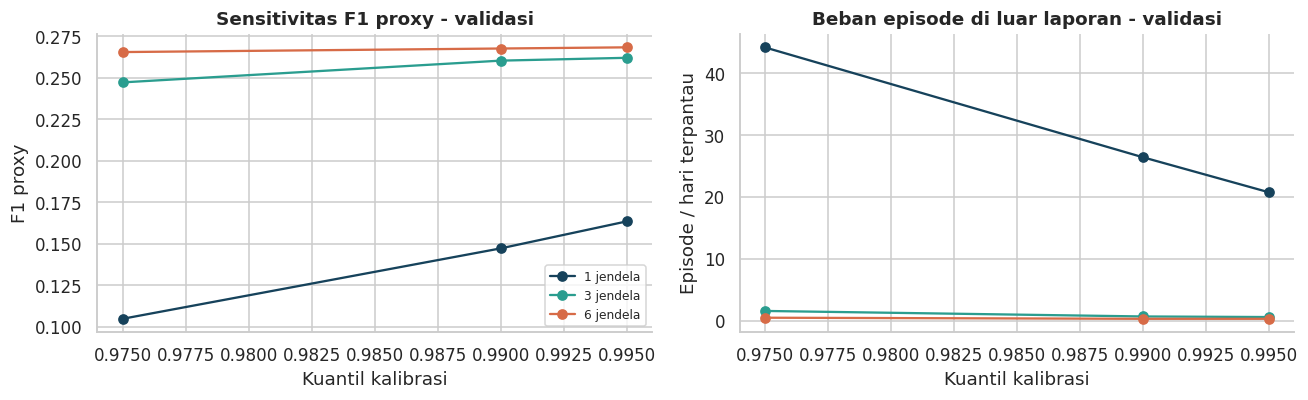

In [20]:
ablation_bundle=fit_and_calibrate("KMeans",X_train[BASIC_COLUMNS],X_cal[BASIC_COLUMNS])
ablation_prediction=predict_bundle(ablation_bundle,X_val[BASIC_COLUMNS])
ablation_rows=[]
for label,pred,n_features in [("KMeans_22_dasar",ablation_prediction,len(BASIC_COLUMNS)),
                             ("KMeans_25_lengkap",PREDICTIONS[("validation","KMeans")],len(FEATURE_COLUMNS))]:
    row=evaluate_predictions(label,pred)
    row.update({"n_features_input":n_features,"split":"validation","K":BASE_K,
                "quantile":ALERT_QUANTILE,"persistence":PERSISTENCE_WINDOWS})
    ablation_rows.append(row)
feature_ablation=pd.DataFrame(ablation_rows)
display(feature_ablation[["model","n_features_input","AP_proxy","precision_proxy","recall_proxy",
                         "F1_proxy","outside_report_episodes_per_monitored_day"]].round(5))
delta_ablation=float(feature_ablation.iloc[1].AP_proxy-feature_ablation.iloc[0].AP_proxy)
display(Markdown(
    f"**Temuan fitur:** perubahan AP validasi paket tiga fitur = {delta_ablation:+.5f}. "
    "Jika negatif, rekayasa fitur belum memberi manfaat pada kriteria tersebut dan tetap dilaporkan. "
    "Kesimpulan tidak boleh diubah menjadi 'fitur pasti meningkatkan akurasi'."
))

sensitivity_rows=[]
fixed=FITTED[SELECTED_MODEL]
fixed_prediction=PREDICTIONS[("validation",SELECTED_MODEL)]
for quantile in SENSITIVITY_QUANTILES:
    threshold=float(np.quantile(fixed["calibration_scores"],quantile,method="higher"))
    for persistence in SENSITIVITY_PERSISTENCE:
        pred=fixed_prediction[["score"]].copy()
        pred["exceed"]=pred.score.gt(threshold).astype("uint8")
        pred["alarm"]=persistent_alarm(pred.exceed,required=persistence,window=WINDOW)
        row=evaluate_predictions(SELECTED_MODEL,pred)
        row.update({"quantile":quantile,"persistence":persistence,"threshold":threshold,
                    "is_primary_configuration":quantile==ALERT_QUANTILE and persistence==PERSISTENCE_WINDOWS})
        sensitivity_rows.append(row)
sensitivity=pd.DataFrame(sensitivity_rows)
display(sensitivity[["quantile","persistence","precision_proxy","recall_proxy","F1_proxy",
                     "event_recall_report","outside_report_episodes_per_monitored_day",
                     "is_primary_configuration"]].round(5))
fig,axes=plt.subplots(1,2,figsize=(12,3.8))
for persistence in SENSITIVITY_PERSISTENCE:
    part=sensitivity.loc[sensitivity.persistence.eq(persistence)]
    axes[0].plot(part["quantile"],part.F1_proxy,"o-",label=f"{persistence} jendela")
    axes[1].plot(part["quantile"],part.outside_report_episodes_per_monitored_day,"o-",label=f"{persistence} jendela")
axes[0].set(title="Sensitivitas F1 proxy - validasi",xlabel="Kuantil kalibrasi",ylabel="F1 proxy")
axes[1].set(title="Beban episode di luar laporan - validasi",xlabel="Kuantil kalibrasi",ylabel="Episode / hari terpantau")
axes[0].legend(fontsize=8)
plt.tight_layout()
save_figure("09_sensitivitas_operasional")
FROZEN_CONFIGURATION={"model":SELECTED_MODEL,"thresholds":dict(FROZEN_THRESHOLDS),
    "model_hashes":dict(FROZEN_MODEL_HASHES),"quantile":ALERT_QUANTILE,"persistence":PERSISTENCE_WINDOWS,
    "feature_config":json.loads(json.dumps(FEATURE_CONFIG)),
    "primary_input_columns":list(FEATURE_COLUMNS)}
assert SELECTED_MODEL==FROZEN_SELECTED_MODEL
assert {n:joblib.hash(FITTED[n]["pipeline"]) for n in MODEL_NAMES}==FROZEN_MODEL_HASHES

**SECTION 10: Pengujian ulang benchmark temporal dengan konfigurasi beku**

Periode benchmark mengikuti versi lama. Hasil diuji ulang untuk konsistensi kode dan dilaporkan tanpa mengganti kandidat dari hasil benchmark.

,model,n_windows,reported_windows,report_prevalence,AP_proxy,ROC_AUC_proxy,precision_proxy,recall_proxy,F1_proxy,accuracy_proxy,TN_proxy,FP_proxy,FN_proxy,TP_proxy,alarm_rate,...,reported_events_observed,unobserved_events,reported_events_detected,event_recall_report,median_detection_delay_min,n_alarm_segments,outside_report_episodes,monitored_days_equivalent,outside_report_days_equivalent,outside_report_episodes_per_monitored_day,outside_report_alarm_hours,role,validation_method,threshold_source,persistence_windows
0,KMeans,21915,625,0.0285,0.8685,0.9939,0.3362,0.9872,0.5016,0.9441,20072,1218,8,617,0.0837,...,2,0,2,1.0,5.0,35,30,76.0938,73.9236,0.3943,101.5000,baseline,Temporal benchmark Juni-akhir; konfigurasi beku,P99 kalibrasi Februari akhir,3.0
1,PCA_KMeans,21915,625,0.0285,0.8667,0.9938,0.3342,0.9872,0.4994,0.9436,20061,1229,8,617,0.0842,...,2,0,2,1.0,5.0,42,37,76.0938,73.9236,0.4862,102.4167,kandidat,Temporal benchmark Juni-akhir; konfigurasi beku,P99 kalibrasi Februari akhir,3.0
2,IsolationForest,21915,625,0.0285,0.4293,0.9814,0.4350,0.9856,0.6036,0.9631,20490,800,9,616,0.0646,...,2,0,2,1.0,7.5,17,12,76.0938,73.9236,0.1577,66.6667,kandidat,Temporal benchmark Juni-akhir; konfigurasi beku,P99 kalibrasi Februari akhir,3.0
3,Kontrol_tanpa_alarm,21915,625,0.0285,0.0285,0.5000,0.0000,0.0000,0.0000,0.9715,21290,0,625,0,0.0000,...,2,0,0,0.0,NaN,0,0,76.0938,73.9236,0.0000,0.0000,NaN,NaN,NaN,NaN


,model,event_id,report_start,report_end,expected_overlap_windows,usable_overlap_windows,observed_report_windows,decision_windows_in_report,post_report_label_windows,coverage_fraction,status_observation,detected_during_report,first_alarm,delay_from_report_start_min
0,KMeans,F03,2020-06-05 10:00:00,2020-06-07 14:30:00,630,571,571,571,0,0.906349,teramati_sebagian,True,2020-06-05 10:05:00,5.0
1,KMeans,F04,2020-07-15 14:30:00,2020-07-15 19:00:00,54,53,54,53,1,0.981481,teramati_sebagian,True,2020-07-15 14:35:00,5.0
2,PCA_KMeans,F03,2020-06-05 10:00:00,2020-06-07 14:30:00,630,571,571,571,0,0.906349,teramati_sebagian,True,2020-06-05 10:05:00,5.0
3,PCA_KMeans,F04,2020-07-15 14:30:00,2020-07-15 19:00:00,54,53,54,53,1,0.981481,teramati_sebagian,True,2020-07-15 14:35:00,5.0
4,IsolationForest,F03,2020-06-05 10:00:00,2020-06-07 14:30:00,630,571,571,571,0,0.906349,teramati_sebagian,True,2020-06-05 10:05:00,5.0
5,IsolationForest,F04,2020-07-15 14:30:00,2020-07-15 19:00:00,54,53,54,53,1,0.981481,teramati_sebagian,True,2020-07-15 14:40:00,10.0


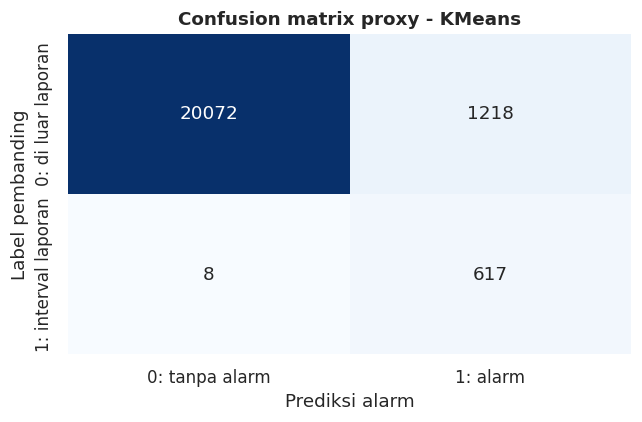

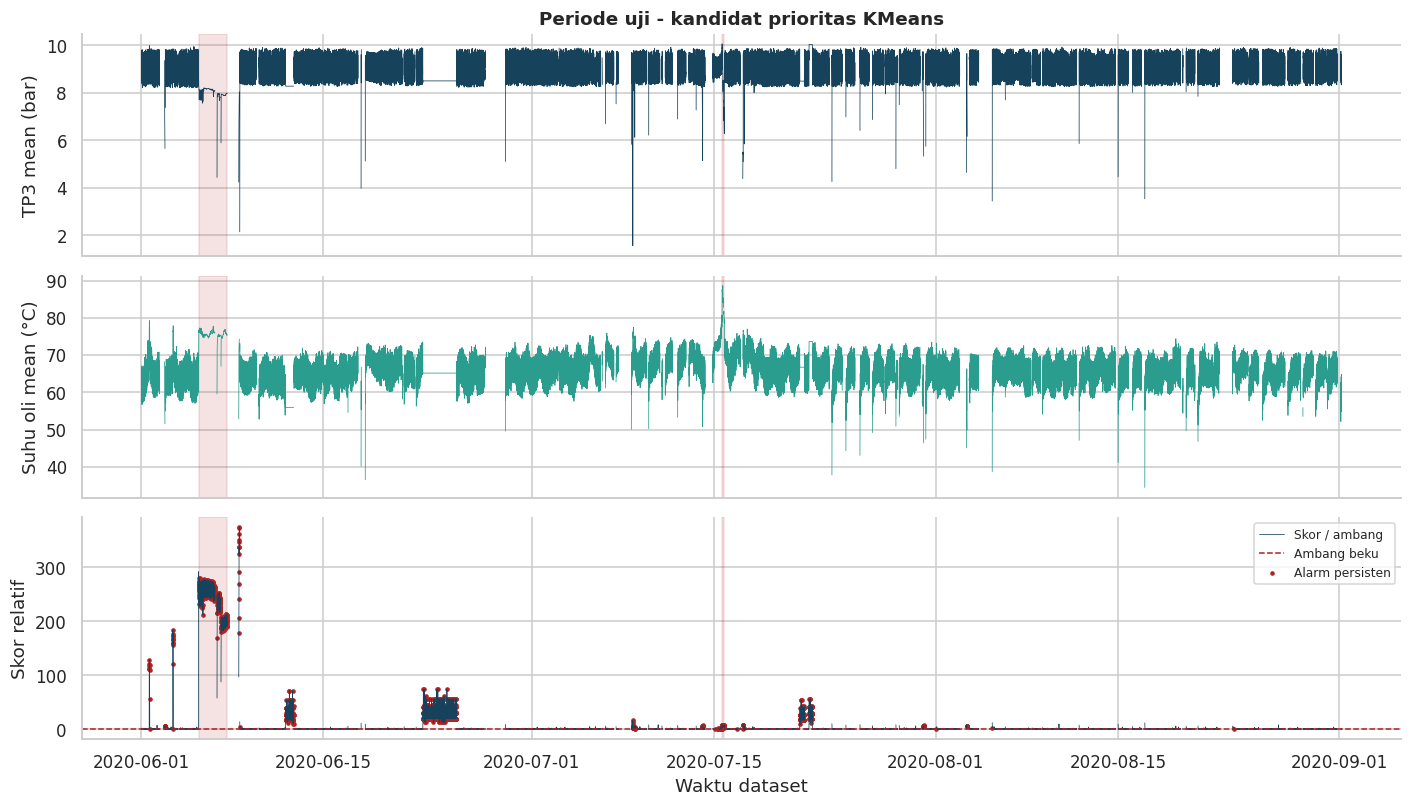

**Hasil benchmark KMeans:** 21,915 jendela, AP proxy 0.8685, precision 0.3362, recall 0.9872, F1 0.5016; 2/2 kejadian teramati terdeteksi, 0 kejadian tidak teramati. Episode di luar laporan per hari terpantau 0.394. Seluruh angka berasal dari run ini; benchmark telah diperiksa pada versi lama, sehingga bukan validasi independen baru. Alarm di luar laporan memerlukan konfirmasi teknisi.

In [21]:
if TEST_CACHE is None:
    assert SELECTED_MODEL == FROZEN_SELECTED_MODEL
    assert {n: joblib.hash(FITTED[n]["pipeline"]) for n in MODEL_NAMES} == FROZEN_MODEL_HASHES
    assert {n: FITTED[n]["threshold"] for n in MODEL_NAMES} == FROZEN_THRESHOLDS
    rows = []
    test_events = []
    for name in MODEL_NAMES:
        prediction = predict_bundle(FITTED[name], X_test)
        PREDICTIONS[("test", name)] = prediction
        row=evaluate_predictions(name,prediction)
        row.update({"role":"baseline" if name=="KMeans" else "kandidat",
                    "validation_method":"Temporal benchmark Juni-akhir; konfigurasi beku",
                    "threshold_source":"P99 kalibrasi Februari akhir","persistence_windows":PERSISTENCE_WINDOWS})
        rows.append(row)
        events = interval_evaluation(prediction)
        events.insert(0, "model", name)
        test_events.append(events)
    control_test = pd.DataFrame({"score": 0.0, "exceed": 0, "alarm": 0}, index=X_test.index)
    rows.append(evaluate_predictions("Kontrol_tanpa_alarm", control_test))
    TEST_CACHE = {"metrics": pd.DataFrame(rows),
                  "events": pd.concat(test_events, ignore_index=True),
                  "selected_model": SELECTED_MODEL}
else:
    assert TEST_CACHE["selected_model"] == SELECTED_MODEL
    assert {n: joblib.hash(FITTED[n]["pipeline"]) for n in MODEL_NAMES} == FROZEN_MODEL_HASHES
    assert {n: FITTED[n]["threshold"] for n in MODEL_NAMES} == FROZEN_THRESHOLDS
    print("Evaluasi sudah tersimpan; menampilkan kembali hasil uji yang sama.")
test_metrics = TEST_CACHE["metrics"]
test_events = TEST_CACHE["events"]
display(test_metrics.round(4))
display(test_events)

selected_test = PREDICTIONS[("test", SELECTED_MODEL)]
y_test_proxy = meta.loc[selected_test.index, "y_report"]
cm = confusion_matrix(y_test_proxy, selected_test["alarm"], labels=[0, 1])
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["0: tanpa alarm", "1: alarm"],
            yticklabels=["0: di luar laporan", "1: interval laporan"])
ax.set(xlabel="Prediksi alarm", ylabel="Label pembanding",
       title=f"Confusion matrix proxy - {SELECTED_MODEL}")
plt.tight_layout()
save_figure("10_benchmark_visual_01")

fig, axes = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True)
test_plot_index = meta.index[split_masks["test"]]
plot_tp3 = X_test["TP3__mean"].reindex(test_plot_index)
plot_oil = X_test["Oil_temperature__mean"].reindex(test_plot_index)
axes[0].plot(plot_tp3.index, plot_tp3, linewidth=0.5, color="#16425b")
axes[0].set(ylabel="TP3 mean (bar)", title=f"Periode uji - kandidat prioritas {SELECTED_MODEL}")
axes[1].plot(plot_oil.index, plot_oil, linewidth=0.5, color="#2a9d8f")
axes[1].set_ylabel("Suhu oli mean (°C)")
relative_score = selected_test["score"] / max(FITTED[SELECTED_MODEL]["threshold"], np.finfo(float).eps)
plot_score = relative_score.reindex(test_plot_index)
axes[2].plot(plot_score.index, plot_score, linewidth=0.5, color=COLORS[SELECTED_MODEL], label="Skor / ambang")
axes[2].axhline(1.0, color="#b22222", linestyle="--", linewidth=1, label="Ambang beku")
alarm_times = selected_test.index[selected_test["alarm"].eq(1)]
axes[2].scatter(alarm_times, relative_score.loc[alarm_times], s=4, color="#b22222", label="Alarm persisten")
axes[2].set(ylabel="Skor relatif", xlabel="Waktu dataset")
for event in FAILURES.itertuples():
    if event.end >= X_test.index.min():
        for ax in axes:
            ax.axvspan(event.start, event.end, color="#b22222", alpha=0.13)
axes[2].legend(loc="upper right", fontsize=8)
plt.tight_layout()
save_figure("10_benchmark_visual_02")
test_row = test_metrics.set_index("model").loc[SELECTED_MODEL]

assert FROZEN_CONFIGURATION["feature_config"] == FEATURE_CONFIG
assert FROZEN_CONFIGURATION["persistence"] == PERSISTENCE_WINDOWS
display(Markdown(
    f"**Hasil benchmark {SELECTED_MODEL}:** {int(test_row['n_windows']):,} jendela, "
    f"AP proxy {test_row['AP_proxy']:.4f}, precision {test_row['precision_proxy']:.4f}, "
    f"recall {test_row['recall_proxy']:.4f}, F1 {test_row['F1_proxy']:.4f}; "
    f"{int(test_row['reported_events_detected'])}/{int(test_row['reported_events_observed'])} "
    f"kejadian teramati terdeteksi, {int(test_row['unobserved_events'])} kejadian tidak teramati. "
    f"Episode di luar laporan per hari terpantau {test_row['outside_report_episodes_per_monitored_day']:.3f}. "
    "Seluruh angka berasal dari run ini; benchmark telah diperiksa pada versi lama, sehingga "
    "bukan validasi independen baru. Alarm di luar laporan memerlukan konfirmasi teknisi."
))

**SECTION 11: Diagnosis validasi, pergeseran distribusi, dan error analysis**

Sampel yang gagal, kelompok beban, dan deviasi fitur pada validasi digunakan untuk merancang eksperimen setelah UTS, tanpa retuning benchmark.

In [22]:
selected_val_prediction = PREDICTIONS[("validation", SELECTED_MODEL)]
error_frame = selected_val_prediction.join(meta[["y_report", "event_number"]])
error_frame["FN_proxy"] = error_frame["y_report"].eq(1) & error_frame["alarm"].eq(0)
error_frame["outside_report_alarm"] = error_frame["y_report"].eq(0) & error_frame["alarm"].eq(1)
error_frame["kondisi_beban"] = pd.cut(
    X_val["motor_load_fraction"], bins=[-0.001, 0.01, 0.5, 1.001],
    labels=["Beban jarang", "Campuran", "Beban dominan"])
error_slices = error_frame.groupby("kondisi_beban", observed=False).agg(
    n_windows=("alarm", "size"), reported_windows=("y_report", "sum"),
    alarm_windows=("alarm", "sum"), missed_report_windows=("FN_proxy", "sum"),
    alarms_outside_report=("outside_report_alarm", "sum"))
error_slices["miss_rate_proxy"] = error_slices["missed_report_windows"].div(
    error_slices["reported_windows"].replace(0, np.nan))
error_slices["alarm_rate"] = error_slices["alarm_windows"].div(
    error_slices["n_windows"].replace(0, np.nan))
display(error_slices.round(4))
display(interval_evaluation(selected_val_prediction))
validation_alarm_segments = alarm_segments(selected_val_prediction)
display(validation_alarm_segments.head(10))

error_sample = error_frame.loc[error_frame["FN_proxy"] | error_frame["outside_report_alarm"]]
display(error_sample.join(X_val[["TP3__mean", "Oil_temperature__mean",
                                 "Motor_current__mean", "pressure_gap_mean"]]).head(8))

selected_pipe = FITTED[SELECTED_MODEL]["pipeline"]
selected_names = np.asarray(FEATURE_COLUMNS)[
    selected_pipe.named_steps["constant_filter"].get_support()]
Z_val_before_pca = transformed_features(selected_pipe, X_val, include_pca=False)
alarm_mask = selected_val_prediction["alarm"].eq(1).to_numpy()
if alarm_mask.any():
    deviation_profile = pd.DataFrame({
        "fitur": selected_names,
        "mean_abs_z_on_alarm": np.abs(Z_val_before_pca[alarm_mask]).mean(axis=0),
        "mean_abs_z_all_validation": np.abs(Z_val_before_pca).mean(axis=0),
    }).sort_values("mean_abs_z_on_alarm", ascending=False)
else:
    deviation_profile = pd.DataFrame(
        columns=["fitur", "mean_abs_z_on_alarm", "mean_abs_z_all_validation"])
display(deviation_profile.head(10).round(4))


drift_rows=[]
for column in ["TP3__mean","Oil_temperature__mean","Motor_current__mean","pressure_gap_mean"]:
    ref_std=float(X_train[column].std())
    for month in X_val.index.to_period("M").unique():
        part=X_val.loc[X_val.index.to_period("M")==month,column]
        drift_rows.append({"feature":column,"month":str(month),"train_mean":X_train[column].mean(),
            "validation_month_mean":part.mean(),
            "standardized_mean_difference":(part.mean()-X_train[column].mean())/ref_std if ref_std>0 else np.nan})
drift_diagnostics=pd.DataFrame(drift_rows)
display(drift_diagnostics.round(4))
display(Markdown(
    f"**Error validasi:** {int(error_frame.FN_proxy.sum())} jendela laporan tanpa alarm dan "
    f"{int(error_frame.outside_report_alarm.sum()):,} jendela alarm di luar laporan. "
    "Perbedaan mean terstandardisasi bersifat deskriptif; tidak otomatis membuktikan penyebab musiman "
    "atau kerusakan. Deviasi fitur pada alarm bukan feature importance kausal."
))

,n_windows,reported_windows,alarm_windows,missed_report_windows,alarms_outside_report,miss_rate_proxy,alarm_rate
kondisi_beban,,,,,,,
Beban jarang,16107,363,2160,2,1799,0.0055,0.1341
Campuran,5120,1,234,1,234,1.0000,0.0457
Beban dominan,59,0,15,0,15,NaN,0.2542


,event_id,report_start,report_end,expected_overlap_windows,usable_overlap_windows,observed_report_windows,decision_windows_in_report,post_report_label_windows,coverage_fraction,status_observation,detected_during_report,first_alarm,delay_from_report_start_min
0,F01,2020-04-18 00:00:00,2020-04-18 23:59:00,288,286,286,285,1,0.993056,teramati_sebagian,True,2020-04-18 00:05:00,5.0
1,F02,2020-05-29 23:30:00,2020-05-30 06:00:00,78,78,78,78,0,1.000000,teramati_penuh,True,2020-05-29 23:35:00,5.0


,start_alarm,last_alarm,n_windows,alarm_window_minutes,decision_span_minutes,overlaps_report,matching_reports
0,2020-03-02 16:45:00,2020-03-02 16:45:00,1,5.0,0.0,False,
1,2020-03-02 17:25:00,2020-03-02 17:25:00,1,5.0,0.0,False,
2,2020-03-04 16:30:00,2020-03-04 16:30:00,1,5.0,0.0,False,
3,2020-03-05 04:25:00,2020-03-05 04:25:00,1,5.0,0.0,False,
4,2020-03-05 07:40:00,2020-03-05 07:40:00,1,5.0,0.0,False,
5,2020-03-05 10:00:00,2020-03-05 10:05:00,2,10.0,5.0,False,
6,2020-03-06 09:05:00,2020-03-06 09:05:00,1,5.0,0.0,False,
7,2020-03-06 18:45:00,2020-03-06 18:50:00,2,10.0,5.0,False,
8,2020-03-06 21:55:00,2020-03-06 23:05:00,15,75.0,70.0,False,
9,2020-03-09 06:25:00,2020-03-09 06:25:00,1,5.0,0.0,False,


,score,exceed,alarm,y_report,event_number,FN_proxy,outside_report_alarm,kondisi_beban,TP3__mean,Oil_temperature__mean,Motor_current__mean,pressure_gap_mean
window_end,,,,,,,,,,,,
2020-03-02 16:45:00,69.677885,1,1,0,0,False,True,Campuran,9.464267,71.991667,4.669083,0.001333
2020-03-02 17:25:00,457.247854,1,1,0,0,False,True,Campuran,9.396200,72.067500,4.998417,0.002067
2020-03-04 16:30:00,79.081615,1,1,0,0,False,True,Campuran,8.812400,68.701667,4.812750,0.001333
2020-03-05 04:25:00,738.195989,1,1,0,0,False,True,Beban dominan,10.127533,72.445833,5.792333,0.004800
2020-03-05 07:40:00,207.863338,1,1,0,0,False,True,Campuran,9.251933,71.071667,4.873083,0.003000
2020-03-05 10:00:00,781.942441,1,1,0,0,False,True,Campuran,9.935200,74.154167,5.945917,0.004267
2020-03-05 10:05:00,372.668912,1,1,0,0,False,True,Campuran,10.161667,75.085833,5.312500,0.003000
2020-03-06 09:05:00,89.568699,1,1,0,0,False,True,Campuran,9.938200,73.860833,4.848583,0.003200


,fitur,mean_abs_z_on_alarm,mean_abs_z_all_validation
6,DV_pressure__mean,49.2004,6.4214
18,Pressure_switch__duty,15.8923,2.2768
17,MPG__duty,5.5395,1.5405
16,Towers__duty,5.3638,1.5115
15,DV_eletric__duty,5.1929,1.5008
14,COMP__duty,4.8927,1.4663
4,H1__mean,4.3990,1.4007
0,TP2__mean,4.2933,1.3887
10,Oil_temperature__mean,4.1228,1.8838
12,Motor_current__mean,2.0382,1.1160


,feature,month,train_mean,validation_month_mean,standardized_mean_difference
0,TP3__mean,2020-03,8.9633,9.0441,0.1682
1,TP3__mean,2020-04,8.9633,9.0322,0.1435
2,TP3__mean,2020-05,8.9633,8.8923,-0.1476
3,Oil_temperature__mean,2020-03,56.7828,62.1864,1.6209
4,Oil_temperature__mean,2020-04,56.7828,59.4607,0.8033
5,Oil_temperature__mean,2020-05,56.7828,62.2414,1.6374
6,Motor_current__mean,2020-03,1.2381,2.0769,0.5208
7,Motor_current__mean,2020-04,1.2381,1.8554,0.3832
8,Motor_current__mean,2020-05,1.2381,1.9839,0.4630
9,pressure_gap_mean,2020-03,-0.0022,0.0006,1.5528


**Error validasi:** 3 jendela laporan tanpa alarm dan 2,048 jendela alarm di luar laporan. Perbedaan mean terstandardisasi bersifat deskriptif; tidak otomatis membuktikan penyebab musiman atau kerusakan. Deviasi fitur pada alarm bukan feature importance kausal.

**SECTION 12: Inferensi mandiri dari sensor mentah dan pemeriksaan integritas**

Artefak menyimpan kolom, pipeline, ambang dan aturan fitur; fungsi inferensi tidak membaca label atau melakukan fit ulang. State menjaga persistensi antarpotongan data.


In [23]:
export_bundle={
    "project_id":"B10","notebook_version":NOTEBOOK_VERSION,"selected_model":SELECTED_MODEL,
    "pipeline":FITTED[SELECTED_MODEL]["pipeline"],"threshold":FITTED[SELECTED_MODEL]["threshold"],
    "feature_columns":FEATURE_COLUMNS.copy(),"feature_config":dict(FEATURE_CONFIG),
    "window":WINDOW,"persistence_windows":PERSISTENCE_WINDOWS,"cpu_threads":CPU_THREADS,
    "score_direction":"higher_is_more_anomalous","versions":VERSIONS,
    "source_sha256":AUDIT["source_sha256"],
    "candidates":{n:FITTED[n] for n in MODEL_NAMES}}
demo_features=X_val.iloc[:12].copy()
demo_start=demo_features.index.min()-WINDOW_DELTA
demo_end=demo_features.index.max()
demo_raw=raw.loc[(raw.index>=demo_start)&(raw.index<demo_end)].copy()
demo_prediction,demo_quality,demo_state=infer_raw_completed(demo_raw,export_bundle,observed_until=demo_end)
demo_direct=predict_bundle(export_bundle,demo_features)
assert demo_prediction.index.equals(demo_direct.index)
np.testing.assert_allclose(demo_prediction.score,demo_direct.score,rtol=1e-10,atol=1e-10)
np.testing.assert_array_equal(demo_prediction.alarm,demo_direct.alarm)
display(demo_prediction)

bundle_path=OUTPUT_DIR/"B10_model_bundle.joblib"
joblib.dump(export_bundle,bundle_path,compress=3)
reloaded=joblib.load(bundle_path)
serialized_prediction=predict_bundle(reloaded,demo_features)
np.testing.assert_allclose(serialized_prediction.score,demo_direct.score,rtol=1e-12,atol=1e-12)
np.testing.assert_array_equal(serialized_prediction.alarm,demo_direct.alarm)

# Uji batas alarm memakai flag buatan
flags=pd.Series([1,1,1,1,0,1,1,1],index=pd.date_range("2020-01-01",periods=8,freq=WINDOW))
expected=np.array([0,0,1,1,0,0,0,1])
np.testing.assert_array_equal(persistent_alarm(flags),expected)
part1,state=persistent_alarm(flags.iloc[:2],return_state=True)
part2,state=persistent_alarm(flags.iloc[2:],state=state,return_state=True)
np.testing.assert_array_equal(pd.concat([part1,part2]),expected)
gap_flags=flags.iloc[[0,1,3,4]]
np.testing.assert_array_equal(persistent_alarm(gap_flags),[0,0,0,0])

# Causality: menambahkan data dari jendela lebih akhir tidak mengubah fitur yang selesai sebelumnya.
extra_end=demo_end+pd.Timedelta(hours=1)
extra_raw=raw.loc[(raw.index>=demo_start)&(raw.index<extra_end)]
extended_features,extended_quality=build_completed_windows(extra_raw,FEATURE_CONFIG,extra_end)
demo_built,_=build_completed_windows(demo_raw,FEATURE_CONFIG,demo_end)
pd.testing.assert_frame_equal(demo_built,extended_features.loc[demo_built.index],check_exact=False,rtol=1e-10,atol=1e-10)
(OUTPUT_DIR/"b10_runtime.py").write_text(RUNTIME_SOURCE,encoding="utf-8")
spec=importlib.util.spec_from_file_location("b10_runtime_exported",OUTPUT_DIR/"b10_runtime.py")
runtime_module=importlib.util.module_from_spec(spec)
spec.loader.exec_module(runtime_module)
independent,_,_=runtime_module.infer_raw_completed(demo_raw,reloaded,observed_until=demo_end)
np.testing.assert_allclose(independent.score,demo_direct.score,rtol=1e-12,atol=1e-12)
integrity_checks=pd.DataFrame([
    ("Raw sensor -> fitur -> skor sama dengan matriks eksperimen",True),
    ("Serialisasi joblib mempertahankan skor dan alarm",True),
    ("State antarbatch sama dengan batch penuh pada batas persistensi",True),
    ("Jeda waktu mereset persistensi",True),
    ("Fitur jendela selesai tidak berubah oleh tambahan data masa depan",True),
    ("Modul file mandiri bekerja tanpa global notebook",True),
],columns=["pemeriksaan","lulus"])
display(integrity_checks)
display(Markdown(
    f"**Hasil inferensi nyata:** {len(demo_prediction)} jendela; "
    f"{int(demo_prediction.exceed.sum())} pelampauan dan {int(demo_prediction.alarm.sum())} alarm. "
    "Flag buatan hanya dipakai untuk memeriksa logika batas dan tidak masuk metrik eksperimen. "
    "Setiap batch raw harus mencakup jendela lengkap tanpa memecah satu jendela di tengah. "
    "Untuk streaming, teruskan state dan observed_until; buffer sampel sampai jendela selesai."
))

,score,exceed,alarm
window_end,,,
2020-03-01 04:05:00,28.505374,0,0
2020-03-01 04:10:00,8.242537,0,0
2020-03-01 04:15:00,33.947651,0,0
2020-03-01 04:20:00,40.508158,0,0
2020-03-01 04:25:00,27.546039,0,0
2020-03-01 04:30:00,8.872154,0,0
2020-03-01 04:35:00,46.390406,1,0
2020-03-01 04:40:00,43.695512,0,0
2020-03-01 04:45:00,24.554711,0,0


,pemeriksaan,lulus
0,Raw sensor -> fitur -> skor sama dengan matrik...,True
1,Serialisasi joblib mempertahankan skor dan alarm,True
2,State antarbatch sama dengan batch penuh pada ...,True
3,Jeda waktu mereset persistensi,True
4,Fitur jendela selesai tidak berubah oleh tamba...,True
5,Modul file mandiri bekerja tanpa global notebook,True


**Hasil inferensi nyata:** 12 jendela; 1 pelampauan dan 0 alarm. Flag buatan hanya dipakai untuk memeriksa logika batas dan tidak masuk metrik eksperimen. Setiap batch raw harus mencakup jendela lengkap tanpa memecah satu jendela di tengah. Untuk streaming, teruskan state dan observed_until; buffer sampel sampai jendela selesai.

**SECTION 13: Ringkasan visual penyiapan data**

Bandingkan skala sebelum/sesudah pada jendela train yang sama dan tampilkan perubahan unit analisis serta dimensi.

,Tahap,Jumlah unit,Jenis unit,Dimensi representasi
0,Data sensor awal,1516948,sampel waktu,15
1,Fitur jendela siap eksperimen,50276,jendela terpakai,25
2,Filter konstan + StandardScaler,4982,jendela train,22
3,Kandidat PCA,4982,jendela train,7


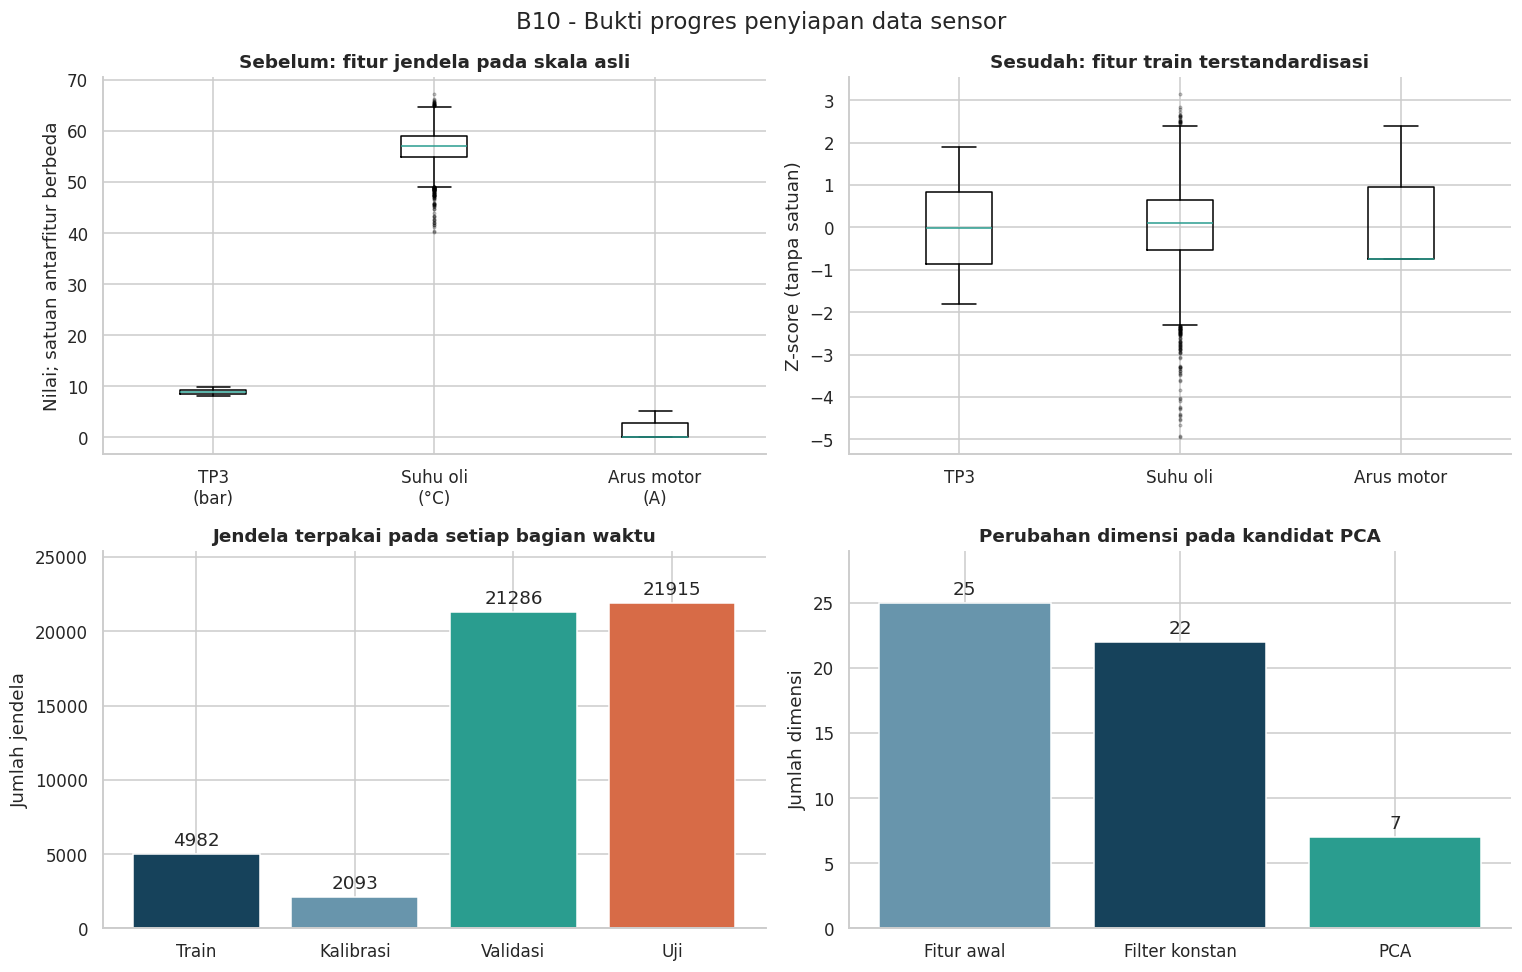

**Ringkasan:** 1,516,948 sampel mentah menjadi 50,276 jendela terpakai; 25 fitur awal -> 22 fitur nonkonstan -> 7 komponen PCA. Perubahan jumlah baris menjadi jendela adalah perubahan unit analisis, bukan seluruhnya data yang dibuang. Eksklusi kualitas dan embargo dihitung terpisah pada ringkasan jendela.

In [24]:
s13_required = [
    "raw", "X_train", "X_cal", "X_val", "X_test",
    "FITTED", "FEATURE_COLUMNS", "transformed_features"
]
s13_missing = [name for name in s13_required if name not in globals()]

if s13_missing:
    raise RuntimeError(
        "Jalankan Section 1-13 terlebih dahulu. Belum tersedia: "
        + ", ".join(s13_missing)
    )

s13_pipe = FITTED["KMeans"]["pipeline"]
s13_kept = np.asarray(FEATURE_COLUMNS)[
    s13_pipe.named_steps["constant_filter"].get_support()
]

s13_scaled = pd.DataFrame(
    transformed_features(s13_pipe, X_train, include_pca=False),
    index=X_train.index,
    columns=s13_kept
)

s13_pca = FITTED["PCA_KMeans"]["pipeline"].named_steps["pca"]
s13_n_pc = int(s13_pca.n_components_)
s13_variance = float(s13_pca.explained_variance_ratio_.sum())

s13_splits = pd.Series({
    "Train": len(X_train),
    "Kalibrasi": len(X_cal),
    "Validasi": len(X_val),
    "Uji": len(X_test)
})

s13_progress = pd.DataFrame([
    [
        "Data sensor awal",
        len(raw),
        "sampel waktu",
        raw.shape[1]
    ],
    [
        "Fitur jendela siap eksperimen",
        int(s13_splits.sum()),
        "jendela terpakai",
        len(FEATURE_COLUMNS)
    ],
    [
        "Filter konstan + StandardScaler",
        len(X_train),
        "jendela train",
        len(s13_kept)
    ],
    [
        "Kandidat PCA",
        len(X_train),
        "jendela train",
        s13_n_pc
    ],
], columns=[
    "Tahap",
    "Jumlah unit",
    "Jenis unit",
    "Dimensi representasi"
])

display(s13_progress)

s13_columns = [
    "TP3__mean",
    "Oil_temperature__mean",
    "Motor_current__mean"
]

s13_labels = [
    "TP3\n(bar)",
    "Suhu oli\n(°C)",
    "Arus motor\n(A)"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, frame, title, ylabel, labels in [
    (
        axes[0, 0],
        X_train,
        "Sebelum: fitur jendela pada skala asli",
        "Nilai; satuan antarfitur berbeda",
        s13_labels
    ),
    (
        axes[0, 1],
        s13_scaled,
        "Sesudah: fitur train terstandardisasi",
        "Z-score (tanpa satuan)",
        ["TP3", "Suhu oli", "Arus motor"]
    ),
]:
    ax.boxplot(
        [frame[c].dropna().to_numpy() for c in s13_columns],
        flierprops={"markersize": 1.5, "alpha": 0.3}
    )
    ax.set_xticks([1, 2, 3], labels)
    ax.set(title=title, ylabel=ylabel)

s13_bars = axes[1, 0].bar(
    s13_splits.index,
    s13_splits.values,
    color=["#16425b", "#6895ac", "#2a9d8f", "#d76b47"]
)
axes[1, 0].bar_label(s13_bars, fmt="%.0f", padding=3)
axes[1, 0].set(
    title="Jendela terpakai pada setiap bagian waktu",
    ylabel="Jumlah jendela"
)
axes[1, 0].margins(y=0.16)

s13_dims = [
    len(FEATURE_COLUMNS),
    len(s13_kept),
    s13_n_pc
]
s13_bars = axes[1, 1].bar(
    ["Fitur awal", "Filter konstan", "PCA"],
    s13_dims,
    color=["#6895ac", "#16425b", "#2a9d8f"]
)
axes[1, 1].bar_label(s13_bars, fmt="%.0f", padding=3)
axes[1, 1].set(
    title="Perubahan dimensi pada kandidat PCA",
    ylabel="Jumlah dimensi"
)
axes[1, 1].margins(y=0.16)

fig.suptitle(
    "B10 - Bukti progres penyiapan data sensor",
    fontsize=15
)
plt.tight_layout()
save_figure("13_ringkasan_preprocessing")
display(Markdown(
    f"**Ringkasan:** {len(raw):,} sampel mentah menjadi {sum(len(x) for x in X.values()):,} "
    f"jendela terpakai; {len(FEATURE_COLUMNS)} fitur awal -> {len(kept_features)} fitur nonkonstan "
    f"-> {pca_model.n_components_} komponen PCA. Perubahan jumlah baris menjadi jendela adalah "
    "perubahan unit analisis, bukan seluruhnya data yang dibuang. Eksklusi kualitas dan embargo "
    "dihitung terpisah pada ringkasan jendela."
))

**SECTION 14: Hasil akhir run, dan kesimpulan awal**

Ringkasan mengambil angka hasil, mempertahankan perbedaan AP dan F1, serta menyatakan pekerjaan lanjutan beserta bukti penerimaannya.

,AP validasi,AP uji,Precision uji,Recall uji,F1 uji,Alarm (%),Interval terdeteksi,Pilihan validasi
model,,,,,,,,
Kontrol_tanpa_alarm,-,0.0285,0.0000,0.0000,0.0000,0.0000,0/2,-
KMeans,0.2974,0.8685,0.3362,0.9872,0.5016,8.3733,2/2,Ya
PCA_KMeans,0.2907,0.8667,0.3342,0.9872,0.4994,8.4235,2/2,-
IsolationForest,0.1105,0.4293,0.4350,0.9856,0.6036,6.4613,2/2,-


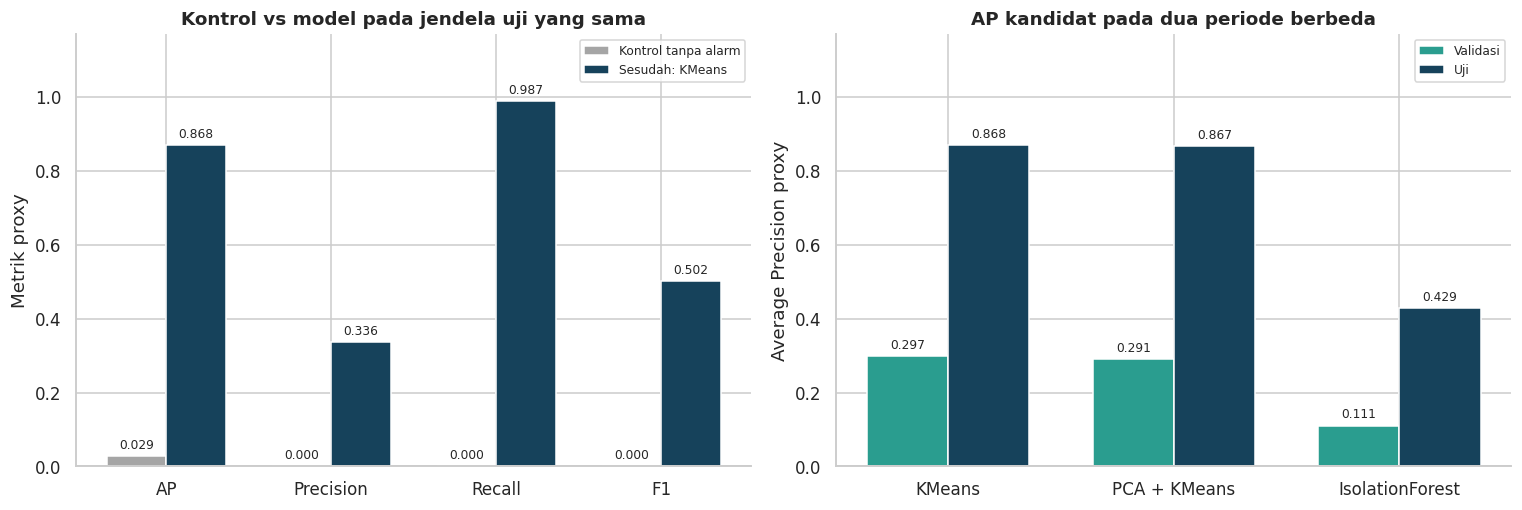

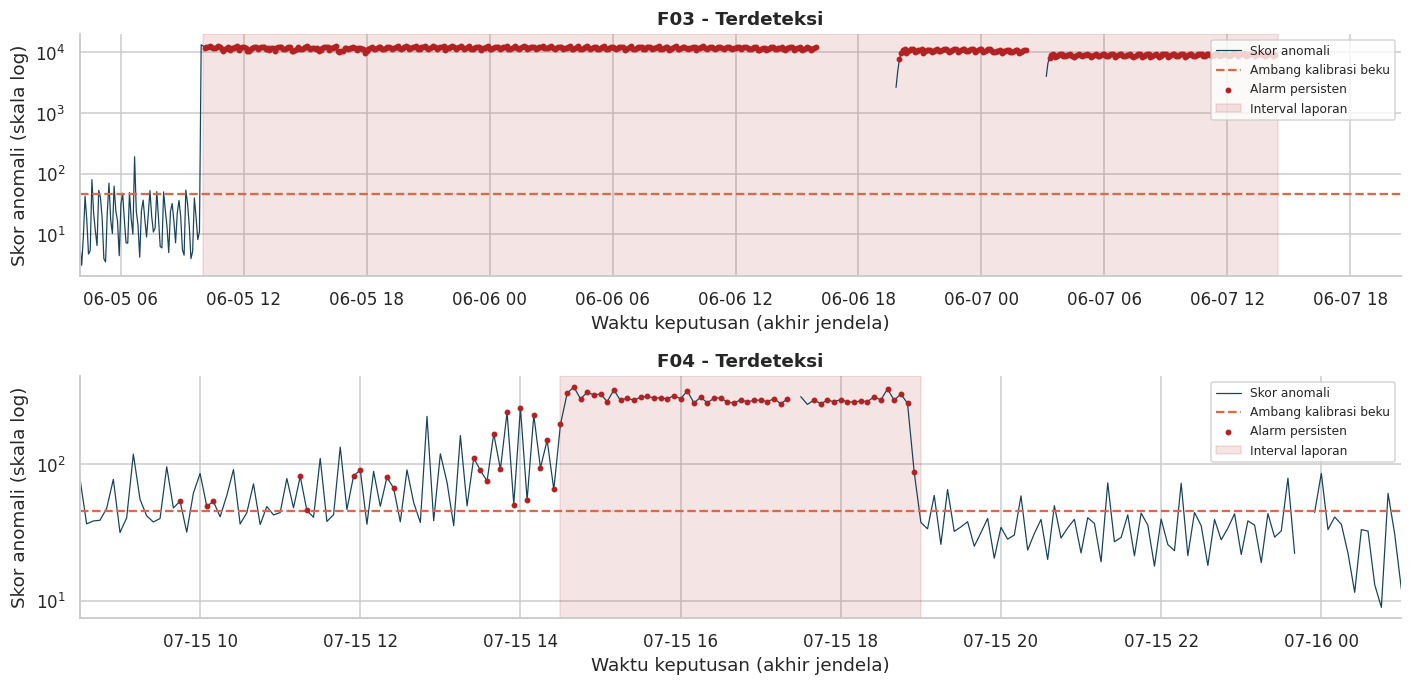

,Interval,Awal laporan,Akhir laporan,Terdeteksi saat laporan,Alarm pertama dalam laporan,Jeda dari awal laporan (menit)
0,F03,2020-06-05 10:00:00,2020-06-07 14:30:00,True,2020-06-05 10:05:00,5.0
1,F04,2020-07-15 14:30:00,2020-07-15 19:00:00,True,2020-07-15 14:35:00,5.0


,Tujuan / batas penggunaan,Status,Bukti hasil
0,Menghasilkan skor dan alarm,Tercapai,"21,915 jendela uji; proporsi alarm 8.37%"
1,Membandingkan kandidat,Tercapai,3 kandidat; pilihan dari AP validasi: KMeans
2,Kesesuaian dengan interval gangguan,Didukung pada seluruh interval uji,2/2 interval terdeteksi; 8 jendela laporan tan...
3,Menilai ketepatan alarm,Masih memerlukan verifikasi,"Precision proxy 0.3362; 1,218 alarm di luar la..."
4,Membuktikan kelayakan operasional,Belum dapat disimpulkan,Label laporan lemah dan kejadian terbatas pada...


**Kesimpulan run:** KMeans dipilih dari AP validasi 0.2974; benchmark menghasilkan AP 0.8685, precision 0.3362, recall 0.9872, F1 0.5016. Deteksi 2/2 kejadian teramati, 8 jendela laporan tanpa alarm, dan 1,218 alarm jendela di luar laporan. F1 validasi terbaik berasal dari IsolationForest; pilihan AP tidak menyatakan dominasi seluruh metrik. Alur deteksi dan pembandingan classical ML tersedia, namun diagnosis penyebab, peringatan dini, kelayakan industri, dan generalisasi lintas mesin belum terbukti.

In [25]:
s14_required = [
    "test_metrics", "validation_metrics", "test_events", "PREDICTIONS",
    "SELECTED_MODEL", "FROZEN_SELECTED_MODEL", "FROZEN_MODEL_HASHES",
    "FROZEN_THRESHOLDS", "FITTED", "MODEL_NAMES", "meta", "X_test"
]
s14_missing = [name for name in s14_required if name not in globals()]

if s14_missing:
    raise RuntimeError(
        "Jalankan Section 1-13 terlebih dahulu. Belum tersedia: "
        + ", ".join(s14_missing)
    )

if (
    SELECTED_MODEL != FROZEN_SELECTED_MODEL
    or any(
        joblib.hash(FITTED[n]["pipeline"]) != FROZEN_MODEL_HASHES[n]
        or FITTED[n]["threshold"] != FROZEN_THRESHOLDS[n]
        for n in MODEL_NAMES
    )
):
    raise RuntimeError(
        "Model/ambang berubah. Gunakan hasil evaluasi "
        "dengan konfigurasi yang konsisten."
    )

s14_val = validation_metrics.set_index("model")
s14_test = test_metrics.set_index("model")
s14_model = SELECTED_MODEL
s14_row = s14_test.loc[s14_model]
s14_control = s14_test.loc["Kontrol_tanpa_alarm"]
s14_prediction = PREDICTIONS[("test", s14_model)].copy()

if not s14_prediction.index.equals(X_test.index):
    raise ValueError(
        "Prediksi uji dan fitur uji tidak memiliki jendela yang sama."
    )

s14_y = meta.loc[s14_prediction.index, "y_report"].astype(int)

s14_outside = int(
    ((s14_y == 0) & (s14_prediction["alarm"] == 1)).sum()
)
s14_missed = int(
    ((s14_y == 1) & (s14_prediction["alarm"] == 0)).sum()
)

s14_events = test_events.loc[
    test_events["model"].eq(s14_model)
].copy()

s14_n_events = len(s14_events)
s14_detected = int(s14_events["detected_during_report"].sum())

s14_table = s14_test.loc[
    ["Kontrol_tanpa_alarm"] + list(MODEL_NAMES),
    [
        "AP_proxy", "precision_proxy",
        "recall_proxy", "F1_proxy", "alarm_rate"
    ]
].copy()

s14_table.insert(
    0,
    "AP validasi",
    s14_val["AP_proxy"].reindex(s14_table.index)
)

s14_table["Interval terdeteksi"] = [
    (
        f"{int(s14_test.loc[n, 'reported_events_detected'])}/"
        f"{int(s14_test.loc[n, 'reported_events_observed'])}"
    )
    for n in s14_table.index
]

s14_table["Pilihan validasi"] = [
    "Ya" if n == s14_model else "-"
    for n in s14_table.index
]

s14_table = s14_table.rename(columns={
    "AP_proxy": "AP uji",
    "precision_proxy": "Precision uji",
    "recall_proxy": "Recall uji",
    "F1_proxy": "F1 uji",
    "alarm_rate": "Alarm (%)"
})

s14_table["Alarm (%)"] = 100 * s14_table["Alarm (%)"]
display(s14_table.round(4).fillna("-"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

s14_metrics = [
    "AP_proxy", "precision_proxy", "recall_proxy", "F1_proxy"
]
s14_x = np.arange(len(s14_metrics))

for offset, row, label, color in [
    (-0.18, s14_control, "Kontrol tanpa alarm", "#a5a5a5"),
    (0.18, s14_row, f"Sesudah: {s14_model}", "#16425b"),
]:
    bars = axes[0].bar(
        s14_x + offset,
        row[s14_metrics].to_numpy(dtype=float),
        width=0.36,
        label=label,
        color=color
    )
    axes[0].bar_label(bars, fmt="%.3f", padding=3, fontsize=8)

axes[0].set_xticks(s14_x, ["AP", "Precision", "Recall", "F1"])
axes[0].set(
    title="Kontrol vs model pada jendela uji yang sama",
    ylabel="Metrik proxy",
    ylim=(0, 1.17)
)
axes[0].legend(fontsize=8)

s14_x = np.arange(len(MODEL_NAMES))

for offset, frame, label, color in [
    (-0.18, s14_val, "Validasi", "#2a9d8f"),
    (0.18, s14_test, "Uji", "#16425b"),
]:
    bars = axes[1].bar(
        s14_x + offset,
        frame.loc[MODEL_NAMES, "AP_proxy"].to_numpy(),
        width=0.36,
        label=label,
        color=color
    )
    axes[1].bar_label(bars, fmt="%.3f", padding=3, fontsize=8)

axes[1].set_xticks(
    s14_x,
    [n.replace("_", " + ") for n in MODEL_NAMES]
)
axes[1].set(
    title="AP kandidat pada dua periode berbeda",
    ylabel="Average Precision proxy",
    ylim=(0, 1.17)
)
axes[1].legend(fontsize=8)

plt.tight_layout()
save_figure("14_hasil_01")

if s14_n_events:
    s14_threshold = float(FITTED[s14_model]["threshold"])

    s14_grid = pd.date_range(
        s14_prediction.index.min(),
        s14_prediction.index.max(),
        freq=WINDOW
    )
    s14_plot = s14_prediction.reindex(s14_grid)

    fig, axes = plt.subplots(
        s14_n_events,
        1,
        figsize=(13, 3.2 * s14_n_events),
        squeeze=False
    )

    for ax, event in zip(axes[:, 0], s14_events.itertuples()):
        start = pd.Timestamp(event.report_start)
        end = pd.Timestamp(event.report_end)

        part = s14_plot.loc[
            start - pd.Timedelta(hours=6):
            end + pd.Timedelta(hours=6)
        ]

        ax.plot(
            part.index,
            part["score"],
            color="#16425b",
            lw=0.8,
            label="Skor anomali"
        )
        ax.axhline(
            s14_threshold,
            color="#d76b47",
            ls="--",
            label="Ambang kalibrasi beku"
        )

        alarm = part.loc[part["alarm"].eq(1)]
        ax.scatter(
            alarm.index,
            alarm["score"],
            color="#b22222",
            s=8,
            label="Alarm persisten",
            zorder=3
        )
        ax.axvspan(
            start,
            end,
            color="#b22222",
            alpha=0.12,
            label="Interval laporan"
        )

        ax.set(
            title=(
                f"{event.event_id} - "
                f"{'Terdeteksi' if event.detected_during_report else 'Belum terdeteksi'}"
            ),
            ylabel="Skor anomali",
            xlabel="Waktu keputusan (akhir jendela)"
        )
        ax.set_xlim(
            start - pd.Timedelta(hours=6),
            end + pd.Timedelta(hours=6)
        )

        if s14_threshold > 0 and part["score"].dropna().gt(0).all():
            ax.set_yscale("log")
            ax.set_ylabel("Skor anomali (skala log)")

        ax.legend(fontsize=8, loc="upper right")

    plt.tight_layout()
    save_figure("14_hasil_02")

display(
    s14_events[[
        "event_id", "report_start", "report_end",
        "detected_during_report", "first_alarm",
        "delay_from_report_start_min"
    ]].rename(columns={
        "event_id": "Interval",
        "report_start": "Awal laporan",
        "report_end": "Akhir laporan",
        "detected_during_report": "Terdeteksi saat laporan",
        "first_alarm": "Alarm pertama dalam laporan",
        "delay_from_report_start_min": "Jeda dari awal laporan (menit)"
    })
)

s14_goals = pd.DataFrame([
    [
        "Menghasilkan skor dan alarm",
        (
            "Tercapai"
            if np.isfinite(s14_prediction["score"]).all()
            else "Perlu pemeriksaan"
        ),
        (
            f"{len(s14_prediction):,} jendela uji; "
            f"proporsi alarm {s14_row['alarm_rate']:.2%}"
        )
    ],
    [
        "Membandingkan kandidat",
        "Tercapai",
        (
            f"{len(MODEL_NAMES)} kandidat; "
            f"pilihan dari AP validasi: {s14_model}"
        )
    ],
    [
        "Kesesuaian dengan interval gangguan",
        (
            "Didukung pada seluruh interval uji"
            if s14_n_events and s14_detected == s14_n_events
            else "Belum didukung pada seluruh interval uji"
        ),
        (
            f"{s14_detected}/{s14_n_events} interval terdeteksi; "
            f"{s14_missed} jendela laporan tanpa alarm"
        )
    ],
    [
        "Menilai ketepatan alarm",
        "Masih memerlukan verifikasi",
        (
            f"Precision proxy {s14_row['precision_proxy']:.4f}; "
            f"{s14_outside:,} alarm di luar laporan"
        )
    ],
    [
        "Membuktikan kelayakan operasional",
        "Belum dapat disimpulkan",
        "Label laporan lemah dan kejadian terbatas pada satu kompresor"
    ],
], columns=[
    "Tujuan / batas penggunaan",
    "Status",
    "Bukti hasil"
])

display(s14_goals)

s14_best_f1_val = s14_val["F1_proxy"].idxmax()
s14_delta_ap = float(
    s14_row["AP_proxy"] - s14_control["AP_proxy"]
)
display(Markdown(
    f"**Kesimpulan run:** {SELECTED_MODEL} dipilih dari AP validasi "
    f"{selected_val['AP_proxy']:.4f}; benchmark menghasilkan AP {test_row['AP_proxy']:.4f}, "
    f"precision {test_row['precision_proxy']:.4f}, recall {test_row['recall_proxy']:.4f}, "
    f"F1 {test_row['F1_proxy']:.4f}. "
    f"Deteksi {int(test_row['reported_events_detected'])}/{int(test_row['reported_events_observed'])} "
    f"kejadian teramati, {int(test_row['FN_proxy'])} jendela laporan tanpa alarm, "
    f"dan {int(test_row['FP_proxy']):,} alarm jendela di luar laporan. "
    f"F1 validasi terbaik berasal dari {s14_best_f1_val}; pilihan AP tidak menyatakan dominasi seluruh metrik. "
    "Alur deteksi dan pembandingan classical ML tersedia, namun diagnosis penyebab, peringatan dini, "
    "kelayakan industri, dan generalisasi lintas mesin belum terbukti."
))

**Kesimpulan Proyek pada Tahap UTS:**

Proyek ini telah menghasilkan alur classical machine learning untuk mendeteksi penyimpangan kondisi mesin industri menggunakan dataset MetroPT-3, mulai dari pemahaman data, EDA, preprocessing, rekayasa fitur, pemodelan, evaluasi temporal, hingga demonstrasi inferensi. Dataset yang dianalisis terdiri atas 1.516.948 observasi dengan 15 sensor, mencakup tekanan, suhu oli, arus motor, dan status digital. Pemeriksaan menunjukkan tidak terdapat nilai sensor yang hilang maupun timestamp duplikat setelah audit, tetapi ketidakteraturan waktu dan kelengkapan jendela tetap diperiksa sebelum data digunakan dalam eksperimen.

Pengolahan data menghasilkan 50.276 jendela lima menit yang digunakan pada bagian train, kalibrasi, validasi, dan benchmark. Setiap jendela direpresentasikan oleh 25 fitur, meliputi statistik sensor analog, proporsi aktif sinyal digital, serta tiga fitur rekayasa. Setelah filter fitur konstan, tersisa 22 fitur untuk pemodelan. Pada kandidat PCA + K-Means, representasi tersebut dipadatkan menjadi tujuh komponen yang mempertahankan sekitar 95,69% varians training. Seluruh transformasi yang memerlukan pembelajaran dipelajari hanya dari data training, sedangkan pembagian temporal, kalibrasi terpisah, dan embargo digunakan untuk mengendalikan risiko data leakage.

Tiga kandidat telah dibandingkan, yaitu K-Means, PCA + K-Means, dan Isolation Forest. Selain evaluasi terhadap laporan gangguan, eksperimen mencakup pengujian K=2-6, lima fold temporal pada periode referensi, ablation fitur, sensitivitas ambang dan persistensi, serta diagnosis kesalahan berdasarkan kondisi beban. Lima fold pada periode referensi digunakan untuk memeriksa kestabilan respons model; hasilnya tidak diposisikan sebagai bukti kemampuan mendeteksi gangguan apabila fold tersebut tidak memiliki kejadian laporan.

**Ringkasan Hasil Model**

| Model | AP validasi | AP benchmark | Precision proxy | Recall proxy | F1 proxy | Interval benchmark terdeteksi |
| :--- | ---: | ---: | ---: | ---: | ---: | :---: |
| K-Means | 0,2974 | 0,8685 | 0,3362 | 0,9872 | 0,5016 | 2/2 |
| PCA + K-Means | 0,2907 | 0,8667 | 0,3342 | 0,9872 | 0,4994 | 2/2 |
| Isolation Forest | 0,1105 | 0,4293 | 0,4350 | 0,9856 | 0,6036 | 2/2 |

K-Means dipilih berdasarkan AP validasi tertinggi, sehingga pemilihan model mengikuti kriteria yang ditetapkan sebelum pembacaan hasil benchmark. Pada 21.915 jendela benchmark, model ini menghasilkan AP sebesar 0,8685 dan recall proxy sebesar 0,9872. Kedua interval gangguan yang teramati pada benchmark berhasil terdeteksi, dengan alarm pertama dalam masing-masing interval tersedia lima menit setelah awal laporan. Temuan tersebut menunjukkan deteksi selama interval gangguan, tetapi belum membuktikan kemampuan memberikan peringatan sebelum gangguan terjadi.

Pemilihan K-Means tidak berarti model tersebut unggul pada seluruh metrik. Isolation Forest menghasilkan precision dan F1 proxy benchmark yang lebih tinggi, sedangkan K-Means lebih unggul dalam AP. Perbedaan ini menunjukkan bahwa kemampuan mengurutkan skor anomali dan ketepatan alarm pada satu konfigurasi ambang merupakan aspek evaluasi yang berbeda.

#### Output Penting dan Keterbatasan:

1. **Kepekaan terhadap interval laporan sudah terlihat, tetapi ketepatan alarm masih perlu diperbaiki.** K-Means melewatkan delapan jendela laporan dan menghasilkan 1.218 jendela alarm di luar laporan pada benchmark. Angka terakhir merupakan jumlah jendela, bukan jumlah episode alarm, serta belum dapat dinyatakan seluruhnya sebagai alarm palsu aktual karena kelengkapan laporan gangguan belum terverifikasi.

2. **PCA berhasil mengurangi dimensi, tetapi belum meningkatkan AP pada eksperimen ini.** Varians yang dipertahankan tidak sama dengan informasi kerusakan yang dipertahankan, sehingga penggunaan PCA tetap perlu dinilai berdasarkan hasil deteksi dan kebutuhan komputasi.

3. **Tiga fitur rekayasa belum menunjukkan peningkatan AP validasi.** Ablation menghasilkan AP sekitar 0,29749 untuk 22 fitur dasar dan 0,29745 untuk 25 fitur lengkap. Penurunan sekitar 0,00004 menjadi dasar untuk mengevaluasi kontribusi fitur secara lebih terperinci, bukan menganggap penambahan fitur selalu memperbaiki hasil.

4. **Inferensi telah diperiksa konsistensinya.** Enam pemeriksaan integritas berhasil dilalui, mencakup kesesuaian sensor mentah dengan matriks fitur, serialisasi model, konsistensi antarbatch, reset persistensi setelah jeda, kausalitas fitur, dan penggunaan modul mandiri.

5. **Bukti generalisasi masih terbatas.** Evaluasi menggunakan laporan gangguan sebagai pembanding lemah pada satu kompresor. Benchmark juga telah diperiksa pada versi notebook sebelumnya, sehingga tidak diklaim sebagai hold-out baru yang belum pernah dilihat.

Secara keseluruhan, tujuan Milestone 1 untuk membangun dan membandingkan alur deteksi anomali telah berhasil kami capai. Kesesuaian metode dengan topik didukung oleh penggunaan model unsupervised pada data sensor tanpa label kerusakan per observasi. Namun, kemampuan operasional, diagnosis penyebab kerusakan, peringatan dini, dan generalisasi lintas mesin masih memerlukan penelitian lanjutan.